# SIG-Net: Similarity-Informed Local-Competence Mixtures of Cross-Fitted Experts

**One notebook, whole study.** Curated MoleculeNet bundle → Chemprop-grade featurisation → leakage audit (Tables 1–2) → 33-model benchmark over 5 datasets × 4 split protocols × 5 seeds (100 folds) → pre-specified statistics → figures → compiled JCIM manuscript and SI.

* **Resumable:** every fold is checkpointed (`results/folds`, `results/folds_v3`); completed folds are skipped.
* **Compute:** a full run from scratch needs roughly 12 GPU-hours (it was run on RunPod RTX 4090s: 6 + 2 GPUs, ~1 h wall-clock, $12.22). With the shipped checkpoints the notebook rebuilds every table, figure and the PDF in a few minutes.
* **No test-set tuning:** all model selection uses validation data; the analysis plan (`ANALYSIS_PLAN.md`) was written before the final test results were viewed.

## 0. Environment

In [1]:
import os, sys, json, pickle, time, subprocess, warnings
warnings.filterwarnings("ignore")
WORKDIR = os.path.abspath(os.getcwd()); sys.path.insert(0, WORKDIR)
os.environ.setdefault("JCIM_OUT", os.path.join(WORKDIR, "results"))
os.environ.setdefault("JCIM_BUNDLE", os.path.join(WORKDIR, "data", "phase1_bundle.pt"))
RUN_TRAINING = os.environ.get("JCIM_SKIP_TRAIN", "0") != "1"
for d in ["results/folds", "results/folds_v3", "results/folds_cb", "results/embeddings", "results/final", "manuscript"]: os.makedirs(os.path.join(WORKDIR, d), exist_ok=True)
import torch, torch_geometric, rdkit, xgboost, sklearn
print("torch", torch.__version__, "| CUDA", torch.cuda.is_available(), "| PyG", torch_geometric.__version__, "| RDKit", rdkit.__version__, "| XGBoost", xgboost.__version__)
print("bundle:", os.environ["JCIM_BUNDLE"], os.path.exists(os.environ["JCIM_BUNDLE"]))

torch 2.11.0+cu128 | CUDA True | PyG 2.8.1 | RDKit 2026.03.3 | XGBoost 3.4.1
bundle: ./data\phase1_bundle.pt True


## 1. Featurisation (one-hot atom/bond features, Chemprop scheme)

In [2]:
%%writefile featurize.py
"""Chemprop-grade one-hot atom/bond featurization for PyG graphs.

The Phase 1 bundle stores PyG MoleculeNet integer atom codes (9 columns) and
integer bond codes (3 columns). Feeding those as continuous floats handicaps
every graph model. This module rebuilds x / edge_attr from the canonical
SMILES using the Chemprop v1 feature scheme (133 atom dims, 14 bond dims).
"""
import numpy as np
import torch
from rdkit import Chem

ATOM_LIST = list(range(1, 101))  # atomic numbers 1..100
DEGREES = [0, 1, 2, 3, 4, 5]
FORMAL_CHARGES = [-1, -2, 1, 2, 0]
CHIRAL_TAGS = [0, 1, 2, 3]
NUM_HS = [0, 1, 2, 3, 4]
HYBRIDIZATIONS = [
    Chem.rdchem.HybridizationType.SP,
    Chem.rdchem.HybridizationType.SP2,
    Chem.rdchem.HybridizationType.SP3,
    Chem.rdchem.HybridizationType.SP3D,
    Chem.rdchem.HybridizationType.SP3D2,
]


def _onehot_unk(value, choices):
    enc = [0.0] * (len(choices) + 1)
    idx = choices.index(value) if value in choices else -1
    enc[idx] = 1.0
    return enc


def atom_features(atom):
    f = (
        _onehot_unk(atom.GetAtomicNum(), ATOM_LIST)
        + _onehot_unk(atom.GetTotalDegree(), DEGREES)
        + _onehot_unk(atom.GetFormalCharge(), FORMAL_CHARGES)
        + _onehot_unk(int(atom.GetChiralTag()), CHIRAL_TAGS)
        + _onehot_unk(int(atom.GetTotalNumHs()), NUM_HS)
        + _onehot_unk(atom.GetHybridization(), HYBRIDIZATIONS)
        + [1.0 if atom.GetIsAromatic() else 0.0]
        + [atom.GetMass() * 0.01]
    )
    return f


ATOM_FDIM = len(atom_features(Chem.MolFromSmiles("C").GetAtomWithIdx(0)))  # 133


def bond_features(bond):
    bt = bond.GetBondType()
    f = [
        0.0,  # not-None flag
        1.0 if bt == Chem.rdchem.BondType.SINGLE else 0.0,
        1.0 if bt == Chem.rdchem.BondType.DOUBLE else 0.0,
        1.0 if bt == Chem.rdchem.BondType.TRIPLE else 0.0,
        1.0 if bt == Chem.rdchem.BondType.AROMATIC else 0.0,
        1.0 if bond.GetIsConjugated() else 0.0,
        1.0 if bond.IsInRing() else 0.0,
    ]
    f += _onehot_unk(int(bond.GetStereo()), list(range(6)))
    return f


BOND_FDIM = len(bond_features(Chem.MolFromSmiles("CC").GetBondWithIdx(0)))  # 14


def featurize_smiles(smiles: str):
    """Return (x [N, 133], edge_index [2, 2E], edge_attr [2E, 14]) as float/long tensors."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None or mol.GetNumAtoms() == 0:
        mol = Chem.MolFromSmiles("C")
    x = torch.tensor([atom_features(a) for a in mol.GetAtoms()], dtype=torch.float32)
    src, dst, ea = [], [], []
    for b in mol.GetBonds():
        i, j = b.GetBeginAtomIdx(), b.GetEndAtomIdx()
        bf = bond_features(b)
        src += [i, j]
        dst += [j, i]
        ea += [bf, bf]
    if len(src) == 0:  # single heavy atom: self-loop with zero bond features
        src, dst, ea = [0], [0], [[0.0] * BOND_FDIM]
    edge_index = torch.tensor([src, dst], dtype=torch.long)
    edge_attr = torch.tensor(ea, dtype=torch.float32)
    return x, edge_index, edge_attr


def refeaturize_dataset(data_list):
    """In-place: replace x / edge_index / edge_attr on each PyG Data with Chemprop-grade features."""
    for d in data_list:
        x, ei, ea = featurize_smiles(d.smiles)
        d.x, d.edge_index, d.edge_attr = x, ei, ea
    return data_list


if __name__ == "__main__":
    x, ei, ea = featurize_smiles("CC(=O)Oc1ccccc1C(=O)O")
    print("ATOM_FDIM", ATOM_FDIM, "BOND_FDIM", BOND_FDIM, x.shape, ei.shape, ea.shape)
    assert x.shape == (13, ATOM_FDIM) and ei.shape[1] == 26 and ea.shape == (26, BOND_FDIM)
    print("ok")


Overwriting featurize.py


## 2. Data layer: zero-leakage folds, multi-view descriptor stack, novelty features

In [3]:
%%writefile core_data.py
"""Data layer: load Phase 1 bundle, apply Chemprop-grade featurization, build
zero-leakage per-fold feature matrices, OOF tabular anchor and novelty features.
"""
import os
from collections import defaultdict
from typing import Dict, Any
import numpy as np, torch
from scipy.optimize import minimize
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import brier_score_loss
from xgboost import XGBRegressor, XGBClassifier
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import rdFingerprintGenerator

from featurize import refeaturize_dataset

RDLogger.DisableLog("rdApp.*")
BUNDLE_PATH = os.environ.get("JCIM_BUNDLE", "data/phase1_bundle.pt")
N_JOBS = int(os.environ.get("JCIM_NJOBS", "-1"))
SEEDS = [42, 100, 2026, 7, 99]
PROTOCOLS = ["random", "bm_scaffold", "generic_scaffold", "butina_cluster"]
DATASET_CFG = {
    "FreeSolv": "regression", "ESOL": "regression", "Lipophilicity": "regression", "BACE": "classification", "BBBP": "classification",
}
_MORGAN = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

_BUNDLE, _FPS, _FOLD_CACHE = None, {}, {}


def load_bundle():
    global _BUNDLE
    if _BUNDLE is None:
        b = torch.load(BUNDLE_PATH, map_location="cpu", weights_only=False)
        for name, dl in b["datasets"].items():
            refeaturize_dataset(dl)
        _BUNDLE = b
    return _BUNDLE


def dataset_fps(name):
    if name not in _FPS:
        _FPS[name] = [_MORGAN.GetFingerprint(Chem.MolFromSmiles(d.smiles)) for d in load_bundle()["datasets"][name]]
    return _FPS[name]


def _basis_models(task, seed):
    """Five diverse tabular base learners on different views (the 'multi-view anchor')."""
    if task == "regression":
        return [
            ("maccs", RandomForestRegressor(n_estimators=300, max_depth=16, random_state=seed, n_jobs=N_JOBS)),
            ("phys", RandomForestRegressor(n_estimators=300, max_depth=16, random_state=seed, n_jobs=N_JOBS)),
            ("full", Ridge(alpha=100.0)),
            ("phys", XGBRegressor(n_estimators=400, max_depth=5, learning_rate=0.04, subsample=0.8, colsample_bytree=0.8, random_state=seed, n_jobs=N_JOBS, verbosity=0)),
            ("hybrid", XGBRegressor(n_estimators=400, max_depth=5, learning_rate=0.04, subsample=0.8, colsample_bytree=0.8, random_state=seed, n_jobs=N_JOBS, verbosity=0)),
        ]
    return [
        ("ecfp", RandomForestClassifier(n_estimators=300, max_depth=16, class_weight="balanced", random_state=seed, n_jobs=N_JOBS)),
        ("maccs", RandomForestClassifier(n_estimators=300, max_depth=16, class_weight="balanced", random_state=seed, n_jobs=N_JOBS)),
        ("full", LogisticRegression(C=0.25, max_iter=1000, class_weight="balanced")),
        ("ecfp", XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.04, subsample=0.8, colsample_bytree=0.8, random_state=seed, n_jobs=N_JOBS, verbosity=0, eval_metric="logloss")),
        ("hybrid", XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.04, subsample=0.8, colsample_bytree=0.8, random_state=seed, n_jobs=N_JOBS, verbosity=0, eval_metric="logloss")),
    ]


def _fit_basis(views_tr, y_tr, views_ev, task, seed):
    cols = []
    for view, m in _basis_models(task, seed):
        if task == "regression":
            m.fit(views_tr[view], y_tr); cols.append(m.predict(views_ev[view]))
        else:
            m.fit(views_tr[view], y_tr.astype(int)); cols.append(m.predict_proba(views_ev[view])[:, 1])
    return np.column_stack(cols).astype(np.float32)


def _simplex_weights(P_va, y_va, task):
    K = P_va.shape[1]
    if task == "regression":
        f = lambda w: np.mean((y_va - P_va @ w) ** 2) + 0.02 * np.sum((w - 1 / K) ** 2)
    else:
        f = lambda w: brier_score_loss(y_va.astype(int), np.clip(P_va @ w, 1e-5, 1 - 1e-5)) + 0.02 * np.sum((w - 1 / K) ** 2)
    r = minimize(f, np.ones(K) / K, bounds=[(0, 1)] * K, constraints={"type": "eq", "fun": lambda w: w.sum() - 1})
    return r.x if r.success else np.ones(K) / K


def _scaffold_kfold(scaffolds, k=3):
    buckets = defaultdict(list)
    for i, s in enumerate(scaffolds):
        buckets[s].append(i)
    folds = [[] for _ in range(k)]
    for j, grp in enumerate(sorted(buckets.values(), key=len, reverse=True)):
        folds[j % k].extend(grp)
    return folds


def prepare_fold(ds: str, proto: str, seed: int) -> Dict[str, Any]:
    """Zero-leakage fold: scalers, PCA, anchor, OOF anchor and novelty computed on train only."""
    key = (ds, proto, seed)
    if key in _FOLD_CACHE:
        return _FOLD_CACHE[key]
    b = load_bundle(); task = DATASET_CFG[ds]
    data = b["datasets"][ds]; sp = b["splits"][ds][proto][seed]
    tr, va, te = list(sp["train"]), list(sp["val"]), list(sp["test"])
    n = len(data); min_fold = max(10, int(0.05 * n))
    if len(va) < min_fold:
        if len(te) >= 2 * min_fold:
            cut = len(te) // 2; va, te = va + te[:cut], te[cut:]
        else:
            need = min_fold - len(va); va, tr = tr[-need:] + va, tr[:-need]
    if len(te) < min_fold:
        need = min_fold - len(te); te, va = va[-need:] + te, va[:-need]

    sc = b["fold_scalers"][ds][proto][seed]
    raw = np.vstack([d.phys_raw.numpy() for d in data])
    phys = np.clip(np.nan_to_num(((np.clip(raw, sc["p01"], sc["p99"]) - sc["mean"]) / sc["std"])[:, sc["non_const_mask"]]), -10, 10).astype(np.float32)
    maccs = np.vstack([d.maccs.numpy() for d in data]).astype(np.float32)
    ecfp = np.vstack([d.ecfp4.numpy() for d in data]).astype(np.float32)
    y = np.array([d.y.item() for d in data], dtype=np.float32)
    pca = PCA(n_components=min(64, len(tr) - 2), random_state=seed).fit(ecfp[tr])
    ecfp_low = pca.transform(ecfp).astype(np.float32)
    views = {"phys": phys, "maccs": maccs, "ecfp": ecfp, "hybrid": np.hstack([ecfp, phys]), "full": np.hstack([phys, maccs, ecfp]),
             "prior": np.hstack([phys, maccs, ecfp_low])}
    emb_path = os.path.join(os.environ.get("JCIM_EMB_DIR", os.path.join(os.path.dirname(os.path.abspath(__file__)), "results", "embeddings")), f"{ds}_chemberta77m.npy")
    if os.path.exists(emb_path):  # frozen ChemBERTa-2 embeddings (bundle order), used by the extended expert pool
        views["chemberta"] = np.load(emb_path).astype(np.float32)
    V = lambda idx: {k: v[idx] for k, v in views.items() if k != "chemberta"}
    y_mean = float(y[tr].mean()) if task == "regression" else 0.0
    y_std = float(y[tr].std() + 1e-6) if task == "regression" else 1.0

    # Anchor: basis fitted on full train, simplex weights on val
    P_all = _fit_basis(V(tr), y[tr], views, task, seed)
    w = _simplex_weights(P_all[va], y[va], task)
    anchor = (P_all @ w).astype(np.float32)
    # OOF anchor on train (3-fold scaffold-grouped) so a residual learner never sees in-sample tree fits
    P_oof = np.zeros((len(tr), P_all.shape[1]), np.float32); tr_arr = np.array(tr)
    scaffs = [data[i].bm_scaffold for i in tr]
    oof_folds = _scaffold_kfold(scaffs)
    for f_val in oof_folds:
        f_trn = [i for i in range(len(tr)) if i not in set(f_val)]
        g_trn, g_val = tr_arr[f_trn], tr_arr[f_val]
        if len(f_val) == 0 or len(f_trn) < 10 or (task != "regression" and len(np.unique(y[g_trn])) < 2):
            P_oof[f_val] = P_all[g_val]; continue
        P_oof[f_val] = _fit_basis(V(g_trn), y[g_trn], V(g_val), task, seed)
    anchor_oof = anchor.copy(); anchor_oof[tr] = P_oof @ w
    basis_std = np.std(P_all, axis=1); basis_std[tr] = np.std(P_oof, axis=1)
    bs_norm = ((basis_std - basis_std[tr].mean()) / (basis_std[tr].std() + 1e-6)).astype(np.float32)

    # Novelty: NN Tanimoto to train (leave-own-scaffold-out for train molecules)
    fps = dataset_fps(ds); tr_fps = [fps[i] for i in tr]; tr_sc = np.array(scaffs)
    nn_sim = np.zeros(n, np.float32); top5 = np.zeros(n, np.float32); tr_set = set(tr)
    for i in range(n):
        s = np.array(DataStructs.BulkTanimotoSimilarity(fps[i], tr_fps), np.float32)
        if i in tr_set:
            m = tr_sc != data[i].bm_scaffold
            s = s[m] if m.any() else s[s < 0.9999]
        if len(s):
            nn_sim[i] = s.max(); top5[i] = np.sort(s)[-5:].mean()

    to_ms = (lambda a: (a - y_mean) / y_std) if task == "regression" else (lambda a: np.log(np.clip(a, 1e-5, 1 - 1e-5) / (1 - np.clip(a, 1e-5, 1 - 1e-5))))
    graphs = []
    for i, d0 in enumerate(data):
        d = d0.clone()
        for attr in ("ecfp4", "maccs", "phys_raw", "gen_scaffold_id", "inchikey", "gen_scaffold"):
            if attr in d: del d[attr]
        d.phys_scaled = torch.tensor(phys[i:i + 1]); d.prior_vec = torch.tensor(views["prior"][i:i + 1])
        d.y_raw = torch.tensor([[y[i]]]); d.y = torch.tensor([[(y[i] - y_mean) / y_std if task == "regression" else y[i]]], dtype=torch.float32)
        d.y_anchor_oof = torch.tensor([[to_ms(anchor_oof[i])]], dtype=torch.float32)
        d.y_anchor_ins = torch.tensor([[to_ms(anchor[i])]], dtype=torch.float32)
        d.novelty_vec = torch.tensor([[nn_sim[i], top5[i], float(np.clip(bs_norm[i], -5, 5))]], dtype=torch.float32)
        graphs.append(d)

    fold = {
        "task": task, "train_idx": tr, "val_idx": va, "test_idx": te,
        "in_channels": int(data[0].x.shape[1]), "edge_dim": int(data[0].edge_attr.shape[1]),
        "phys_dim": phys.shape[1], "prior_dim": views["prior"].shape[1], "y_mean": y_mean, "y_std": y_std,
        "y": (y[tr], y[va], y[te]),
        "X": {k: (v[tr], v[va], v[te]) for k, v in views.items()},
        "anchor": (anchor[tr], anchor[va], anchor[te]), "anchor_oof_train": anchor_oof[tr], "oof_folds": oof_folds,
        "basis": (P_oof, P_all[va], P_all[te]),
        "novelty": (np.column_stack([nn_sim, top5, bs_norm])[tr], np.column_stack([nn_sim, top5, bs_norm])[va], np.column_stack([nn_sim, top5, bs_norm])[te]),
        "graphs": ([graphs[i] for i in tr], [graphs[i] for i in va], [graphs[i] for i in te]),
        "test_nn_sim": nn_sim[te], "test_smiles": [data[i].smiles for i in te], "test_scaffolds": [data[i].bm_scaffold for i in te],
    }
    _FOLD_CACHE[key] = fold
    return fold


if __name__ == "__main__":
    import time
    t = time.time(); f = prepare_fold("FreeSolv", "bm_scaffold", 42)
    print("fold built in %.1fs" % (time.time() - t), {k: len(f[k]) for k in ["train_idx", "val_idx", "test_idx"]}, f["in_channels"], f["edge_dim"], f["prior_dim"])
    y_te = f["y"][2]; a_te = f["anchor"][2]
    print("anchor test RMSE", float(np.sqrt(np.mean((y_te - a_te) ** 2))))


Overwriting core_data.py


## 2b. Fifth dataset: BBBP (identical curation, featurisation and 4-protocol x 5-seed splitting)

The shipped `data/phase1_bundle.pt` already contains BBBP; this cell only rebuilds it if missing.

In [4]:
%%writefile build_bbbp.py
"""Add BBBP to the Phase 1 bundle using the identical curation / featurisation / splitting code of the original
pipeline (Complete_JCIM_Final_Revision notebook, cell 2). Writes phase1_bundle_v2.pt = original bundle + BBBP."""
import os, sys, random, hashlib
from collections import defaultdict, Counter
import numpy as np, torch
from scipy import stats
from sklearn.preprocessing import RobustScaler
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Descriptors, MACCSkeys, Lipinski, Crippen, rdMolDescriptors
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.ML.Descriptors import MoleculeDescriptors
from rdkit.ML.Cluster import Butina
from rdkit.Chem import rdFingerprintGenerator
from torch_geometric.datasets import MoleculeNet
RDLogger.DisableLog("rdApp.*")

SRC = sys.argv[1] if len(sys.argv) > 1 else "data/phase1_bundle.pt"
DST = sys.argv[2] if len(sys.argv) > 2 else "data/phase1_bundle.pt"
SEEDS = [42, 100, 2026, 7, 99]; PROTOCOLS = ["random", "bm_scaffold", "generic_scaffold", "butina_cluster"]
MORGAN = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
name, task = "BBBP", "classification"

b = torch.load(SRC, map_location="cpu", weights_only=False)
desc_names = b["metadata"]["rdkit_descriptor_names"]
desc_calc = MoleculeDescriptors.MolecularDescriptorCalculator(desc_names)
frag, unch = rdMolStandardize.LargestFragmentChooser(), rdMolStandardize.Uncharger()


def safe_inchikey(mol, smi):
    try:
        k = Chem.MolToInchiKey(mol)
        if k: return k
    except Exception:
        pass
    return "SMIKEY-" + hashlib.sha256(smi.encode()).hexdigest()[:20].upper()


def scaffolds(mol):
    try:
        core = MurckoScaffold.GetScaffoldForMol(mol)
        if core is None or core.GetNumHeavyAtoms() == 0: return "[Acyclic]", "[Acyclic]"
        bm = Chem.MolToSmiles(core, canonical=True, isomericSmiles=False) or "[Acyclic]"
        gen = Chem.MolToSmiles(MurckoScaffold.MakeScaffoldGeneric(core), canonical=True, isomericSmiles=False) or "[Acyclic]"
        return bm, gen
    except Exception:
        return "[Acyclic]", "[Acyclic]"


def assign_groups(groups, n_total, seed):
    big = [g for g in groups if len(g) > n_total * 0.05]; small = [g for g in groups if len(g) <= n_total * 0.05]
    random.Random(seed).shuffle(small); big.sort(key=len, reverse=True)
    tr, va, te = [], [], []; t_cut, v_cut = int(round(0.8 * n_total)), int(round(0.1 * n_total))
    for g in big + small:
        if len(tr) + len(g) <= t_cut: tr.extend(g)
        elif len(va) + len(g) <= v_cut: va.extend(g)
        else: te.extend(g)
    return tr, va, te


raw = MoleculeNet(root="data/moleculenet", name="BBBP"); raw_count = len(raw)
by_key = defaultdict(list)
for idx in range(raw_count):
    d = raw[idx]
    if d.x is None or d.x.shape[0] < 1 or d.y is None or d.y.numel() == 0: continue
    yv = float(d.y.view(-1)[0].item())
    if np.isnan(yv): continue
    smi = str(d.smiles).strip(); mol = Chem.MolFromSmiles(smi)
    if mol is None: continue
    try:
        if "." in smi:
            mf = frag.choose(mol)
            if mf is not None and mf.GetNumAtoms() > 0: mol = mf
        mu = unch.uncharge(mol)
        if mu is not None and mu.GetNumAtoms() > 0: Chem.SanitizeMol(mu); mol = mu
    except Exception:
        mol = Chem.MolFromSmiles(smi)
    cs = Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True); mc = Chem.MolFromSmiles(cs) or mol
    by_key[safe_inchikey(mc, cs)].append((d, mc, cs, yv))

curated = []
for k, ent in by_key.items():
    if len(ent) == 1:
        d, mc, cs, yv = ent[0]; curated.append((d, mc, cs, k, yv))
    elif len(set(int(round(e[3])) for e in ent)) == 1:
        d, mc, cs, yv = ent[0]; curated.append((d, mc, cs, k, float(int(round(yv)))))

bm_vocab, gen_vocab, feats, fps = {}, {}, [], []
mws, logps, tpsas, ro5 = [], [], [], []
for d, mc, cs, k, yv in curated:
    bm_s, gen_s = scaffolds(mc); bm_vocab.setdefault(bm_s, len(bm_vocab)); gen_vocab.setdefault(gen_s, len(gen_vocab))
    mw, lp, tp = Descriptors.MolWt(mc), Crippen.MolLogP(mc), rdMolDescriptors.CalcTPSA(mc)
    viol = int(mw > 500) + int(lp > 5) + int(Lipinski.NumHDonors(mc) > 5) + int(Lipinski.NumHAcceptors(mc) > 10)
    mws.append(mw); logps.append(lp); tpsas.append(tp); ro5.append(int(viol <= 1))
    d.x = d.x.float(); ne = d.edge_index.shape[1] if d.edge_index is not None else 0
    d.edge_attr = d.edge_attr.float() if (d.edge_attr is not None and d.edge_attr.numel() > 0) else torch.zeros((ne, 3))
    d.y = torch.tensor([[yv]], dtype=torch.float32)
    d.smiles, d.inchikey, d.bm_scaffold, d.gen_scaffold = cs, k, bm_s, gen_s
    d.scaffold_id = torch.tensor([bm_vocab[bm_s]]); d.gen_scaffold_id = torch.tensor([gen_vocab[gen_s]])
    try:
        rd = np.clip(np.nan_to_num(np.array(desc_calc.CalcDescriptors(mc), dtype=np.float32), 0.0), -1e6, 1e6)
    except Exception:
        rd = np.zeros(len(desc_names), np.float32)
    d.phys_raw = torch.tensor(rd).unsqueeze(0)
    fe = MORGAN.GetFingerprint(mc); fps.append(fe); ea = np.zeros(2048, np.float32); DataStructs.ConvertToNumpyArray(fe, ea); d.ecfp4 = torch.tensor(ea).unsqueeze(0)
    fm = MACCSkeys.GenMACCSKeys(mc); ma = np.zeros(167, np.float32); DataStructs.ConvertToNumpyArray(fm, ma); d.maccs = torch.tensor(ma).unsqueeze(0)
    feats.append(d)

n = len(feats); bmc = Counter(d.bm_scaffold for d in feats); gnc = Counter(d.gen_scaffold for d in feats)
b["table1_summary"].append(dict(zip(list(b["table1_summary"][0].keys()), {
    "Dataset": name, "Task (Unit)": "Classification (Binary (0/1))", "Raw -> Curated N": f"{raw_count} -> {n}",
    "Unique BM": len(bmc), "Unique Generic": len(gnc), "Singleton BM (%)": f"{100 * sum(1 for c in bmc.values() if c == 1) / len(bmc):.1f}%",
    "MolWt (Da)": f"{np.mean(mws):.1f} ± {np.std(mws):.1f}", "LogP": f"{np.mean(logps):.2f} ± {np.std(logps):.2f}",
    "TPSA (A2)": f"{np.mean(tpsas):.1f} ± {np.std(tpsas):.1f}", "Ro5 Pass (%)": f"{100 * np.mean(ro5):.1f}%"}.values())))
bm_g, gen_g = defaultdict(list), defaultdict(list)
for i, d in enumerate(feats): bm_g[d.bm_scaffold].append(i); gen_g[d.gen_scaffold].append(i)
dists = []
for i in range(1, n): dists.extend([1 - s for s in DataStructs.BulkTanimotoSimilarity(fps[i], fps[:i])])
butina = [list(c) for c in Butina.ClusterData(dists, n, 0.6, isDistData=True)]
X = np.vstack([d.phys_raw.numpy() for d in feats])
splits, scalers = defaultdict(dict), defaultdict(dict)
for proto in PROTOCOLS:
    for s in SEEDS:
        if proto == "random":
            idx = list(range(n)); random.Random(s).shuffle(idx); nt, nv = int(round(0.8 * n)), int(round(0.1 * n)); tr, va, te = idx[:nt], idx[nt:nt + nv], idx[nt + nv:]
        elif proto == "bm_scaffold": tr, va, te = assign_groups(list(bm_g.values()), n, s)
        elif proto == "generic_scaffold": tr, va, te = assign_groups(list(gen_g.values()), n, s)
        else: tr, va, te = assign_groups(butina, n, s)
        splits[proto][s] = {"train": tr, "val": va, "test": te}
        Xt = X[tr]; mask = np.var(Xt, 0) > 1e-6
        if not mask.any(): mask[:] = True
        p01, p99 = np.percentile(Xt, 1, 0).astype(np.float32), np.percentile(Xt, 99, 0).astype(np.float32)
        Xc = np.clip(Xt, p01, p99); mean, std = Xc.mean(0).astype(np.float32), Xc.std(0).astype(np.float32); std[std < 1e-6] = 1
        scalers[proto][s] = {"mean": mean, "std": std, "non_const_mask": mask, "p01": p01, "p99": p99}
        print(proto, s, len(tr), len(va), len(te), "pos-rate test %.2f" % np.mean([feats[i].y.item() for i in te]), flush=True)
b["datasets"][name] = feats; b["splits"][name] = dict(splits); b["fold_scalers"][name] = dict(scalers)
b["metadata"]["datasets"] = list(b["metadata"]["datasets"]) + [{"name": name, "task": task, "unit": "Binary (0/1)", "desc": "Blood-brain barrier penetration"}]
torch.save(b, DST); print("wrote", DST, "BBBP raw", raw_count, "curated", n, "BM", len(bmc), "generic", len(gnc))


Overwriting build_bbbp.py


In [5]:
import torch
if "BBBP" not in torch.load(os.environ["JCIM_BUNDLE"], map_location="cpu", weights_only=False)["datasets"]:
    get_ipython().run_line_magic("run", f"build_bbbp.py {os.environ['JCIM_BUNDLE']} {os.environ['JCIM_BUNDLE']}")
else:
    print("BBBP present in bundle")

BBBP present in bundle


## 3. Split audit (Tables 1–2), recomputed over all five seeds

In [6]:
%%writefile split_diagnostics.py
"""Recompute Table 1 (dataset statistics) and Table 2 (split leakage / shift diagnostics) over all 5 seeds
directly from the stored split indices, including how distinct the 5 seed-splits actually are."""
import os, sys, itertools
import numpy as np, pandas as pd
from scipy import stats
from sklearn.preprocessing import RobustScaler
from rdkit import DataStructs
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from core_data import load_bundle, dataset_fps, SEEDS, PROTOCOLS, DATASET_CFG


def split_diagnostics():
    b = load_bundle(); rows = []
    for ds in DATASET_CFG:
        data = b["datasets"][ds]; fps = dataset_fps(ds)
        y = np.array([d.y.item() for d in data]); bm = [d.bm_scaffold for d in data]; gen = [d.gen_scaffold for d in data]
        Xd = np.clip(np.nan_to_num(RobustScaler().fit_transform(np.vstack([d.phys_raw.numpy() for d in data]))), -10, 10)
        for proto in PROTOCOLS:
            acc = {k: [] for k in ["bm_ov", "gen_ov", "bm_mol", "gen_mol", "sim", "hard", "w1", "shift", "n_te"]}
            test_sets = []
            for s in SEEDS:
                sp = b["splits"][ds][proto][s]; tr, te = sp["train"], sp["test"]; test_sets.append(frozenset(te))
                tr_bm, tr_gen = set(bm[i] for i in tr), set(gen[i] for i in tr)
                te_bm, te_gen = set(bm[i] for i in te), set(gen[i] for i in te)
                acc["bm_ov"].append(100 * len(te_bm & tr_bm) / max(len(te_bm), 1))
                acc["gen_ov"].append(100 * len(te_gen & tr_gen) / max(len(te_gen), 1))
                acc["bm_mol"].append(100 * np.mean([bm[i] in tr_bm for i in te]))
                acc["gen_mol"].append(100 * np.mean([gen[i] in tr_gen for i in te]))
                trf = [fps[i] for i in tr]
                sims = np.array([max(DataStructs.BulkTanimotoSimilarity(fps[j], trf)) for j in te])
                acc["sim"].append(sims.mean()); acc["hard"].append(100 * np.mean(sims < 0.45))
                sd = y[tr].std() + 1e-9
                acc["w1"].append(stats.wasserstein_distance(y[tr] / sd, y[te] / sd))
                acc["shift"].append(np.linalg.norm(Xd[tr].mean(0) - Xd[te].mean(0)) / np.sqrt(Xd.shape[1]))
                acc["n_te"].append(len(te))
            jac = [len(a & b_) / len(a | b_) for a, b_ in itertools.combinations(test_sets, 2)]
            ms = lambda k, f="{:.1f}": f"{f.format(np.mean(acc[k]))} ± {f.format(np.std(acc[k], ddof=1))}"
            rows.append({"Dataset": ds, "Split": proto, "Test N": f"{np.mean(acc['n_te']):.0f}",
                         "Distinct test sets": len(set(test_sets)), "Mean pairwise test Jaccard": f"{np.mean(jac):.2f}",
                         "BM scaffold overlap (%)": ms("bm_ov"), "Generic skeleton overlap (%)": ms("gen_ov"),
                         "Test mols w/ seen generic skeleton (%)": ms("gen_mol"),
                         "NN Tanimoto": ms("sim", "{:.3f}"), "Hard OOD <0.45 (%)": ms("hard"),
                         "Target W1": ms("w1", "{:.3f}"), "Descriptor mean shift": ms("shift", "{:.3f}")})
    return pd.DataFrame(rows)


def dataset_stats():
    b = load_bundle(); rows = []
    for r in b["table1_summary"]:
        rows.append(r)
    return pd.DataFrame(rows)


if __name__ == "__main__":
    out = os.path.join(os.path.dirname(os.path.abspath(__file__)), "results")
    os.makedirs(out, exist_ok=True)
    t2 = split_diagnostics(); t2.to_csv(os.path.join(out, "table2_split_diagnostics_5seed.csv"), index=False)
    dataset_stats().to_csv(os.path.join(out, "table1_dataset_statistics.csv"), index=False)
    pd.set_option("display.width", 250); print(t2.to_string())


Overwriting split_diagnostics.py


In [7]:
import split_diagnostics as SD
t1 = SD.dataset_stats(); t2 = SD.split_diagnostics()
t1.to_csv("results/table1_dataset_statistics.csv", index=False); t2.to_csv("results/table2_split_diagnostics_5seed.csv", index=False)
display(t1); display(t2)

,Dataset,Task (Unit),Raw -> Curated N,Unique BM Scaffolds,Unique Generic Scaffolds,Singleton Scaffolds (%),MolWt (Mean ± SD),LogP (Mean ± SD),TPSA (Mean ± SD),Lipinski Ro5 Pass (%)
0,FreeSolv,Regression (kcal/mol),642 -> 642,63,32,57.1%,139.0 ± 72.6,1.93 ± 1.49,20.4 ± 22.6,100.0%
1,ESOL,Regression (log(mol/L)),1128 -> 1116,269,167,73.2%,203.7 ± 102.9,2.46 ± 1.84,34.6 ± 35.2,98.9%
2,Lipophilicity,Regression (logD7.4),4200 -> 4200,2408,1516,77.1%,383.1 ± 106.9,3.28 ± 1.32,78.8 ± 31.9,96.2%
3,BACE,Classification (Binary (0/1)),1513 -> 1509,648,376,69.6%,479.5 ± 121.7,3.77 ± 1.13,92.9 ± 32.5,89.3%
4,BBBP,Classification (Binary (0/1)),2039 -> 1950,1012,686,76.1%,343.8 ± 148.0,2.43 ± 1.93,70.4 ± 57.9,93.3%


,Dataset,Split,Test N,Distinct test sets,Mean pairwise test Jaccard,BM scaffold overlap (%),Generic skeleton overlap (%),Test mols w/ seen generic skeleton (%),NN Tanimoto,Hard OOD <0.45 (%),Target W1,Descriptor mean shift
0,FreeSolv,random,64,5,0.06,66.6 ± 11.7,80.8 ± 10.9,96.9 ± 1.9,0.559 ± 0.023,28.8 ± 6.6,0.170 ± 0.056,0.136 ± 0.028
1,FreeSolv,bm_scaffold,64,5,0.21,0.0 ± 0.0,39.3 ± 6.2,62.5 ± 15.1,0.381 ± 0.043,67.5 ± 11.2,0.655 ± 0.123,0.496 ± 0.109
2,FreeSolv,generic_scaffold,206,1,1.00,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.372 ± 0.000,81.6 ± 0.0,0.472 ± 0.000,0.309 ± 0.000
3,FreeSolv,butina_cluster,64,5,0.06,60.6 ± 14.4,88.6 ± 10.6,96.9 ± 3.3,0.439 ± 0.037,56.9 ± 14.0,0.294 ± 0.169,0.308 ± 0.051
4,ESOL,random,111,5,0.05,51.1 ± 5.6,62.8 ± 8.3,88.1 ± 2.2,0.559 ± 0.013,29.7 ± 2.0,0.129 ± 0.035,0.110 ± 0.012
5,ESOL,bm_scaffold,111,5,0.14,0.0 ± 0.0,36.7 ± 4.1,60.5 ± 4.5,0.435 ± 0.044,56.8 ± 10.3,0.310 ± 0.128,0.380 ± 0.119
6,ESOL,generic_scaffold,111,5,0.14,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.430 ± 0.025,59.5 ± 8.5,0.486 ± 0.238,0.566 ± 0.149
7,ESOL,butina_cluster,111,5,0.04,42.9 ± 4.4,60.8 ± 11.5,89.4 ± 4.9,0.446 ± 0.015,54.1 ± 4.6,0.311 ± 0.126,0.214 ± 0.071
8,Lipophilicity,random,420,5,0.05,44.5 ± 3.2,62.0 ± 4.4,72.1 ± 3.0,0.646 ± 0.009,22.6 ± 1.7,0.075 ± 0.021,0.039 ± 0.006
9,Lipophilicity,bm_scaffold,420,5,0.05,0.0 ± 0.0,41.2 ± 1.3,54.4 ± 5.5,0.560 ± 0.014,32.6 ± 4.0,0.110 ± 0.053,0.085 ± 0.019


## 4. Comparison models and training engine

In [8]:
%%writefile models.py
"""Model zoo (graph baselines, tabular baselines, proposed SIG-Net v2) and training engine.

Every neural model: target z-score standardisation, AdamW + one-cycle LR, early stopping on val.
"""
import copy, random, time
from typing import Dict, Any, Optional
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, GINEConv, GATv2Conv, global_mean_pool, global_add_pool
from torch_geometric.nn.models import AttentiveFP
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, roc_auc_score, average_precision_score, brier_score_loss
from scipy import stats
from xgboost import XGBRegressor, XGBClassifier

import os
N_JOBS = int(os.environ.get("JCIM_NJOBS", "-1"))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


def metrics(y, p, task) -> Dict[str, float]:
    if task == "regression":
        rmse = float(np.sqrt(mean_squared_error(y, p)))
        sp = stats.spearmanr(y, p)[0]
        return {"primary": rmse, "RMSE": rmse, "MAE": float(mean_absolute_error(y, p)), "R2": float(r2_score(y, p)), "Spearman": float(0 if np.isnan(sp) else sp)}
    yi = y.astype(int); pr = np.clip(p, 1e-6, 1 - 1e-6); ok = len(np.unique(yi)) > 1
    auc = float(roc_auc_score(yi, pr)) if ok else 0.5
    return {"primary": auc, "ROC_AUC": auc, "PR_AUC": float(average_precision_score(yi, pr)) if ok else 0.5, "Brier": float(brier_score_loss(yi, pr))}


# ----------------------------------------------------------------------------- graph baselines
def _head(i, h, drop):
    return nn.Sequential(nn.Linear(i, h), nn.ReLU(), nn.Dropout(drop), nn.Linear(h, 1))


class GCNNet(nn.Module):
    def __init__(self, in_c, ed=None, h=256, drop=0.1):
        super().__init__(); self.emb = nn.Linear(in_c, h)
        self.convs = nn.ModuleList([GCNConv(h, h) for _ in range(3)]); self.norms = nn.ModuleList([nn.LayerNorm(h) for _ in range(3)])
        self.drop, self.head = drop, _head(2 * h, h, drop)
    def forward(self, d):
        x = self.emb(d.x)
        for c, n in zip(self.convs, self.norms): x = x + F.dropout(F.relu(n(c(x, d.edge_index))), self.drop, self.training)
        g = torch.cat([global_mean_pool(x, d.batch), global_add_pool(x, d.batch)], -1); return self.head(g), g


class GINENet(nn.Module):
    def __init__(self, in_c, ed, h=256, drop=0.1):
        super().__init__(); self.emb = nn.Linear(in_c, h)
        self.convs = nn.ModuleList([GINEConv(nn.Sequential(nn.Linear(h, h), nn.ReLU(), nn.Linear(h, h)), edge_dim=ed) for _ in range(3)])
        self.norms = nn.ModuleList([nn.LayerNorm(h) for _ in range(3)]); self.drop, self.head = drop, _head(2 * h, h, drop)
    def forward(self, d):
        x = self.emb(d.x)
        for c, n in zip(self.convs, self.norms): x = x + F.dropout(F.relu(n(c(x, d.edge_index, d.edge_attr))), self.drop, self.training)
        g = torch.cat([global_mean_pool(x, d.batch), global_add_pool(x, d.batch)], -1); return self.head(g), g


class GATv2Net(nn.Module):
    def __init__(self, in_c, ed, h=256, heads=4, drop=0.1):
        super().__init__(); self.emb = nn.Linear(in_c, h)
        self.convs = nn.ModuleList([GATv2Conv(h, h // heads, heads=heads, edge_dim=ed, dropout=drop) for _ in range(3)])
        self.norms = nn.ModuleList([nn.LayerNorm(h) for _ in range(3)]); self.drop, self.head = drop, _head(2 * h, h, drop)
    def forward(self, d):
        x = self.emb(d.x)
        for c, n in zip(self.convs, self.norms): x = x + F.dropout(F.relu(n(c(x, d.edge_index, d.edge_attr))), self.drop, self.training)
        g = torch.cat([global_mean_pool(x, d.batch), global_add_pool(x, d.batch)], -1); return self.head(g), g


class AttentiveFPNet(nn.Module):
    def __init__(self, in_c, ed, h=256, drop=0.1):
        super().__init__(); self.m = AttentiveFP(in_c, h, 1, edge_dim=ed, num_layers=3, num_timesteps=2, dropout=drop)
    def forward(self, d): return self.m(d.x, d.edge_index, d.edge_attr, d.batch), None


class DMPNNEncoder(nn.Module):
    """Chemprop-style directed-bond message passing; returns molecule embedding [B, h]."""
    def __init__(self, in_c, ed, h=300, depth=3, drop=0.1):
        super().__init__(); self.h, self.depth, self.drop = h, depth, drop
        self.W_i = nn.Linear(in_c + ed, h, bias=False); self.W_h = nn.Linear(h, h, bias=False); self.W_o = nn.Linear(in_c + h, h)
    @staticmethod
    def _rev(ei, n):
        src, dst = ei; fwd, rev = src * n + dst, dst * n + src; s = torch.argsort(fwd)
        return s[torch.clamp(torch.searchsorted(fwd[s], rev), 0, len(s) - 1)]
    def forward(self, d):
        x, ei, ea = d.x, d.edge_index, d.edge_attr; n = x.size(0); src, dst = ei; rev = self._rev(ei, n)
        h0 = F.relu(self.W_i(torch.cat([x[src], ea], -1))); h = h0
        for _ in range(self.depth - 1):
            inc = torch.zeros(n, self.h, device=h.device).index_add_(0, dst, h)
            h = F.dropout(F.relu(h0 + self.W_h(inc[src] - h[rev])), self.drop, self.training)
        inc = torch.zeros(n, self.h, device=h.device).index_add_(0, dst, h)
        return global_mean_pool(F.relu(self.W_o(torch.cat([x, inc], -1))), d.batch)


class DMPNNNet(nn.Module):
    def __init__(self, in_c, ed, phys_dim=0, h=300, drop=0.1, use_rdkit=False):
        super().__init__(); self.enc = DMPNNEncoder(in_c, ed, h, 3, drop); self.use_rdkit = use_rdkit
        self.head = _head(h + (phys_dim if use_rdkit else 0), h, drop)
    def forward(self, d):
        g = self.enc(d); z = torch.cat([g, d.phys_scaled], -1) if self.use_rdkit else g
        return self.head(z), g


# ----------------------------------------------------------------------------- proposed model
class SIGNetV2(nn.Module):
    """Dual-stream (D-MPNN + channel-attentive prior) with learned instance gate and OOF anchor residual.

    Ablation flags: use_topo / use_prior / use_gate / use_anchor / use_oof / gate_sees_novelty.
    Unlike v1 the similarity score is NOT hard-wired into the gate output; the gate may learn to use it.
    """
    def __init__(self, in_c, ed, prior_dim, h=300, drop=0.1, use_topo=True, use_prior=True, use_gate=True,
                 use_anchor=True, use_oof=True, gate_sees_novelty=True):
        super().__init__()
        self.use_topo, self.use_prior, self.use_gate, self.use_anchor, self.use_oof, self.gsn = use_topo, use_prior, use_gate, use_anchor, use_oof, gate_sees_novelty
        if use_topo:
            self.enc = DMPNNEncoder(in_c, ed, h, 3, drop); self.topo_proj = nn.Sequential(nn.Linear(h, h), nn.LayerNorm(h), nn.SiLU(), nn.Dropout(drop))
        if use_prior:
            r = max(16, prior_dim // 4)
            self.se = nn.Sequential(nn.Linear(prior_dim, r), nn.SiLU(), nn.Linear(r, prior_dim), nn.Sigmoid())
            self.prior_proj = nn.Sequential(nn.Linear(prior_dim, h), nn.LayerNorm(h), nn.SiLU(), nn.Dropout(drop))
        if use_topo and use_prior and use_gate:
            self.gate = nn.Sequential(nn.Linear(3 * h + (3 if gate_sees_novelty else 0), h // 2), nn.LayerNorm(h // 2), nn.SiLU(), nn.Linear(h // 2, h), nn.Sigmoid())
        zin = 2 * h if (use_topo and use_prior and not use_gate) else h
        self.head = nn.Sequential(nn.Linear(zin, h // 2), nn.LayerNorm(h // 2), nn.SiLU(), nn.Dropout(drop), nn.Linear(h // 2, 1))
        self.res_scale = nn.Parameter(torch.tensor(0.35))

    def forward(self, d):
        ht = hp = g = None
        if self.use_topo: ht = self.topo_proj(self.enc(d))
        if self.use_prior: p = d.prior_vec; hp = self.prior_proj(p * (1 + self.se(p)))
        if ht is not None and hp is not None:
            if self.use_gate:
                inp = [ht, hp, (ht - hp).abs()] + ([d.novelty_vec] if self.gsn else [])
                g = self.gate(torch.cat(inp, -1)); z = g * ht + (1 - g) * hp
            else: z = torch.cat([ht, hp], -1)
        else: z = ht if ht is not None else hp
        delta = self.head(z)
        if self.use_anchor:
            anc = d.y_anchor_oof if (self.training and self.use_oof) else d.y_anchor_ins
            return anc + torch.tanh(self.res_scale) * delta, ht, hp, g
        return delta, ht, hp, g


def scaffold_decorrelation_loss(ht, scaffold_ids, y):
    """Same-scaffold activity-cliff repulsion + cross-scaffold target alignment on normalised h_topo."""
    if ht is None or ht.size(0) < 6: return torch.tensor(0.0, device=y.device)
    hn = F.normalize(ht, dim=-1); sim = hn @ hn.T; yv = y.view(-1, 1); ys = yv.std() + 1e-6
    tsim = torch.exp(-0.5 * torch.cdist(yv / ys, yv / ys) ** 2); same = (scaffold_ids.view(-1, 1) == scaffold_ids.view(1, -1)).float()
    w = (1 - same) * 1.2 + same * (1 - tsim) * 2.0; eye = 1 - torch.eye(ht.size(0), device=y.device)
    return (w * eye * (sim - (2 * tsim - 1)) ** 2).sum() / (eye.sum() + 1e-6)


def coral_loss(h):
    if h is None or h.size(0) < 6: return torch.tensor(0.0, device=DEVICE)
    a, b = h[: h.size(0) // 2], h[h.size(0) // 2:]
    ca, cb = a - a.mean(0, keepdim=True), b - b.mean(0, keepdim=True)
    return ((a.mean(0) - b.mean(0)) ** 2).mean() + ((ca.T @ ca / max(len(a) - 1, 1) - cb.T @ cb / max(len(b) - 1, 1)) ** 2).mean()


# ----------------------------------------------------------------------------- training engine
@torch.no_grad()
def _predict(model, loader, y_mean, y_std, task, signet):
    model.eval(); ys, ps, gs = [], [], []
    for b in loader:
        b = b.to(DEVICE)
        if signet:
            out, _, _, g = model(b); gs.append(g.mean(-1).cpu().numpy() if g is not None else np.full(b.y.size(0), np.nan, np.float32))
        else:
            out, _ = model(b); gs.append(np.full(b.y.size(0), np.nan, np.float32))
        o = out.view(-1).cpu().numpy()
        ps.append(o * y_std + y_mean if task == "regression" else 1 / (1 + np.exp(-np.clip(o, -20, 20)))); ys.append(b.y_raw.view(-1).cpu().numpy())
    return np.concatenate(ys), np.concatenate(ps).astype(np.float32), np.concatenate(gs).astype(np.float32)


def train_neural(model, fold, seed, signet=False, reg="none", lam=0.0, epochs=80, lr=1e-3, patience=None, batch=50) -> Dict[str, Any]:
    patience = patience or epochs  # default: full schedule, keep best-val checkpoint (Chemprop practice)
    set_seed(seed); t0 = time.time(); task = fold["task"]
    tr, va, te = fold["graphs"]; ym, ys = fold["y_mean"], fold["y_std"]
    Ltr = DataLoader(tr, batch, shuffle=True, drop_last=(len(tr) % batch == 1)); Lva = DataLoader(va, 128); Lte = DataLoader(te, 128)
    model = model.to(DEVICE); opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(Ltr), pct_start=0.1, final_div_factor=100)
    crit = nn.HuberLoss(delta=1.0) if task == "regression" else nn.BCEWithLogitsLoss()
    better = (lambda a, b: a < b) if task == "regression" else (lambda a, b: a > b)
    best, best_state, wait = (np.inf if task == "regression" else -np.inf), copy.deepcopy(model.state_dict()), 0
    ep_run = 0
    for ep_run in range(1, epochs + 1):
        model.train()
        for b in Ltr:
            b = b.to(DEVICE); yt = b.y.view(-1, 1); opt.zero_grad()
            if signet:
                out, ht, _, g = model(b); loss = crit(out, yt)
                if lam > 0 and reg == "scaff": loss = loss + lam * scaffold_decorrelation_loss(ht, b.scaffold_id, yt)
            else:
                out, hg = model(b); loss = crit(out, yt)
                if lam > 0 and reg == "coral": loss = loss + lam * coral_loss(hg)
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step(); sched.step()
        v = metrics(*_predict(model, Lva, ym, ys, task, signet)[:2], task)["primary"]
        if better(v, best): best, best_state, wait = v, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best_state)
    _, p_va, _ = _predict(model, Lva, ym, ys, task, signet); y_te, p_te, g_te = _predict(model, Lte, ym, ys, task, signet)
    beta = 1.0
    if signet and getattr(model, "use_anchor", False):  # final val-selected blend with anchor
        _, a_va, a_te = fold["anchor"]; y_va = fold["y"][1]; bs = np.inf if task == "regression" else -np.inf
        for bb in np.linspace(0, 1, 21):
            s = metrics(y_va, (1 - bb) * a_va + bb * p_va, task)["primary"]
            if better(s, bs): bs, beta = s, float(bb)
        p_va = (1 - beta) * a_va + beta * p_va; p_te = ((1 - beta) * a_te + beta * p_te).astype(np.float32)
    return {"metrics": metrics(y_te, p_te, task), "val_preds": p_va, "test_preds": p_te, "gates": g_te, "beta": beta, "time": time.time() - t0, "epochs_run": ep_run, "_model": model}


# ----------------------------------------------------------------------------- tabular baselines
class HighwayMLP(nn.Module):
    def __init__(self, i, h=256, drop=0.25):
        super().__init__()
        self.inp = nn.Sequential(nn.Linear(i, h), nn.LayerNorm(h), nn.SiLU(), nn.Dropout(drop))
        self.blk = nn.Sequential(nn.Linear(h, h), nn.LayerNorm(h), nn.SiLU(), nn.Dropout(drop), nn.Linear(h, h), nn.LayerNorm(h))
        self.gate = nn.Sequential(nn.Linear(h, h), nn.Sigmoid()); self.out = nn.Sequential(nn.SiLU(), nn.Linear(h, h // 2), nn.SiLU(), nn.Dropout(drop), nn.Linear(h // 2, 1))
    def forward(self, x):
        h = self.inp(x); g = self.gate(h); return self.out(g * self.blk(h) + (1 - g) * h)


def run_tabular(fold, seed, epochs=60) -> Dict[str, Dict[str, Any]]:
    task = fold["task"]; y_tr, y_va, y_te = fold["y"]; ym, ys = fold["y_mean"], fold["y_std"]; res = {}
    specs = [("RF (MACCS-167)", "rf", "maccs"), ("RF (ECFP4-2048)", "rf", "ecfp"), ("RF (RDKit-2D)", "rf", "phys"),
             ("XGBoost (ECFP4-2048)", "xgb", "ecfp"), ("XGBoost (RDKit-2D)", "xgb", "phys"), ("XGBoost (ECFP4 + RDKit-2D)", "xgb", "hybrid")]
    for name, fam, view in specs:
        Xtr, Xva, Xte = fold["X"][view]
        if fam == "rf":
            m = (RandomForestRegressor(n_estimators=300, max_depth=16, random_state=seed, n_jobs=N_JOBS) if task == "regression"
                 else RandomForestClassifier(n_estimators=300, max_depth=16, class_weight="balanced", random_state=seed, n_jobs=N_JOBS))
        else:
            kw = dict(n_estimators=600, max_depth=5, learning_rate=0.04, subsample=0.8, colsample_bytree=0.8, random_state=seed, n_jobs=N_JOBS, verbosity=0, early_stopping_rounds=40)
            m = XGBRegressor(**kw) if task == "regression" else XGBClassifier(eval_metric="logloss", **kw)
        if task == "regression":
            m.fit(Xtr, y_tr, **({"eval_set": [(Xva, y_va)], "verbose": False} if fam == "xgb" else {})); pv, pt = m.predict(Xva), m.predict(Xte)
        else:
            m.fit(Xtr, y_tr.astype(int), **({"eval_set": [(Xva, y_va.astype(int))], "verbose": False} if fam == "xgb" else {})); pv, pt = m.predict_proba(Xva)[:, 1], m.predict_proba(Xte)[:, 1]
        res[name] = {"metrics": metrics(y_te, pt, task), "val_preds": pv.astype(np.float32), "test_preds": pt.astype(np.float32)}
    # HighwayMLP on hybrid view
    set_seed(seed); Xtr, Xva, Xte = fold["X"]["hybrid"]
    mlp = HighwayMLP(Xtr.shape[1]).to(DEVICE); opt = torch.optim.AdamW(mlp.parameters(), 1e-3, weight_decay=1e-4)
    crit = nn.HuberLoss() if task == "regression" else nn.BCEWithLogitsLoss()
    T = lambda a: torch.tensor(a, dtype=torch.float32, device=DEVICE)
    Xt, Xv, Xs = T(Xtr), T(Xva), T(Xte); yt = T((y_tr - ym) / ys if task == "regression" else y_tr).view(-1, 1)
    inv = (lambda o: o * ys + ym) if task == "regression" else (lambda o: 1 / (1 + np.exp(-np.clip(o, -20, 20))))
    better = (lambda a, b: a < b) if task == "regression" else (lambda a, b: a > b); best, bw = (np.inf if task == "regression" else -np.inf), None
    for _ in range(epochs):
        mlp.train(); perm = torch.randperm(len(Xt), device=DEVICE)
        for i in range(0, len(Xt), 64):
            idx = perm[i:i + 64]; opt.zero_grad(); crit(mlp(Xt[idx]), yt[idx]).backward(); opt.step()
        mlp.eval()
        with torch.no_grad(): s = metrics(y_va, inv(mlp(Xv).view(-1).cpu().numpy()), task)["primary"]
        if better(s, best): best, bw = s, copy.deepcopy(mlp.state_dict())
    mlp.load_state_dict(bw); mlp.eval()
    with torch.no_grad(): pv, pt = inv(mlp(Xv).view(-1).cpu().numpy()), inv(mlp(Xs).view(-1).cpu().numpy())
    res["HighwayMLP (ECFP4 + RDKit-2D)"] = {"metrics": metrics(y_te, pt, task), "val_preds": pv.astype(np.float32), "test_preds": pt.astype(np.float32)}
    return res


def blend_on_val(fold, pa_va, pa_te, pb_va, pb_te):
    """Single global weight selected on validation (the 'Stacked' baseline)."""
    task = fold["task"]; y_va = fold["y"][1]; better = (lambda a, b: a < b) if task == "regression" else (lambda a, b: a > b)
    best, bw = (np.inf if task == "regression" else -np.inf), 0.5
    for w in np.linspace(0, 1, 21):
        s = metrics(y_va, w * pa_va + (1 - w) * pb_va, task)["primary"]
        if better(s, best): best, bw = s, float(w)
    return (bw * pa_te + (1 - bw) * pb_te).astype(np.float32), bw


# ----------------------------------------------------------------------------- proposed: SIG-Stack
def oof_graph_expert(fold, seed, build_fn, epochs=80) -> Dict[str, Any]:
    """Train the graph expert on each of the 3 scaffold-grouped train sub-folds (OOF) plus the full train set.
    Returns OOF train predictions, val/test predictions of the full model, and the 4-model ensemble predictions."""
    task = fold["task"]; tr_g, va_g, te_g = fold["graphs"]; n_tr = len(tr_g)
    oof = np.zeros(n_tr, np.float32); va_list, te_list = [], []
    for k, f_val in enumerate(fold["oof_folds"]):
        hold = set(f_val); sub_tr = [tr_g[i] for i in range(n_tr) if i not in hold]; sub_val = [tr_g[i] for i in f_val]
        if len(f_val) == 0 or len(sub_tr) < 20: continue
        sub_fold = dict(fold); sub_fold["graphs"] = (sub_tr, va_g, sub_val)  # test slot = held-out sub-fold
        r = train_neural(build_fn(), sub_fold, seed + 1000 * (k + 1), epochs=epochs)
        oof[f_val] = r["test_preds"]
        m = r.pop("_model")  # evaluate this sub-model on the real val/test sets for ensembling
        va_list.append(_predict(m, DataLoader(va_g, 128), fold["y_mean"], fold["y_std"], task, False)[1])
        te_list.append(_predict(m, DataLoader(te_g, 128), fold["y_mean"], fold["y_std"], task, False)[1])
    full = train_neural(build_fn(), fold, seed, epochs=epochs); full.pop("_model")
    va_list.append(full["val_preds"]); te_list.append(full["test_preds"])
    return {"oof_train": oof, "val": full["val_preds"], "test": full["test_preds"],
            "ens_val": np.mean(va_list, 0).astype(np.float32), "ens_test": np.mean(te_list, 0).astype(np.float32), "n_ens": len(te_list)}


class _GateMLP(nn.Module):
    def __init__(self, i, h=32):
        super().__init__(); self.net = nn.Sequential(nn.Linear(i, h), nn.SiLU(), nn.Linear(h, h), nn.SiLU(), nn.Linear(h, 1))
    def forward(self, x): return torch.sigmoid(self.net(x))


def _gate_features(p_g, p_a, nov):
    """Per-molecule gate inputs: expert predictions, disagreement, novelty (nn_sim, top5_sim, basis_std)."""
    return np.column_stack([p_g, p_a, np.abs(p_g - p_a), nov]).astype(np.float32)


def sig_stack(fold, seed, p_g_oof, p_a_oof, p_g_va, p_a_va, p_g_te, p_a_te, nov_tr, nov_va, nov_te,
              epochs=300, wd=1e-3) -> Dict[str, Any]:
    """Novelty-conditioned instance-wise stacking of graph expert (g) and tabular anchor (a).

    The gate is fitted on OUT-OF-FOLD train predictions only. Model selection between the learned gate and a
    single global weight is done on the validation fold, so the method degrades gracefully to plain stacking.
    """
    task = fold["task"]; y_tr, y_va, y_te = fold["y"]; set_seed(seed)
    ms = (lambda a: (a - fold["y_mean"]) / fold["y_std"]) if task == "regression" else (lambda a: np.log(np.clip(a, 1e-5, 1 - 1e-5) / (1 - np.clip(a, 1e-5, 1 - 1e-5))))
    inv = (lambda a: a * fold["y_std"] + fold["y_mean"]) if task == "regression" else (lambda a: 1 / (1 + np.exp(-a)))
    # standardise gate inputs on train OOF statistics
    F_tr = _gate_features(ms(p_g_oof), ms(p_a_oof), nov_tr); mu, sd = F_tr.mean(0), F_tr.std(0) + 1e-6
    Z = lambda F_: torch.tensor((F_ - mu) / sd, dtype=torch.float32, device=DEVICE)
    Ztr, Zva, Zte = Z(F_tr), Z(_gate_features(ms(p_g_va), ms(p_a_va), nov_va)), Z(_gate_features(ms(p_g_te), ms(p_a_te), nov_te))
    T = lambda a: torch.tensor(a, dtype=torch.float32, device=DEVICE)
    g_tr, a_tr, yt = T(ms(p_g_oof)), T(ms(p_a_oof)), T(ms(y_tr) if task == "regression" else y_tr)
    gate = _GateMLP(Ztr.shape[1]).to(DEVICE); opt = torch.optim.AdamW(gate.parameters(), 3e-3, weight_decay=wd)
    crit = nn.HuberLoss() if task == "regression" else nn.BCEWithLogitsLoss()
    for _ in range(epochs):
        gate.train(); opt.zero_grad(); w = gate(Ztr).view(-1)
        crit(w * g_tr + (1 - w) * a_tr, yt).backward(); opt.step()
    gate.eval()
    with torch.no_grad(): w_va, w_te = gate(Zva).view(-1).cpu().numpy(), gate(Zte).view(-1).cpu().numpy()
    gated_va = inv(w_va * ms(p_g_va) + (1 - w_va) * ms(p_a_va)); gated_te = inv(w_te * ms(p_g_te) + (1 - w_te) * ms(p_a_te))
    # global-weight alternative (plain stacking) fitted on val
    const_te, w_const = blend_on_val(fold, p_g_va, p_g_te, p_a_va, p_a_te)
    const_va = w_const * p_g_va + (1 - w_const) * p_a_va
    better = (lambda a, b: a < b) if task == "regression" else (lambda a, b: a > b)
    s_gate, s_const = metrics(y_va, gated_va, task)["primary"], metrics(y_va, const_va, task)["primary"]
    use_gate = better(s_gate, s_const)
    p_te = gated_te.astype(np.float32) if use_gate else const_te
    return {"metrics": metrics(y_te, p_te, task), "test_preds": p_te, "gates": w_te.astype(np.float32), "used_gate": bool(use_gate),
            "w_const": w_const, "val_gate": s_gate, "val_const": s_const}


# ----------------------------------------------------------------------------- proposed (final): SIG-Net v2
def ensemble_graph_expert(fold, build_fn, seed, n_members=3, epochs=80):
    """Equal-budget multi-seed ensemble of the graph expert on the full train set."""
    va_l, te_l = [], []
    for k in range(n_members):
        r = train_neural(build_fn(), fold, seed + 7919 * k, epochs=epochs); r.pop("_model", None)
        va_l.append(r["val_preds"]); te_l.append(r["test_preds"])
    return {"val": np.mean(va_l, 0).astype(np.float32), "test": np.mean(te_l, 0).astype(np.float32),
            "members_val": va_l, "members_test": te_l}


def _fit_lowcap_gate(F_, g, a, y, task, l2=1e-2, iters=400):
    """3-parameter gate w = sigmoid(theta . [1, sim, |g-a|]); returns theta (numpy)."""
    th = torch.zeros(F_.shape[1], requires_grad=True); opt = torch.optim.Adam([th], lr=0.05)
    F_t, g_t, a_t, y_t = map(lambda z: torch.tensor(z, dtype=torch.float32), (F_, g, a, y))
    crit = nn.HuberLoss() if task == "regression" else nn.BCEWithLogitsLoss()
    for _ in range(iters):
        opt.zero_grad(); w = torch.sigmoid(F_t @ th); loss = crit(w * g_t + (1 - w) * a_t, y_t) + l2 * (th[1:] ** 2).sum(); loss.backward(); opt.step()
    return th.detach().numpy()


def sig_gate_on_val(fold, seed, p_g_va, p_g_te, p_a_va, p_a_te, nov_va, nov_te, k_cv=5) -> Dict[str, Any]:
    """Novelty-conditioned blend of graph expert g and anchor a.
    Gate (3 params) is fitted on the validation fold; the choice gate-vs-constant is made by k-fold CV *within*
    validation, so the test fold is never touched. Degrades to plain stacking when the gate does not help."""
    task = fold["task"]; y_va, y_te = fold["y"][1], fold["y"][2]; set_seed(seed)
    ms = (lambda z: (z - fold["y_mean"]) / fold["y_std"]) if task == "regression" else (lambda z: np.log(np.clip(z, 1e-5, 1 - 1e-5) / (1 - np.clip(z, 1e-5, 1 - 1e-5))))
    inv = (lambda z: z * fold["y_std"] + fold["y_mean"]) if task == "regression" else (lambda z: 1 / (1 + np.exp(-z)))
    g_va, a_va, g_te, a_te = ms(p_g_va), ms(p_a_va), ms(p_g_te), ms(p_a_te); yv = ms(y_va) if task == "regression" else y_va
    feats = lambda g, a, nov: np.column_stack([np.ones(len(g)), nov[:, 0], np.abs(g - a)]).astype(np.float32)
    Fva, Fte = feats(g_va, a_va, nov_va), feats(g_te, a_te, nov_te)
    mu, sd = Fva[:, 1:].mean(0), Fva[:, 1:].std(0) + 1e-6; Fva[:, 1:] = (Fva[:, 1:] - mu) / sd; Fte[:, 1:] = (Fte[:, 1:] - mu) / sd
    # CV within validation: gate vs constant
    n = len(y_va); perm = np.random.RandomState(seed).permutation(n); folds = np.array_split(perm, min(k_cv, max(2, n // 10)))
    pg, pc = np.zeros(n, np.float32), np.zeros(n, np.float32)
    for hold in folds:
        trn = np.setdiff1d(perm, hold)
        th = _fit_lowcap_gate(Fva[trn], g_va[trn], a_va[trn], yv[trn], task); w = 1 / (1 + np.exp(-(Fva[hold] @ th)))
        pg[hold] = w * g_va[hold] + (1 - w) * a_va[hold]
        th0 = _fit_lowcap_gate(Fva[trn][:, :1], g_va[trn], a_va[trn], yv[trn], task); wc = 1 / (1 + np.exp(-th0[0]))
        pc[hold] = wc * g_va[hold] + (1 - wc) * a_va[hold]
    s_gate, s_const = metrics(y_va, inv(pg), task)["primary"], metrics(y_va, inv(pc), task)["primary"]
    better = (lambda x, y: x < y) if task == "regression" else (lambda x, y: x > y)
    use_gate = better(s_gate, s_const)
    th = _fit_lowcap_gate(Fva if use_gate else Fva[:, :1], g_va, a_va, yv, task)
    w_te = 1 / (1 + np.exp(-((Fte if use_gate else Fte[:, :1]) @ th)))
    p_te = inv(w_te * g_te + (1 - w_te) * a_te).astype(np.float32)
    return {"metrics": metrics(y_te, p_te, task), "test_preds": p_te, "gates": w_te.astype(np.float32), "used_gate": bool(use_gate),
            "theta": th, "cv_gate": s_gate, "cv_const": s_const}


Overwriting models.py


## 5. SIG-Net: cross-fitted experts, local competence, novelty shrinkage

For a query *x* with Tanimoto neighbours N_k(x) in the training set, expert *m* gets local error e_m(x) = Σ s_j (y_j − o_m(j))² / Σ s_j from its **out-of-fold** predictions o_m; weights w_loc ∝ exp(−e_m / (τ·median e)), shrunk towards global stacking weights by λ(x) = mean(s_j)^γ. (k, τ, γ) are chosen on the validation fold only.

In [9]:
%%writefile v3.py
"""SIG-Net v3: local-competence mixture of experts with novelty shrinkage.

For every fold:
  1. Each expert m is cross-fitted on the training set (K scaffold-grouped folds). This yields out-of-fold (OOF)
     predictions o_m(j) for every training molecule j, and val/test predictions from the mean of the K models.
  2. Global weights w_glob (simplex) are fitted on the training OOF predictions.
  3. For a query x with training neighbours N_k(x) (ECFP4 Tanimoto), the local error of expert m is
        e_m(x) = sum_j s_j (y_j - o_m(j))^2 / sum_j s_j
     giving local weights w_loc(x) = softmax_m(-e_m(x) / (tau * median_m e_m)).
  4. Novelty shrinkage: w(x) = lam(x) w_loc(x) + (1 - lam(x)) w_glob,  lam(x) = (mean_j s_j)^gamma.
  5. (k, tau, gamma) are selected per fold on the validation set only.
The test fold is never used for fitting or selection.
"""
import os, time
import numpy as np, torch
from scipy.optimize import minimize
from rdkit import DataStructs
from torch_geometric.loader import DataLoader
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from xgboost import XGBRegressor, XGBClassifier

from core_data import prepare_fold, dataset_fps, load_bundle, _scaffold_kfold, N_JOBS
from models import (DMPNNNet, GINENet, AttentiveFPNet, train_neural, _predict, metrics, set_seed, run_tabular, blend_on_val,
                    ensemble_graph_expert, sig_gate_on_val, DEVICE)

K_CROSSFIT = int(os.environ.get("JCIM_KFIT", 5))
K_GRID, TAU_GRID, GAMMA_GRID = (5, 10, 20, 50), (0.25, 0.5, 1.0, 2.0), (0.0, 1.0, 2.0, 4.0, "global")


# ----------------------------------------------------------------------------- cross-fitting
def crossfit_neural(fold, build_fn, seed, reg="none", lam=0.0, epochs=80):
    tr_g, va_g, te_g = fold["graphs"]; n = len(tr_g); task = fold["task"]
    folds = _scaffold_kfold([g.bm_scaffold for g in tr_g], K_CROSSFIT)
    oof = np.zeros(n, np.float32); va_l, te_l = [], []
    for k, hold in enumerate(folds):
        hs = set(hold); sub = [tr_g[i] for i in range(n) if i not in hs]
        sf = dict(fold); sf["graphs"] = (sub, va_g, [tr_g[i] for i in hold])
        r = train_neural(build_fn(), sf, seed + 101 * (k + 1), reg=reg, lam=lam, epochs=epochs); m = r.pop("_model")
        oof[hold] = r["test_preds"]
        va_l.append(_predict(m, DataLoader(va_g, 256), fold["y_mean"], fold["y_std"], task, False)[1])
        te_l.append(_predict(m, DataLoader(te_g, 256), fold["y_mean"], fold["y_std"], task, False)[1])
        del m; torch.cuda.empty_cache()
    return {"oof": oof, "val": np.mean(va_l, 0).astype(np.float32), "test": np.mean(te_l, 0).astype(np.float32)}


def _tab_model(kind, task, seed):
    if kind == "xgb":
        kw = dict(n_estimators=500, max_depth=5, learning_rate=0.04, subsample=0.8, colsample_bytree=0.8, random_state=seed, n_jobs=N_JOBS, verbosity=0)
        return XGBRegressor(**kw) if task == "regression" else XGBClassifier(eval_metric="logloss", **kw)
    return (RandomForestRegressor(n_estimators=300, max_depth=16, random_state=seed, n_jobs=N_JOBS) if task == "regression"
            else RandomForestClassifier(n_estimators=300, max_depth=16, class_weight="balanced", random_state=seed, n_jobs=N_JOBS))


def crossfit_tabular(fold, kind, view, seed):
    task = fold["task"]; Xtr, Xva, Xte = fold["X"][view]; y = fold["y"][0]; n = len(y)
    folds = _scaffold_kfold([g.bm_scaffold for g in fold["graphs"][0]], K_CROSSFIT)
    pr = (lambda m, X: m.predict(X)) if task == "regression" else (lambda m, X: m.predict_proba(X)[:, 1])
    oof = np.zeros(n, np.float32); va_l, te_l = [], []
    for k, hold in enumerate(folds):
        trn = np.setdiff1d(np.arange(n), hold)
        if task != "regression" and len(np.unique(y[trn])) < 2:
            continue
        m = _tab_model(kind, task, seed + k); m.fit(Xtr[trn], y[trn] if task == "regression" else y[trn].astype(int))
        oof[hold] = pr(m, Xtr[hold]); va_l.append(pr(m, Xva)); te_l.append(pr(m, Xte))
    return {"oof": oof, "val": np.mean(va_l, 0).astype(np.float32), "test": np.mean(te_l, 0).astype(np.float32)}


# ----------------------------------------------------------------------------- local competence gate
def neighbours(ds, query_idx, train_idx, kmax=50):
    fps = dataset_fps(ds); trf = [fps[i] for i in train_idx]
    idx = np.zeros((len(query_idx), kmax), np.int32); sim = np.zeros((len(query_idx), kmax), np.float32)
    for r, q in enumerate(query_idx):
        s = np.asarray(DataStructs.BulkTanimotoSimilarity(fps[q], trf), np.float32)
        top = np.argpartition(-s, kmax - 1)[:kmax]; top = top[np.argsort(-s[top])]
        idx[r], sim[r] = top, s[top]
    return idx, sim


def _simplex(P, y, loss):
    M = P.shape[1]
    r = minimize(lambda w: loss(y, P @ w) + 1e-3 * np.sum((w - 1 / M) ** 2), np.ones(M) / M, bounds=[(0, 1)] * M,
                 constraints={"type": "eq", "fun": lambda w: w.sum() - 1})
    return r.x if r.success else np.ones(M) / M


def combine(P_q, nb_idx, nb_sim, E_tr, w_glob, k, tau, gamma):
    """P_q [n, M] expert predictions for queries; E_tr [n_train, M] squared OOF errors of experts on training set."""
    if gamma == "global":
        return P_q @ w_glob, np.repeat(w_glob[None], len(P_q), 0)
    s = np.clip(nb_sim[:, :k], 1e-3, None); ii = nb_idx[:, :k]
    e = (s[..., None] * E_tr[ii]).sum(1) / s.sum(1, keepdims=True)              # [n, M]
    scale = np.median(e, axis=1, keepdims=True) + 1e-9
    z = -e / (tau * scale); z -= z.max(1, keepdims=True); w_loc = np.exp(z); w_loc /= w_loc.sum(1, keepdims=True)
    lam = (s.mean(1, keepdims=True)) ** gamma if gamma > 0 else np.ones((len(P_q), 1))
    w = lam * w_loc + (1 - lam) * w_glob[None]
    return (P_q * w).sum(1), w


def sig_v3(fold, ds, experts, seed):
    """experts: dict name -> {oof, val, test}. Returns proposed + ablations; selection uses validation only."""
    task = fold["task"]; y_tr, y_va, y_te = fold["y"]; names = list(experts)
    O = np.column_stack([experts[n]["oof"] for n in names]); V = np.column_stack([experts[n]["val"] for n in names])
    T = np.column_stack([experts[n]["test"] for n in names])
    if task == "regression":
        sd = fold["y_std"]; E_tr = ((O - y_tr[:, None]) / sd) ** 2; loss = lambda y, p: np.mean((y - p) ** 2)
    else:
        Oc = np.clip(O, 1e-4, 1 - 1e-4); E_tr = (Oc - y_tr[:, None]) ** 2; loss = lambda y, p: np.mean((y - np.clip(p, 1e-4, 1 - 1e-4)) ** 2)
    w_glob = _simplex(O, y_tr, loss)
    va_i, va_s = neighbours(ds, fold["val_idx"], fold["train_idx"]); te_i, te_s = neighbours(ds, fold["test_idx"], fold["train_idx"])
    better = (lambda a, b: a < b) if task == "regression" else (lambda a, b: a > b)
    grid = []
    for gamma in GAMMA_GRID:
        for k in (K_GRID if gamma != "global" else (K_GRID[0],)):
            for tau in (TAU_GRID if gamma != "global" else (TAU_GRID[0],)):
                p, _ = combine(V, va_i, va_s, E_tr, w_glob, k, tau, gamma)
                grid.append(((k, tau, gamma), metrics(y_va, p, task)["primary"]))
    pick = lambda cands: min(cands, key=lambda c: c[1]) if task == "regression" else max(cands, key=lambda c: c[1])
    best_full = pick(grid)[0]
    best_local = pick([g for g in grid if g[0][2] == 0.0])[0]           # ablation: no novelty shrinkage
    out = {}
    for label, cfg in [("SIG-Net v3 (Proposed)", best_full), ("SIG-Net v3 w/o novelty shrinkage", best_local),
                       ("Global stack (same cross-fitted experts)", (K_GRID[0], TAU_GRID[0], "global"))]:
        p, w = combine(T, te_i, te_s, E_tr, w_glob, *cfg)
        pv, _ = combine(V, va_i, va_s, E_tr, w_glob, *cfg)
        out[label] = {"metrics": metrics(y_te, p, task), "test_preds": p.astype(np.float32), "val_score": metrics(y_va, pv, task)["primary"],
                      "config": cfg, "weights": w.astype(np.float32), "expert_names": names}
    out["_w_glob"] = dict(zip(names, np.round(w_glob, 3)))
    return out


# ----------------------------------------------------------------------------- full fold
def run_fold_v3(ds, proto, seed, epochs=80):
    f = prepare_fold(ds, proto, seed); task = f["task"]; t0 = time.time()
    ic, ed, pdim = f["in_channels"], f["edge_dim"], f["phys_dim"]; y_tr, y_va, y_te = f["y"]
    ex = {
        "D-MPNN + RDKit-2D": crossfit_neural(f, lambda: DMPNNNet(ic, ed, pdim, use_rdkit=True), seed, epochs=epochs),
        "D-MPNN + Deep CORAL": crossfit_neural(f, lambda: DMPNNNet(ic, ed, pdim, use_rdkit=True), seed + 7, reg="coral", lam=0.10, epochs=epochs),
        "GINE": crossfit_neural(f, lambda: GINENet(ic, ed), seed + 13, epochs=epochs),
        "AttentiveFP": crossfit_neural(f, lambda: AttentiveFPNet(ic, ed), seed + 17, epochs=epochs),
        "XGBoost (ECFP4 + RDKit-2D)": crossfit_tabular(f, "xgb", "hybrid", seed),
        "RF (RDKit-2D)": crossfit_tabular(f, "rf", "phys", seed),
    }
    a_tr_oof, (a_tr, a_va, a_te) = f["anchor_oof_train"], f["anchor"]
    ex["Anchor (Multi-View Stack)"] = {"oof": a_tr_oof.astype(np.float32), "val": a_va, "test": a_te}
    R = sig_v3(f, ds, ex, seed); w_glob = R.pop("_w_glob")
    for n, e in ex.items():
        R[f"{n} [{K_CROSSFIT}-fold bagged]"] = {"metrics": metrics(y_te, e["test"], task), "test_preds": e["test"], "val_score": metrics(y_va, e["val"], task)["primary"]}
    meta = {"y_true": y_te, "nn_sim": f["novelty"][2][:, 0], "smiles": f["test_smiles"], "task": task, "w_glob": w_glob, "time": time.time() - t0}
    return {"results": R, "meta": meta}


# ----------------------------------------------------------------------------- v4 support: save all expert matrices
EXPERTS_V3 = ["D-MPNN + RDKit-2D", "D-MPNN + Deep CORAL", "GINE", "AttentiveFP", "XGBoost (ECFP4 + RDKit-2D)", "RF (RDKit-2D)", "Anchor (Multi-View Stack)"]
EXPERTS_EXTRA = ["ChemBERTa-2 + XGBoost", "XGBoost (ECFP4)"]


def run_fold_experts(ds, proto, seed, epochs=80):
    """Cross-fit all 9 experts and save their OOF / validation / test predictions. Routers are applied afterwards."""
    f = prepare_fold(ds, proto, seed); task = f["task"]; t0 = time.time()
    ic, ed, pdim = f["in_channels"], f["edge_dim"], f["phys_dim"]
    ex = {
        "D-MPNN + RDKit-2D": crossfit_neural(f, lambda: DMPNNNet(ic, ed, pdim, use_rdkit=True), seed, epochs=epochs),
        "D-MPNN + Deep CORAL": crossfit_neural(f, lambda: DMPNNNet(ic, ed, pdim, use_rdkit=True), seed + 7, reg="coral", lam=0.10, epochs=epochs),
        "GINE": crossfit_neural(f, lambda: GINENet(ic, ed), seed + 13, epochs=epochs),
        "AttentiveFP": crossfit_neural(f, lambda: AttentiveFPNet(ic, ed), seed + 17, epochs=epochs),
        "XGBoost (ECFP4 + RDKit-2D)": crossfit_tabular(f, "xgb", "hybrid", seed),
        "RF (RDKit-2D)": crossfit_tabular(f, "rf", "phys", seed),
        "ChemBERTa-2 + XGBoost": crossfit_tabular(f, "xgb", "chemberta", seed),
        "XGBoost (ECFP4)": crossfit_tabular(f, "xgb", "ecfp", seed),
    }
    a_tr_oof, (a_tr, a_va, a_te) = f["anchor_oof_train"], f["anchor"]
    ex["Anchor (Multi-View Stack)"] = {"oof": a_tr_oof.astype(np.float32), "val": a_va.astype(np.float32), "test": a_te.astype(np.float32)}
    y_tr, y_va, y_te = f["y"]
    return {"experts": ex, "y": {"train": y_tr, "val": y_va, "test": y_te},
            "idx": {"train": f["train_idx"], "val": f["val_idx"], "test": f["test_idx"]},
            "meta": {"task": task, "y_mean": f["y_mean"], "y_std": f["y_std"], "time": time.time() - t0,
                     "test_nn_sim": f["test_nn_sim"], "oof_folds": _scaffold_kfold([g.bm_scaffold for g in f["graphs"][0]], K_CROSSFIT)}}


Overwriting v3.py


## 6. Benchmark (resumable, checkpointed per fold)

In [10]:
%%writefile run_benchmark.py
"""Benchmark worker: runs the full model zoo on every (protocol, seed) fold of the given datasets.
Checkpoints one pickle per fold so interrupted runs resume. Usage: python run_benchmark.py FreeSolv ESOL
"""
import os, sys, time, pickle, traceback
import numpy as np, torch
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from core_data import prepare_fold, SEEDS, PROTOCOLS, DATASET_CFG
from models import *
from v3 import run_fold_v3
RUN_V3 = os.environ.get("JCIM_V3", "0") == "1"

OUT = os.environ.get("JCIM_OUT", os.path.join(os.path.dirname(os.path.abspath(__file__)), "results"))
FOLD_DIR = os.path.join(OUT, "folds_v3" if os.environ.get("JCIM_V3", "0") == "1" else "folds")
os.makedirs(FOLD_DIR, exist_ok=True)
EPOCHS = int(os.environ.get("JCIM_EPOCHS", 80))
N_ENS = 3


def run_fold(ds, proto, seed):
    f = prepare_fold(ds, proto, seed); task = f["task"]
    ic, ed, pdim, pr = f["in_channels"], f["edge_dim"], f["phys_dim"], f["prior_dim"]
    y_tr, y_va, y_te = f["y"]; a_tr, a_va, a_te = f["anchor"]; nov_tr, nov_va, nov_te = f["novelty"]
    R = {}  # name -> {metrics, test_preds, [val_preds], [gates], [extra]}
    t0 = time.time()
    R.update(run_tabular(f, seed))
    R["Anchor-Only (Multi-View Stack)"] = {"metrics": metrics(y_te, a_te, task), "val_preds": a_va, "test_preds": a_te}
    # graph baselines (all Chemprop-grade features, target-standardised, full schedule, best-val checkpoint)
    for name, build, reg, lam in [
        ("GCN", lambda: GCNNet(ic), "none", 0.0),
        ("GINE", lambda: GINENet(ic, ed), "none", 0.0),
        ("GATv2", lambda: GATv2Net(ic, ed), "none", 0.0),
        ("AttentiveFP", lambda: AttentiveFPNet(ic, ed), "none", 0.0),
        ("D-MPNN (Chemprop)", lambda: DMPNNNet(ic, ed, pdim), "none", 0.0),
        ("D-MPNN + Deep CORAL", lambda: DMPNNNet(ic, ed, pdim, use_rdkit=True), "coral", 0.10),
    ]:
        r = train_neural(build(), f, seed, reg=reg, lam=lam, epochs=EPOCHS); r.pop("_model", None); R[name] = r
    # graph expert: 3-seed D-MPNN+RDKit ensemble; member 0 doubles as the single-model baseline
    ge = ensemble_graph_expert(f, lambda: DMPNNNet(ic, ed, pdim, use_rdkit=True), seed, n_members=N_ENS, epochs=EPOCHS)
    R["D-MPNN + RDKit-2D"] = {"metrics": metrics(y_te, ge["members_test"][0], task), "val_preds": ge["members_val"][0], "test_preds": ge["members_test"][0]}
    R[f"D-MPNN + RDKit-2D Ensemble ({N_ENS}x)"] = {"metrics": metrics(y_te, ge["test"], task), "val_preds": ge["val"], "test_preds": ge["test"]}
    # previous-generation design (dual-stream gated OOF-anchor residual), re-featurised, for the record
    r = train_neural(SIGNetV2(ic, ed, pr), f, seed, signet=True, epochs=EPOCHS); r.pop("_model", None); R["Dual-Stream Gated Residual (v1 design)"] = r
    # stacking baselines
    xgb = R["XGBoost (ECFP4 + RDKit-2D)"]
    p, w = blend_on_val(f, xgb["val_preds"], xgb["test_preds"], ge["members_val"][0], ge["members_test"][0])
    R["Stacked (XGBoost + D-MPNN)"] = {"metrics": metrics(y_te, p, task), "test_preds": p, "w": w}
    p, w = blend_on_val(f, ge["val"], ge["test"], a_va, a_te)
    R["Stacked (Ensemble + Anchor, global w)"] = {"metrics": metrics(y_te, p, task), "test_preds": p, "w": w}
    # proposed
    R["SIG-Net v2 (Proposed)"] = sig_gate_on_val(f, seed, ge["val"], ge["test"], a_va, a_te, nov_va, nov_te)
    # ablation: gate on single expert (no ensemble)
    R["SIG-Net v2 w/o ensemble"] = sig_gate_on_val(f, seed, ge["members_val"][0], ge["members_test"][0], a_va, a_te, nov_va, nov_te)
    meta = {"y_true": y_te, "nn_sim": nov_te[:, 0], "smiles": f["test_smiles"], "scaffolds": f["test_scaffolds"], "task": task,
            "n_train": len(y_tr), "n_val": len(y_va), "n_test": len(y_te), "time": time.time() - t0}
    for v in R.values():
        v.pop("_model", None)
    return {"results": R, "meta": meta}


def claim(path):
    """Atomically claim a fold via a lock file so several workers can share the queue."""
    if os.path.exists(path):
        return False
    try:
        os.close(os.open(path + ".lock", os.O_CREAT | os.O_EXCL)); return True
    except FileExistsError:
        return False


if __name__ == "__main__":
    args = sys.argv[1:]; reverse = "--reverse" in args; datasets = [a for a in args if not a.startswith("--")] or list(DATASET_CFG)
    jobs = [(ds, proto, seed) for ds in datasets for proto in PROTOCOLS for seed in SEEDS]
    for ds, proto, seed in (jobs[::-1] if reverse else jobs):
                path = os.path.join(FOLD_DIR, f"{ds}__{proto}__{seed}.pkl")
                if not claim(path):
                    continue
                try:
                    out = run_fold_v3(ds, proto, seed, epochs=EPOCHS) if RUN_V3 else run_fold(ds, proto, seed)
                    with open(path, "wb") as fh:
                        pickle.dump(out, fh)
                    R, m = out["results"], out["meta"]
                    if RUN_V3:
                        g = lambda k: R[k]["metrics"]["primary"]
                        print(f"[{time.strftime('%H:%M:%S')}] {ds:13s} {proto:16s} seed {seed:4d} ({m['time']:.0f}s) v3 {g('SIG-Net v3 (Proposed)'):.3f} "
                              f"cfg={R['SIG-Net v3 (Proposed)']['config']} | global-stack {g('Global stack (same cross-fitted experts)'):.3f}", flush=True)
                        continue
                    key = "RMSE" if m["task"] == "regression" else "AUC"
                    print(f"[{time.strftime('%H:%M:%S')}] {ds:13s} {proto:16s} seed {seed:4d} ({m['time']:.0f}s) {key}: "
                          f"DMPNN+RD {R['D-MPNN + RDKit-2D']['metrics']['primary']:.3f} | Ens {R['D-MPNN + RDKit-2D Ensemble (3x)']['metrics']['primary']:.3f} | "
                          f"Anchor {R['Anchor-Only (Multi-View Stack)']['metrics']['primary']:.3f} | Stack {R['Stacked (Ensemble + Anchor, global w)']['metrics']['primary']:.3f} | "
                          f"SIG-v2 {R['SIG-Net v2 (Proposed)']['metrics']['primary']:.3f} gate={R['SIG-Net v2 (Proposed)']['used_gate']}", flush=True)
                except Exception:
                    print(f"FAILED {ds} {proto} {seed}\n{traceback.format_exc()}", flush=True)
                finally:
                    if os.path.exists(path + ".lock"):
                        os.remove(path + ".lock")
    print("WORKER DONE", datasets, flush=True)


Overwriting run_benchmark.py


In [11]:
import run_benchmark as RB, v3 as V3
from core_data import DATASET_CFG, PROTOCOLS, SEEDS
if RUN_TRAINING:
    for ds in DATASET_CFG:
        for proto in PROTOCOLS:
            for seed in SEEDS:
                for sub, fn in [("folds", lambda: RB.run_fold(ds, proto, seed)), ("folds_v3", lambda: V3.run_fold_v3(ds, proto, seed))]:
                    path = os.path.join(WORKDIR, "results", sub, f"{ds}__{proto}__{seed}.pkl")
                    if os.path.exists(path): continue
                    out = fn(); pickle.dump(out, open(path, "wb")); print("done", sub, ds, proto, seed, f"{out['meta']['time']:.0f}s", flush=True)
print("v2-run folds:", len(os.listdir("results/folds")), "| SIG-Net folds:", len([f for f in os.listdir("results/folds_v3") if f.endswith(".pkl")]))

v2-run folds: 100 | SIG-Net folds: 100


## 6b. Pretrained foundation-model baselines (ChemBERTa-2, frozen embeddings)

Mean-pooled `DeepChem/ChemBERTa-77M-MTR` embeddings with a validation-tuned ridge/logistic head and an XGBoost head, on exactly the same folds (the script first asserts that its fold indices reproduce the stored test labels of the main benchmark).

In [12]:
%%writefile chemberta_embed.py
"""Frozen ChemBERTa-2 (DeepChem/ChemBERTa-77M-MTR) embeddings: masked mean-pool of the last hidden state.
Writes results/embeddings/<dataset>_chemberta77m.npy in bundle order. Usage: python chemberta_embed.py [bundle.pt] [datasets...]"""
import os, sys
import numpy as np, torch
from transformers import AutoTokenizer, AutoModel

MODEL = "DeepChem/ChemBERTa-77M-MTR"
ROOT = os.path.dirname(os.path.abspath(__file__))
bundle_path = sys.argv[1] if len(sys.argv) > 1 else os.environ.get("JCIM_BUNDLE", "data/phase1_bundle.pt")
want = sys.argv[2:] or None
out_dir = os.path.join(ROOT, "results", "embeddings"); os.makedirs(out_dir, exist_ok=True)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tok = AutoTokenizer.from_pretrained(MODEL); model = AutoModel.from_pretrained(MODEL).to(dev).eval()
b = torch.load(bundle_path, map_location="cpu", weights_only=False)
for ds, data in b["datasets"].items():
    if want and ds not in want:
        continue
    path = os.path.join(out_dir, f"{ds}_chemberta77m.npy")
    if os.path.exists(path):
        print("exists", path); continue
    smi = [d.smiles for d in data]; embs = []
    with torch.no_grad():
        for i in range(0, len(smi), 128):
            enc = tok(smi[i:i + 128], padding=True, truncation=True, max_length=256, return_tensors="pt").to(dev)
            h = model(**enc).last_hidden_state; m = enc["attention_mask"].unsqueeze(-1).float()
            embs.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())
    E = np.concatenate(embs).astype(np.float32); np.save(path, E); print(ds, E.shape, flush=True)


Overwriting chemberta_embed.py


In [13]:
%%writefile chemberta_baseline.py
"""Pretrained foundation-model baselines on frozen ChemBERTa-2 (77M-MTR) embeddings, run on exactly the same folds.
  - ChemBERTa-2 + ridge/logistic (regularisation chosen on the validation fold)
  - ChemBERTa-2 + XGBoost (early stopping on the validation fold)
Writes results/folds_cb/<ds>__<proto>__<seed>.pkl."""
import os, sys, pickle
import numpy as np, torch
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor, XGBClassifier
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from core_data import SEEDS, PROTOCOLS, DATASET_CFG, BUNDLE_PATH
from models import metrics

ROOT = os.path.dirname(os.path.abspath(__file__)); OUT = os.path.join(ROOT, "results", "folds_cb"); os.makedirs(OUT, exist_ok=True)
B = torch.load(BUNDLE_PATH, map_location="cpu", weights_only=False)


def fold_indices(ds, proto, seed):
    """Identical to the index logic in core_data.prepare_fold (min-fold-size rebalancing), without any model fitting."""
    data = B["datasets"][ds]; sp = B["splits"][ds][proto][seed]
    tr, va, te = list(sp["train"]), list(sp["val"]), list(sp["test"]); n = len(data); mf = max(10, int(0.05 * n))
    if len(va) < mf:
        if len(te) >= 2 * mf:
            cut = len(te) // 2; va, te = va + te[:cut], te[cut:]
        else:
            need = mf - len(va); va, tr = tr[-need:] + va, tr[:-need]
    if len(te) < mf:
        need = mf - len(te); te, va = va[-need:] + te, va[:-need]
    return tr, va, te


def run(ds, proto, seed):
    task = DATASET_CFG[ds]; E = np.load(os.path.join(ROOT, "results", "embeddings", f"{ds}_chemberta77m.npy"))
    y = np.array([d.y.item() for d in B["datasets"][ds]], np.float32); tr, va, te = fold_indices(ds, proto, seed)
    sc = StandardScaler().fit(E[tr]); Xtr, Xva, Xte = sc.transform(E[tr]), sc.transform(E[va]), sc.transform(E[te])
    better = (lambda a, b: a < b) if task == "regression" else (lambda a, b: a > b); R = {}
    best = None
    for a in [0.1, 1, 10, 100, 1000, 10000]:
        m = Ridge(alpha=a).fit(Xtr, y[tr]) if task == "regression" else LogisticRegression(C=1 / a, max_iter=3000, class_weight="balanced").fit(Xtr, y[tr].astype(int))
        pv = m.predict(Xva) if task == "regression" else m.predict_proba(Xva)[:, 1]
        s = metrics(y[va], pv, task)["primary"]
        if best is None or better(s, best[0]): best = (s, m)
    m = best[1]; pt = m.predict(Xte) if task == "regression" else m.predict_proba(Xte)[:, 1]
    R["ChemBERTa-2 (77M-MTR) + linear"] = {"metrics": metrics(y[te], pt, task), "test_preds": pt.astype(np.float32)}
    kw = dict(n_estimators=1000, max_depth=5, learning_rate=0.04, subsample=0.8, colsample_bytree=0.8, random_state=seed, n_jobs=8, verbosity=0, early_stopping_rounds=50)
    m = XGBRegressor(**kw) if task == "regression" else XGBClassifier(eval_metric="logloss", **kw)
    m.fit(Xtr, y[tr] if task == "regression" else y[tr].astype(int), eval_set=[(Xva, y[va] if task == "regression" else y[va].astype(int))], verbose=False)
    pt = m.predict(Xte) if task == "regression" else m.predict_proba(Xte)[:, 1]
    R["ChemBERTa-2 (77M-MTR) + XGBoost"] = {"metrics": metrics(y[te], pt, task), "test_preds": pt.astype(np.float32)}
    return {"results": R, "meta": {"task": task, "y_true_cb": y[te]}}


if __name__ == "__main__":
    # sanity: fold indices must reproduce the stored test labels of the main benchmark
    chk = 0
    for ds in ["FreeSolv", "ESOL", "Lipophilicity", "BACE"]:
        for proto in PROTOCOLS:
            p = os.path.join(ROOT, "results", "folds", f"{ds}__{proto}__42.pkl")
            o = pickle.load(open(p, "rb")); y = np.array([d.y.item() for d in B["datasets"][ds]], np.float32)
            assert np.allclose(o["meta"]["y_true"], y[fold_indices(ds, proto, 42)[2]]), (ds, proto); chk += 1
    print("fold-index check passed on", chk, "folds", flush=True)
    for ds in DATASET_CFG:
        for proto in PROTOCOLS:
            for seed in SEEDS:
                path = os.path.join(OUT, f"{ds}__{proto}__{seed}.pkl")
                if os.path.exists(path): continue
                out = run(ds, proto, seed); pickle.dump(out, open(path, "wb"))
        print(ds, "done", flush=True)


Overwriting chemberta_baseline.py


In [14]:
get_ipython().run_line_magic("run", f"chemberta_embed.py {os.environ['JCIM_BUNDLE']}")
get_ipython().run_line_magic("run", "chemberta_baseline.py")

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 47530.06it/s]


RobertaModel LOAD REPORT from: DeepChem/ChemBERTa-77M-MTR
Key                             | Status     | 
--------------------------------+------------+-
regression.out_proj.weight      | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
regression.dense.weight         | UNEXPECTED | 
regression.dense.bias           | UNEXPECTED | 
norm_std                        | UNEXPECTED | 
regression.out_proj.bias        | UNEXPECTED | 
norm_mean                       | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


exists ./results\embeddings\FreeSolv_chemberta77m.npy
exists ./results\embeddings\ESOL_chemberta77m.npy
exists ./results\embeddings\Lipophilicity_chemberta77m.npy
exists ./results\embeddings\BACE_chemberta77m.npy
exists ./results\embeddings\BBBP_chemberta77m.npy


fold-index check passed on 16 folds


FreeSolv done


ESOL done


Lipophilicity done


BACE done


BBBP done


## 7. Pre-specified analysis plan (with addendum)

In [15]:
%%writefile ANALYSIS_PLAN.md
# Pre-specified analysis plan for SIG-Net v3

Written 2026-10-17 ~23:35 local time, after the v3 RunPod run was launched and **before any v3 test-set result was viewed**.
The v3 design (experts, cross-fitting K=5, grid for k/tau/gamma) was fixed using validation scores on three development
folds (FreeSolv bm_scaffold s42, ESOL bm_scaffold s42, ESOL butina_cluster s42); no test scores were inspected during design.

## Data
- 4 datasets x 4 split protocols x 5 seeds = 80 folds; identical splits/fold preparation for v2 and v3 runs.
- v2 results (`results/folds/`) and v3 results (`results/folds_v3/`) are merged per fold.

## Primary endpoint
- SIG-Net v3 (Proposed) vs. the strongest non-v3 comparator, defined as the non-v3 model with the best average rank
  across the 16 settings. Test: two-sided Wilcoxon signed-rank test on per-fold relative improvement over all 80 folds.
  Also reported: number of settings where v3 has the better 5-seed mean.

## Secondary endpoints
1. v3 vs. "Global stack (same cross-fitted experts)" — isolates the contribution of local competence + novelty shrinkage.
2. v3 vs. each bagged expert and each v2-run baseline (same Wilcoxon procedure, 80 folds).
3. Average rank over all models (Friedman test, Nemenyi CD).
4. Error stratified by nearest-neighbour Tanimoto similarity (OOD folds, regression datasets).

## Reporting rules
- All 16 settings reported, including those where v3 is not best.
- No post-hoc removal of datasets, splits, seeds or baselines.
- FreeSolv generic_scaffold has a single distinct test set across seeds; it is reported but flagged.
- If v3 does not beat the strongest comparator on the primary endpoint, this is stated as the result.

## Addendum (2026-10-18 ~00:55, written before any BBBP or ChemBERTa-2 result was viewed)
Following external review of the draft, two extensions were added. The SIG-Net design (experts, K, grids) is unchanged.
1. **BBBP** (MoleculeNet blood-brain barrier penetration, classification) is added as a fifth dataset, curated and split
   with the identical Phase 1 code (4 protocols x 5 seeds). All models, including SIG-Net, are run on its 20 folds.
2. **Pretrained foundation-model baselines:** frozen ChemBERTa-2 (DeepChem/ChemBERTa-77M-MTR) mean-pooled embeddings with
   (a) a ridge/logistic head and (b) an XGBoost head, both selected on the validation fold, on all 100 folds.
   ChemBERTa-2 is a comparison model only; it is not added as a SIG-Net expert (that would change the design post hoc).
Reporting: the main text reports all 5 datasets (100 folds). The pre-specified 80-fold primary endpoint (4 original
datasets, original comparator set) is reported unchanged alongside it. No other analysis changes.

## Addendum 2 — SIG-Net v4 study (2026-10-18 ~09:40, before any confirmatory result was computed)
**Motivation:** reviewer request to simplify or justify the novelty exponent and to strengthen the local router.
**Splits:** fresh seeds generated with the identical splitting code. Development seed **11** (all 20 settings) may be used
for design decisions, including its test folds. Confirmatory seeds **1, 2, 3** (60 folds) are not inspected until the design
is frozen. FreeSolv generic_scaffold yields the same test set for every seed, so it is **excluded from the confirmatory
endpoint** (reported separately).
**Experts:** 9 cross-fitted experts (the 7 of v3 + ChemBERTa-2/XGBoost + XGBoost/ECFP4); all OOF/val/test matrices saved.
**Candidate routers (development):** v4 (local error-covariance routing with novelty shrinkage toward the global
covariance, composite ECFP/MACCS/physchem kernel, novelty-damped local residual correction), on 7 or 9 experts; v3 router;
global stacks; and v4 ablations.
**Design-selection rule (fixed now, before the remaining development folds arrived):** the v4 variant with the highest mean
per-fold relative improvement over the 7-expert global stack across the 20 seed-11 folds is chosen (ties: more wins).
**Confirmatory primary endpoint:** chosen v4 vs the 7-expert global stack over the 56 confirmatory folds (60 minus FreeSolv
generic), two-sided Wilcoxon signed-rank test on per-fold relative improvement. **Secondary:** v4 vs v3 router; v4 vs
9-expert global stack; v4 ablations (no residual correction, no composite kernel, no novelty shrinkage).
**Reporting:** whatever the confirmatory result is, it is reported; the v3 paper results are unchanged.

### Design freeze (2026-10-18 09:54, before any confirmatory result was computed)
Applying the rule above to the 20 development folds (file results/dev_v4_seed11_FROZEN.csv): **v4 full (9 experts)** has the
highest mean improvement over the 7-expert global stack (+0.68%, median +0.51%, 14/20 wins) and is frozen as **SIG-Net v4**:
9 experts; grid k in {10,25,50}, a in {0.5,0.75,1.0}, gamma in {0,0.5,1,2,4,global}, nu in {0,0.25,0.5,0.75},
gamma_d in {1,2}, rho = 0.05; all selected per fold on the validation fold. Ablations are those listed above.


Overwriting ANALYSIS_PLAN.md


## 8. Statistics, tables and figures

In [16]:
%%writefile analysis.py
"""Aggregate per-fold results into tables, statistics and figures. Works on partial results."""
import os, glob, pickle
from collections import defaultdict
import numpy as np, pandas as pd
from scipy import stats

ROOT = os.path.dirname(os.path.abspath(__file__))
RES = os.path.join(ROOT, "results")
PROPOSED = os.environ.get("JCIM_PROPOSED", "SIG-Net v3 (Proposed)")
DS_ORDER = ["FreeSolv", "ESOL", "Lipophilicity", "BACE", "BBBP"]
PROTO_ORDER = ["random", "bm_scaffold", "generic_scaffold", "butina_cluster"]


def _merged_fold_files():
    """Merge v2 (results/folds) and v3 (results/folds_v3 or v3_pod*/folds_v3) pickles per fold."""
    files = defaultdict(list)
    for d in [os.path.join(RES, "folds"), os.path.join(RES, "folds_v3"), os.path.join(RES, "folds_cb")] + glob.glob(os.path.join(RES, "v3_pod*", "folds_v3")):
        for p in glob.glob(os.path.join(d, "*.pkl")):
            files[os.path.basename(p)].append(p)
    return files


def _load_merged(paths):
    out = None
    for p in paths:
        with open(p, "rb") as fh:
            o = pickle.load(fh)
        if out is None:
            out = o
        else:
            out["results"].update(o["results"]); out["meta"].update({k: v for k, v in o["meta"].items() if k not in out["meta"]})
    return out


def load_folds(require_v3=False):
    rows, preds = [], {}
    for name, paths in sorted(_merged_fold_files().items()):
        ds, proto, seed = name[:-4].split("__")
        out = _load_merged(paths)
        if require_v3 and "SIG-Net v3 (Proposed)" not in out["results"]:
            continue
        task = out["meta"]["task"]
        preds[(ds, proto, int(seed))] = out
        for model, r in out["results"].items():
            if model.startswith("_"):
                continue
            m = r["metrics"]
            rows.append({"Dataset": ds, "Split": proto, "Seed": int(seed), "Task": task, "Model": model,
                         "Primary": m["primary"], **{k: m.get(k, np.nan) for k in ["RMSE", "MAE", "R2", "ROC_AUC", "PR_AUC"]},
                         "used_gate": r.get("used_gate", np.nan)})
    return pd.DataFrame(rows), preds


def complete_settings(df):
    """(dataset, split) pairs that have all 5 seeds."""
    c = df[df.Model == PROPOSED].groupby(["Dataset", "Split"]).Seed.nunique()
    return set(c[c == 5].index)


def main_table(df, models=None):
    lower = df.Task.eq("regression")
    g = df.groupby(["Dataset", "Split", "Model"]).Primary.agg(["mean", "std", "count"]).reset_index()
    if models is not None:
        g = g[g.Model.isin(models)]
    return g


def rankings(df, settings=None):
    recs = []
    for (ds, sp), grp in df.groupby(["Dataset", "Split"]):
        if settings is not None and (ds, sp) not in settings:
            continue
        lower = grp.Task.iloc[0] == "regression"
        means = grp.groupby("Model").Primary.mean()
        ranks = means.rank(ascending=lower, method="average")
        for m, r in ranks.items():
            recs.append({"Model": m, "Dataset": ds, "Split": sp, "OOD": sp != "random", "Rank": r})
    R = pd.DataFrame(recs)
    if R.empty:
        return R, R
    out = R.groupby("Model").agg(Overall_Rank=("Rank", "mean"),
                                 First=("Rank", lambda s: int((s == 1).sum())),
                                 Top3=("Rank", lambda s: int((s <= 3).sum())),
                                 N_settings=("Rank", "size")).reset_index()
    ood = R[R.OOD].groupby("Model").Rank.mean().rename("OOD_Rank")
    out = out.merge(ood, on="Model", how="left").sort_values("Overall_Rank").reset_index(drop=True)
    return out, R


def friedman_nemenyi(R):
    """Friedman test over settings x models, Nemenyi critical difference (alpha=0.05)."""
    piv = R.pivot_table(index=["Dataset", "Split"], columns="Model", values="Rank").dropna(axis=1)
    k, n = piv.shape[1], piv.shape[0]
    chi, p = stats.friedmanchisquare(*[piv[c].values for c in piv.columns])
    q = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164, 11: 3.219, 12: 3.268,
         13: 3.313, 14: 3.354, 15: 3.391, 16: 3.426, 17: 3.458, 18: 3.489, 19: 3.517, 20: 3.544}[min(k, 20)]
    cd = q * np.sqrt(k * (k + 1) / (6.0 * n))
    return {"chi2": chi, "p": p, "k": k, "n": n, "CD": cd, "mean_ranks": piv.mean().sort_values()}


def head_to_head(df, baseline, settings=None):
    """Paired comparison of PROPOSED vs one baseline over every (dataset, split, seed) fold.
    Effect = relative improvement (%) oriented so positive means PROPOSED is better."""
    rows = []
    for (ds, sp, s), grp in df.groupby(["Dataset", "Split", "Seed"]):
        if settings is not None and (ds, sp) not in settings:
            continue
        m = grp.set_index("Model").Primary
        if PROPOSED not in m or baseline not in m:
            continue
        lower = grp.Task.iloc[0] == "regression"
        a, b = m[PROPOSED], m[baseline]
        rel = 100 * ((b - a) / b if lower else (a - b) / b)
        rows.append({"Dataset": ds, "Split": sp, "Seed": s, "rel": rel, "win": rel > 0})
    H = pd.DataFrame(rows)
    if len(H) < 6:
        return None
    w = stats.wilcoxon(H.rel, alternative="two-sided", zero_method="zsplit")
    per_setting = H.groupby(["Dataset", "Split"]).rel.mean()
    w_set = stats.wilcoxon(per_setting, alternative="two-sided", zero_method="zsplit") if len(per_setting) >= 6 else None
    return {"baseline": baseline, "n_folds": len(H), "wins": int(H.win.sum()), "mean_rel": H.rel.mean(), "median_rel": H.rel.median(),
            "p_folds": w.pvalue, "n_settings": len(per_setting), "settings_won": int((per_setting > 0).sum()),
            "p_settings": (w_set.pvalue if w_set is not None else np.nan)}


def per_setting_tests(df, settings=None):
    """Per (dataset, split): proposed vs best other model, seed-paired t-test (5 seeds)."""
    rows = []
    for (ds, sp), grp in df.groupby(["Dataset", "Split"]):
        if settings is not None and (ds, sp) not in settings:
            continue
        lower = grp.Task.iloc[0] == "regression"
        means = grp.groupby("Model").Primary.mean().sort_values(ascending=lower)
        others = means.drop(PROPOSED)
        best = others.index[0]
        a = grp[grp.Model == PROPOSED].sort_values("Seed").Primary.values
        b = grp[grp.Model == best].sort_values("Seed").Primary.values
        t = stats.ttest_rel(a, b) if len(a) == len(b) and len(a) > 1 else None
        rank = int((means.rank(ascending=lower, method="min"))[PROPOSED])
        rows.append({"Dataset": ds, "Split": sp, "Proposed": f"{a.mean():.3f} ± {a.std(ddof=1):.3f}",
                     "Best other": f"{b.mean():.3f} ± {b.std(ddof=1):.3f}", "Best other model": best, "Rank": rank,
                     "Seed wins": int(((a < b) if lower else (a > b)).sum()), "paired t p": (t.pvalue if t else np.nan)})
    return pd.DataFrame(rows)


def novelty_stratified(preds, models, settings=None, bins=(0, 0.35, 0.5, 1.01)):
    """Mean absolute error per Tanimoto-similarity bin for regression datasets, pooled over OOD folds."""
    rows = []
    for (ds, sp, s), out in preds.items():
        if out["meta"]["task"] != "regression" or sp == "random" or (settings is not None and (ds, sp) not in settings):
            continue
        y, sim = out["meta"]["y_true"], out["meta"]["nn_sim"]
        ystd = np.std(y) + 1e-9
        for m in models:
            if m not in out["results"]:
                continue
            err = np.abs(y - out["results"][m]["test_preds"]) / ystd
            for lo, hi in zip(bins[:-1], bins[1:]):
                sel = (sim >= lo) & (sim < hi)
                if sel.any():
                    rows.append({"Dataset": ds, "Model": m, "Bin": f"[{lo:.2f},{min(hi,1):.2f})", "nMAE": err[sel].mean(), "n": int(sel.sum())})
    return pd.DataFrame(rows)


def gate_analysis(preds, settings=None):
    """Relationship between learned gate weight and novelty for folds where the gate was selected."""
    rows = []
    for (ds, sp, s), out in preds.items():
        if settings is not None and (ds, sp) not in settings:
            continue
        r = out["results"].get("SIG-Net v2 (Proposed)")
        if r is None: continue
        rows.append({"Dataset": ds, "Split": sp, "Seed": s, "used_gate": r["used_gate"],
                     "theta_sim": (r["theta"][1] if r["used_gate"] else np.nan),
                     "theta_disagree": (r["theta"][2] if r["used_gate"] else np.nan),
                     "mean_w": float(np.mean(r["gates"])),
                     "r_w_sim": (stats.spearmanr(out["meta"]["nn_sim"], r["gates"])[0] if r["used_gate"] else np.nan)})
    return pd.DataFrame(rows)


if __name__ == "__main__":
    df, preds = load_folds()
    print(f"{df[['Dataset','Split','Seed']].drop_duplicates().shape[0]} folds loaded")
    S = complete_settings(df); print("complete settings:", len(S))
    rk, R = rankings(df, S or None)
    print(rk.to_string())
    for b in ["Stacked (Ensemble + Anchor, global w)", "D-MPNN + RDKit-2D Ensemble (3x)", "Stacked (XGBoost + D-MPNN)", "Anchor-Only (Multi-View Stack)", "D-MPNN + RDKit-2D"]:
        h = head_to_head(df, b)
        if h: print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in h.items()})
    print(per_setting_tests(df).to_string())


Overwriting analysis.py


In [17]:
%%writefile figures.py
"""Publication figures. Palette: colour-blind-safe (Okabe-Ito)."""
import os
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

OK = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "red": "#D55E00", "purple": "#CC79A7", "sky": "#56B4E9", "grey": "#7f7f7f", "yellow": "#F0E442"}
plt.rcParams.update({"font.size": 8, "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 300, "figure.dpi": 120})
SPLIT_LABEL = {"random": "Random", "bm_scaffold": "BM scaffold", "generic_scaffold": "Generic skeleton", "butina_cluster": "Butina cluster"}


def _num(s):
    return float(str(s).split("±")[0].split("±")[0])


def fig_leakage(t2, path):
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.6))
    dss = [d for d in ["FreeSolv", "ESOL", "Lipophilicity", "BACE", "BBBP"] if d in set(t2.Dataset)]; splits = list(SPLIT_LABEL); x = np.arange(len(dss)); w = 0.2
    cols = [OK["grey"], OK["blue"], OK["green"], OK["orange"]]
    for k, sp in enumerate(splits):
        sub = t2[t2.Split == sp].set_index("Dataset").loc[dss]
        axes[0].bar(x + (k - 1.5) * w, [_num(v) for v in sub["Test mols w/ seen generic skeleton (%)"]], w, color=cols[k], label=SPLIT_LABEL[sp])
        axes[1].bar(x + (k - 1.5) * w, [_num(v) for v in sub["NN Tanimoto"]], w, color=cols[k])
    axes[0].set_ylabel("Test molecules whose generic\nskeleton occurs in training (%)"); axes[1].set_ylabel("Mean nearest-neighbour\nTanimoto to training set")
    for a in axes: a.set_xticks(x); a.set_xticklabels(dss)
    axes[0].legend(frameon=False, fontsize=7, ncol=2, loc="upper right"); axes[0].set_ylim(0, 115)
    axes[0].set_title("(a) Carbon-skeleton leakage", loc="left", fontsize=8.5); axes[1].set_title("(b) Structural novelty of the test set", loc="left", fontsize=8.5)
    fig.tight_layout(); fig.savefig(path, bbox_inches="tight"); plt.close(fig)


def fig_cd(fn, path, highlight="SIG-Net v2 (Proposed)", top=12):
    mr = fn["mean_ranks"].iloc[:top]; cd = fn["CD"]
    fig, ax = plt.subplots(figsize=(7.0, 0.32 * len(mr) + 0.8))
    y = np.arange(len(mr))[::-1]
    for yi, (m, r) in zip(y, mr.items()):
        c = OK["red"] if m == highlight else OK["blue"]
        ax.plot([r], [yi], "o", color=c, ms=5); ax.text(r + 0.15, yi, f"{m}  ({r:.2f})", va="center", fontsize=7, color=c)
    best = mr.iloc[0]; ax.axvspan(best, best + cd, color=OK["grey"], alpha=0.15, lw=0)
    ax.text(best + cd, y[-1] - 0.6, f"Nemenyi CD = {cd:.2f} ranks", fontsize=7, color=OK["grey"], ha="right")
    ax.set_yticks([]); ax.set_xlabel(f"Mean rank over {fn['n']} dataset-split settings (lower is better)")
    ax.set_xlim(min(mr) - 0.5, max(mr) + 9); ax.spines["left"].set_visible(False)
    ax.set_title(f"Friedman χ² = {fn['chi2']:.1f}, p = {fn['p']:.1e}  (k = {fn['k']} models, n = {fn['n']} settings)", loc="left", fontsize=8, pad=8)
    ax.set_ylim(y[-1] - 1.0, y[0] + 0.6)
    fig.tight_layout(); fig.savefig(path, bbox_inches="tight"); plt.close(fig)


def fig_novelty(nov, path, models, labels=None):
    if nov.empty:
        print("fig_novelty: no OOD regression folds yet, skipped"); return
    dss = [d for d in ["FreeSolv", "ESOL", "Lipophilicity"] if d in set(nov.Dataset)]
    fig, axes = plt.subplots(1, len(dss), figsize=(2.4 * len(dss), 2.5), sharey=False)
    axes = np.atleast_1d(axes); cols = [OK["grey"], OK["orange"], OK["blue"], OK["red"]]
    for a, ds in zip(axes, dss):
        sub = nov[nov.Dataset == ds]; bins = sorted(sub.Bin.unique()); x = np.arange(len(bins)); w = 0.8 / len(models)
        for k, m in enumerate(models):
            v = sub[sub.Model == m].groupby("Bin").nMAE.mean().reindex(bins)
            a.bar(x + (k - (len(models) - 1) / 2) * w, v.values, w, color=cols[k % len(cols)], label=(labels or models)[k])
        n = sub[sub.Model == models[0]].groupby("Bin").n.sum().reindex(bins)
        a.set_xticks(x); a.set_xticklabels([f"{b}\nn={int(c)}" for b, c in zip(bins, n)], fontsize=6.5)
        a.set_title(ds, fontsize=8.5); a.set_xlabel("NN Tanimoto to training set")
    axes[0].set_ylabel("MAE / SD(y)  (OOD splits pooled)")
    h, l = axes[0].get_legend_handles_labels(); fig.legend(h, l, loc="lower center", ncol=len(models), frameon=False, fontsize=7, bbox_to_anchor=(0.5, -0.04))
    fig.tight_layout(rect=(0, 0.07, 1, 1)); fig.savefig(path, bbox_inches="tight"); plt.close(fig)


def fig_gate(preds, path, proposed="SIG-Net v2 (Proposed)"):
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.6))
    sims, ws, dsl = [], [], []
    for (ds, sp, s), out in preds.items():
        r = out["results"][proposed]
        if r.get("used_gate"):
            sims.append(out["meta"]["nn_sim"]); ws.append(r["gates"]); dsl += [ds] * len(r["gates"])
    if sims:
        sims, ws, dsl = np.concatenate(sims), np.concatenate(ws), np.array(dsl)
        cmap = {"FreeSolv": OK["blue"], "ESOL": OK["orange"], "Lipophilicity": OK["green"], "BACE": OK["purple"]}
        for ds, c in cmap.items():
            m = dsl == ds
            if m.any(): axes[0].scatter(sims[m], ws[m], s=3, alpha=0.35, color=c, label=ds, rasterized=True)
        axes[0].set_xlabel("NN Tanimoto to training set"); axes[0].set_ylabel("Graph-expert weight w(x)")
        axes[0].legend(frameon=False, fontsize=6.5, markerscale=3)
    axes[0].set_title("(a) Learned gate vs. novelty (gate-selected folds)", loc="left", fontsize=8.5)
    use = pd.Series({k: v["results"][proposed]["used_gate"] for k, v in preds.items()})
    frac = use.groupby(level=[0, 1]).mean().unstack()
    im = axes[1].imshow(frac.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    axes[1].set_xticks(range(frac.shape[1])); axes[1].set_xticklabels([SPLIT_LABEL.get(c, c) for c in frac.columns], rotation=20, fontsize=7)
    axes[1].set_yticks(range(frac.shape[0])); axes[1].set_yticklabels(frac.index, fontsize=7)
    for i in range(frac.shape[0]):
        for j in range(frac.shape[1]):
            axes[1].text(j, i, f"{frac.values[i, j]:.1f}", ha="center", va="center", fontsize=7)
    axes[1].set_title("(b) Fraction of seeds where CV selected the gate", loc="left", fontsize=8.5)
    fig.colorbar(im, ax=axes[1], fraction=0.04)
    fig.tight_layout(); fig.savefig(path, bbox_inches="tight"); plt.close(fig)


Overwriting figures.py


In [18]:
%%writefile report.py
"""Final tables (CSV + LaTeX) and figures from the merged v2+v3 fold results. Every number used in the
manuscript is written to results/final/numbers.json by this script, so nothing in the paper is hand-typed."""
import os, json
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import analysis as A
from figures import fig_leakage, fig_cd, fig_novelty, OK, SPLIT_LABEL

FINAL = os.path.join(A.RES, "final"); FIG = os.path.join(FINAL, "figures"); os.makedirs(FIG, exist_ok=True)
P = "SIG-Net v3 (Proposed)"
OWN_ABL = ["SIG-Net v3 w/o novelty shrinkage", "Global stack (same cross-fitted experts)"]
DISPLAY = {  # manuscript names
    "SIG-Net v3 (Proposed)": "SIG-Net", "SIG-Net v3 w/o novelty shrinkage": "SIG-Net w/o novelty shrinkage",
    "Global stack (same cross-fitted experts)": "Global stack (same experts)", "SIG-Net v2 (Proposed)": "Two-expert novelty gate",
    "SIG-Net v2 w/o ensemble": "Two-expert gate (single D-MPNN)", "Dual-Stream Gated Residual (v1 design)": "Dual-stream gated residual",
    "Stacked (Ensemble + Anchor, global w)": "Stack: D-MPNN ens. + anchor", "Stacked (XGBoost + D-MPNN)": "Stack: XGBoost + D-MPNN",
    "Anchor-Only (Multi-View Stack)": "Multi-view anchor", "Anchor (Multi-View Stack) [5-fold bagged]": "Multi-view anchor (5-fold bagged)",
}
dn = lambda m: DISPLAY.get(m, m)
MAIN_COLS = ["XGBoost (ECFP4 + RDKit-2D)", "HighwayMLP (ECFP4 + RDKit-2D)", "AttentiveFP", "D-MPNN (Chemprop)", "D-MPNN + RDKit-2D",
             "D-MPNN + Deep CORAL", "D-MPNN + RDKit-2D [5-fold bagged]", "ChemBERTa-2 (77M-MTR) + linear", "ChemBERTa-2 (77M-MTR) + XGBoost", "Stacked (XGBoost + D-MPNN)", "Global stack (same cross-fitted experts)", P]


def fmt(m, s):
    return f"{m:.3f} $\\pm$ {s:.3f}"


def build():
    os.environ["JCIM_PROPOSED"] = P
    df, preds = A.load_folds(require_v3=True); S = A.complete_settings(df); N = {}
    df.to_csv(os.path.join(A.RES, "all_fold_metrics_v2v3.csv"), index=False)
    N["n_folds"], N["n_settings"], N["n_models"] = len(preds), len(S), int(df.Model.nunique())

    # ---- Table 3: main benchmark (selected columns)
    g = df.groupby(["Dataset", "Split", "Model"]).Primary.agg(["mean", "std"]).reset_index()
    rows = []
    for ds in A.DS_ORDER:
        for sp in A.PROTO_ORDER:
            if (ds, sp) not in S:
                continue  # only settings with all five seeds
            sub = g[(g.Dataset == ds) & (g.Split == sp)].set_index("Model"); lower = ds not in ("BACE", "BBBP")
            best = sub.loc[[c for c in MAIN_COLS if c in sub.index], "mean"]; b1 = best.idxmin() if lower else best.idxmax()
            r = {"Dataset": ds, "Split": SPLIT_LABEL[sp]}
            for c in MAIN_COLS:
                cell = fmt(sub.loc[c, "mean"], sub.loc[c, "std"]); r[dn(c)] = f"\\textbf{{{cell}}}" if c == b1 else cell
            rows.append(r)
    T3 = pd.DataFrame(rows); T3.to_csv(os.path.join(FINAL, "table3_main_benchmark.csv"), index=False)

    # ---- rankings (external models + proposed; own ablations reported separately)
    ext = df[~df.Model.isin(OWN_ABL)]
    rk, R = A.rankings(ext, S); rk.insert(0, "Name", rk.Model.map(dn)); rk.to_csv(os.path.join(FINAL, "table4_rankings.csv"), index=False)
    fn = A.friedman_nemenyi(R); N.update(friedman_chi2=fn["chi2"], friedman_p=fn["p"], cd=fn["CD"], cd_k=fn["k"])
    pr = rk.set_index("Model").loc[P]; N.update(rank_overall=pr.Overall_Rank, rank_ood=pr.OOD_Rank, firsts=int(pr.First), top3=int(pr.Top3))
    nxt = rk[rk.Model != P].iloc[0]; N.update(second_model=dn(nxt.Model), second_rank=nxt.Overall_Rank)
    per = R[R.Model == P].set_index(["Dataset", "Split"]).Rank
    N["firsts_by_dataset"] = {ds: int((per.xs(ds) == 1).sum()) for ds in A.DS_ORDER if ds in set(per.index.get_level_values(0))}

    # ---- head-to-head over 80 folds
    H = pd.DataFrame([A.head_to_head(df, b, S) for b in sorted(df.Model.unique()) if b != P])
    H.insert(0, "Name", H.baseline.map(dn)); H = H.sort_values("mean_rel"); H.to_csv(os.path.join(FINAL, "table5_head_to_head.csv"), index=False)
    def h(b):
        r = H.set_index("baseline").loc[b]; return {"wins": int(r.wins), "mean": float(r.mean_rel), "median": float(r.median_rel), "p": float(r.p_folds), "settings": int(r.settings_won)}
    for key, b in [("vs_global", "Global stack (same cross-fitted experts)"), ("vs_noshrink", "SIG-Net v3 w/o novelty shrinkage"),
                   ("vs_v2", "SIG-Net v2 (Proposed)"), ("vs_xgbdmpnn", "Stacked (XGBoost + D-MPNN)"), ("vs_dmpnn", "D-MPNN + RDKit-2D"),
                   ("vs_dmpnn_bag", "D-MPNN + RDKit-2D [5-fold bagged]"), ("vs_coral", "D-MPNN + Deep CORAL"), ("vs_anchor", "Anchor-Only (Multi-View Stack)"),
                   ("vs_chemprop", "D-MPNN (Chemprop)"), ("vs_xgb", "XGBoost (ECFP4 + RDKit-2D)"), ("vs_attfp", "AttentiveFP"),
                   ("vs_cb_lin", "ChemBERTa-2 (77M-MTR) + linear"), ("vs_cb_xgb", "ChemBERTa-2 (77M-MTR) + XGBoost")]:
        N[key] = h(b)
    ext_h = H[~H.baseline.isin(OWN_ABL)]
    # pre-specified primary endpoint: original 4 datasets (80 folds), original comparator set
    orig = df[df.Dataset.isin(["FreeSolv", "ESOL", "Lipophilicity", "BACE"]) & ~df.Model.str.startswith("ChemBERTa")]
    S0 = A.complete_settings(orig); hp = A.head_to_head(orig, "Global stack (same cross-fitted experts)", S0)
    N["prereg"] = {"n_folds": int(hp["n_folds"]), "wins": int(hp["wins"]), "mean": float(hp["mean_rel"]), "median": float(hp["median_rel"]), "p": float(hp["p_folds"]), "settings": int(hp["settings_won"]), "n_settings": int(hp["n_settings"])}
    N["min_wins_external"] = int(ext_h.wins.min()); N["max_p_external"] = float(ext_h.p_folds.max())
    # gain decomposition: global stack of same experts vs strongest external stack
    os.environ["JCIM_PROPOSED"] = "Global stack (same cross-fitted experts)"
    import importlib; importlib.reload(A)
    N["global_vs_xgbdmpnn"] = float(A.head_to_head(df, "Stacked (XGBoost + D-MPNN)", S)["mean_rel"])
    os.environ["JCIM_PROPOSED"] = P; importlib.reload(A)

    # ---- per-setting table
    PS = A.per_setting_tests(ext, S); PS["Best other model"] = PS["Best other model"].map(dn); PS.to_csv(os.path.join(FINAL, "tableS_per_setting.csv"), index=False)

    # ---- ablation table (SIG-Net components), mean primary per setting
    abl_models = ["D-MPNN + RDKit-2D", "D-MPNN + RDKit-2D Ensemble (3x)", "D-MPNN + RDKit-2D [5-fold bagged]", "SIG-Net v2 (Proposed)",
                  "Global stack (same cross-fitted experts)", "SIG-Net v3 w/o novelty shrinkage", P]
    gS = g[[(d, sp) in S for d, sp in zip(g.Dataset, g.Split)]]
    ab = gS[gS.Model.isin(abl_models)].pivot_table(index=["Dataset", "Split"], columns="Model", values="mean")[abl_models]
    ab.columns = [dn(c) for c in ab.columns]; ab.to_csv(os.path.join(FINAL, "table6_ablation.csv"))
    # mean relative improvement of each ablation stage over single D-MPNN+RDKit
    rel = {}
    for m in abl_models[1:]:
        os.environ["JCIM_PROPOSED"] = m; importlib.reload(A)
        rel[dn(m)] = float(A.head_to_head(df, "D-MPNN + RDKit-2D", S)["mean_rel"])
    os.environ["JCIM_PROPOSED"] = P; importlib.reload(A); N["ablation_rel_vs_dmpnn"] = rel

    # ---- splits
    t2 = pd.read_csv(os.path.join(A.RES, "table2_split_diagnostics_5seed.csv"))
    num = lambda s: float(str(s).split("±")[0].split("±")[0])
    bm = t2[t2.Split == "bm_scaffold"]
    N["bm_seen_skeleton_mol_range"] = [min(map(num, bm["Test mols w/ seen generic skeleton (%)"])), max(map(num, bm["Test mols w/ seen generic skeleton (%)"]))]
    N["bm_skeleton_overlap_range"] = [min(map(num, bm["Generic skeleton overlap (%)"])), max(map(num, bm["Generic skeleton overlap (%)"]))]

    # ---- novelty-stratified
    M = ["Stacked (XGBoost + D-MPNN)", "D-MPNN + RDKit-2D [5-fold bagged]", "Global stack (same cross-fitted experts)", P]
    nov = A.novelty_stratified(preds, M, S); nov.to_csv(os.path.join(FINAL, "table_novelty_stratified.csv"), index=False)
    pv = nov.groupby(["Bin", "Model"]).apply(lambda q: np.average(q.nMAE, weights=q.n)).unstack()
    N["novelty_bins"] = {b: {"vs_xgbdmpnn": float(100 * (pv.loc[b, M[0]] - pv.loc[b, P]) / pv.loc[b, M[0]]),
                             "vs_global": float(100 * (pv.loc[b, M[2]] - pv.loc[b, P]) / pv.loc[b, M[2]])} for b in pv.index}

    # ---- expert weights by novelty
    W = []
    for (ds, sp, s), out in preds.items():
        if sp == "random" or (ds, sp) not in S: continue
        r = out["results"][P]; sim = out["meta"]["nn_sim"]
        for j, name in enumerate(r["expert_names"]):
            for lo, hi in [(0, .35), (.35, .5), (.5, 1.01)]:
                sel = (sim >= lo) & (sim < hi)
                if sel.any(): W.append({"Dataset": ds, "Expert": name, "Bin": f"[{lo:.2f},{min(hi,1):.2f})", "w": float(r["weights"][sel, j].mean()), "n": int(sel.sum())})
    W = pd.DataFrame(W); W.to_csv(os.path.join(FINAL, "table_expert_weights.csv"), index=False)
    cfg = pd.Series([str(out["results"][P]["config"][2]) for out in preds.values()]).value_counts(); N["gamma_selected"] = cfg.to_dict()

    # ---- figures
    fig_leakage(t2, os.path.join(FIG, "fig1_leakage.png"))
    fn["mean_ranks"].index = [dn(m) for m in fn["mean_ranks"].index]; fig_cd(fn, os.path.join(FIG, "fig2_ranks.png"), highlight="SIG-Net", top=14)
    fig_novelty(nov, os.path.join(FIG, "fig3_novelty.png"), M, ["Stack: XGB+D-MPNN", "D-MPNN (bagged)", "Global stack", "SIG-Net"])
    fig_weights(W, os.path.join(FIG, "fig4_expert_weights.png"))
    fig_toc(rk, N, os.path.join(FIG, "toc_graphic.png"))
    json.dump(N, open(os.path.join(FINAL, "numbers.json"), "w"), indent=1, default=float)
    return N, T3, rk, H, PS, ab


def fig_toc(rk, N, path):
    """ACS TOC graphic: exactly 3.25 x 1.75 in."""
    top = rk.head(6).iloc[::-1]
    fig, ax = plt.subplots(figsize=(3.25, 1.75), dpi=300)
    cols = [OK["red"] if n == "SIG-Net" else OK["blue"] for n in top.Name]
    ax.barh(range(len(top)), top.Overall_Rank, color=cols, height=0.62)
    ax.set_yticks(range(len(top))); ax.set_yticklabels([n.replace(" (5-fold bagged)", "") for n in top.Name], fontsize=5.2)
    ax.set_xlabel(f"Mean rank, {N['n_settings']} settings (lower is better)", fontsize=5.2); ax.tick_params(axis="x", labelsize=5)
    ax.set_title(f"SIG-Net: mixture of 7 cross-fitted experts\n{N['n_folds']} folds, {N['n_models'] - 3} comparison models", fontsize=5.6, pad=3)
    for i, v in enumerate(top.Overall_Rank): ax.text(v + 0.1, i, f"{v:.2f}", va="center", fontsize=4.8)
    ax.set_xlim(0, top.Overall_Rank.max() * 1.18)
    fig.subplots_adjust(left=0.42, right=0.96, top=0.80, bottom=0.20); fig.savefig(path, dpi=300); plt.close(fig)


def fig_weights(W, path):
    dss = [d for d in A.DS_ORDER if d in set(W.Dataset)]; fig, axes = plt.subplots(1, len(dss), figsize=(1.8 * len(dss), 2.4), sharey=True)
    experts = list(W.Expert.unique()); cols = [OK["blue"], OK["sky"], OK["green"], OK["purple"], OK["orange"], OK["yellow"], OK["grey"]]
    for a, ds in zip(axes, dss):
        sub = W[W.Dataset == ds]; bins = sorted(sub.Bin.unique())
        mat = sub.groupby(["Bin", "Expert"]).apply(lambda q: np.average(q.w, weights=q.n)).unstack().reindex(bins)[experts]
        bottom = np.zeros(len(bins))
        for k, e in enumerate(experts):
            a.bar(range(len(bins)), mat[e].values, bottom=bottom, color=cols[k % len(cols)], label=e if ds == dss[0] else None, width=0.7); bottom += mat[e].values
        a.set_xticks(range(len(bins))); a.set_xticklabels(bins, rotation=30, fontsize=6.5); a.set_title(ds, fontsize=8.5)
    axes[0].set_ylabel("Mean expert weight (OOD folds)"); fig.legend(loc="lower center", ncol=4, fontsize=6.5, frameon=False, bbox_to_anchor=(0.5, -0.08))
    fig.supxlabel("NN Tanimoto similarity to training set", fontsize=7.5, y=0.07); fig.tight_layout(rect=(0, 0.08, 1, 1))
    fig.savefig(path, bbox_inches="tight"); plt.close(fig)


if __name__ == "__main__":
    N, *_ = build(); print(json.dumps(N, indent=1, default=float)[:3000])


Overwriting report.py


{
 "n_folds": 100,
 "n_models": 33,
 "rank_overall": 2.6,
 "rank_ood": 2.8666666666666667,
 "firsts": 12,
 "second_model": "Two-expert novelty gate",
 "second_rank": 5.2,
 "vs_global": {
  "wins": 60,
  "mean": 0.802189201401247,
  "median": 0.13580967378979025,
  "p": 0.0034898543716267,
  "settings": 15
 },
 "vs_xgbdmpnn": {
  "wins": 80,
  "mean": 3.8493757976053335,
  "median": 2.7457960493162323,
  "p": 1.2899524844514429e-09,
  "settings": 19
 },
 "vs_dmpnn": {
  "wins": 84,
  "mean": 5.234870815933014,
  "median": 4.721998715411173,
  "p": 2.435058878352676e-11,
  "settings": 19
 },
 "vs_noshrink": {
  "wins": 27,
  "mean": 0.047759757653905666,
  "median": 0.0,
  "p": 0.16606058235227927,
  "settings": 9
 }
}


,Name,Model,Overall_Rank,First,Top3,N_settings,OOD_Rank
0,SIG-Net,SIG-Net v3 (Proposed),2.600,12,14,20,2.866667
1,Two-expert novelty gate,SIG-Net v2 (Proposed),5.200,1,7,20,5.800000
2,Two-expert gate (single D-MPNN),SIG-Net v2 w/o ensemble,5.500,3,6,20,5.933333
3,Stack: D-MPNN ens. + anchor,"Stacked (Ensemble + Anchor, global w)",7.500,0,3,20,8.200000
4,Stack: XGBoost + D-MPNN,Stacked (XGBoost + D-MPNN),9.650,0,3,20,10.266667
5,Multi-view anchor (5-fold bagged),Anchor (Multi-View Stack) [5-fold bagged],11.375,0,2,20,11.733333
6,Multi-view anchor,Anchor-Only (Multi-View Stack),11.625,0,1,20,12.066667
7,D-MPNN + Deep CORAL [5-fold bagged],D-MPNN + Deep CORAL [5-fold bagged],11.650,0,1,20,12.000000
8,D-MPNN + RDKit-2D [5-fold bagged],D-MPNN + RDKit-2D [5-fold bagged],11.900,0,1,20,12.733333
9,Dual-stream gated residual,Dual-Stream Gated Residual (v1 design),12.250,0,1,20,12.866667


,Name,baseline,n_folds,wins,mean_rel,median_rel,p_folds,n_settings,settings_won,p_settings
25,SIG-Net w/o novelty shrinkage,SIG-Net v3 w/o novelty shrinkage,100,27,0.047760,0.000000,1.660606e-01,20,9,0.601086
17,Global stack (same experts),Global stack (same cross-fitted experts),100,60,0.802189,0.135810,3.489854e-03,20,15,0.007296
24,Two-expert gate (single D-MPNN),SIG-Net v2 w/o ensemble,100,68,2.631510,1.577187,1.570676e-05,20,14,0.003153
23,Two-expert novelty gate,SIG-Net v2 (Proposed),100,69,2.673312,1.470220,8.214827e-06,20,15,0.000261
26,Stack: D-MPNN ens. + anchor,"Stacked (Ensemble + Anchor, global w)",100,73,3.175201,1.887862,2.043803e-07,20,19,0.000013
27,Stack: XGBoost + D-MPNN,Stacked (XGBoost + D-MPNN),100,80,3.849376,2.745796,1.289952e-09,20,19,0.000004
8,D-MPNN + Deep CORAL [5-fold bagged],D-MPNN + Deep CORAL [5-fold bagged],100,86,4.568983,3.667840,1.990697e-13,20,19,0.000010
11,D-MPNN + RDKit-2D [5-fold bagged],D-MPNN + RDKit-2D [5-fold bagged],100,88,4.724170,4.380128,1.640902e-13,20,19,0.000004
10,D-MPNN + RDKit-2D Ensemble (3x),D-MPNN + RDKit-2D Ensemble (3x),100,83,4.867614,4.495837,1.690568e-11,20,20,0.000002
7,D-MPNN + Deep CORAL,D-MPNN + Deep CORAL,100,82,5.176953,4.642583,3.794217e-11,20,19,0.000004


D-MPNN + RDKit-2D  D-MPNN + RDKit-2D Ensemble (3x)  D-MPNN + RDKit-2D [5-fold bagged]  Two-expert novelty gate  Global stack (same experts)  SIG-Net w/o novelty shrinkage  SIG-Net
Dataset       Split                                                                                                                                                                                                
BACE          bm_scaffold                   0.830                            0.837                              0.840                    0.853                        0.863                          0.863    0.864
              butina_cluster                0.781                            0.782                              0.782                    0.765                        0.767                          0.790    0.790
              generic_scaffold              0.812                            0.813                              0.816                    0.818                        0.810                          0.818    0.815
              random                        0.879                            0.879                              0.883                    0.901                        0.901                          0.901    0.900
BBBP          bm_scaffold                   0.916                            0.921                              0.914                    0.940                        0.939                          0.940    0.940
              butina_cluster                0.856                            0.853                              0.848                    0.888                        0.881                          0.886    0.887
              generic_scaffold              0.927                            0.927                              0.934                    0.944                        0.952                          0.954    0.954
              random                        0.926                            0.925                              0.926                    0.933                        0.935                          0.939    0.940
ESOL          bm_scaffold                   0.777                            0.773                              0.762                    0.751                        0.763                          0.741    0.754
              butina_cluster                0.568                            0.560                              0.565                    0.549                        0.544                          0.544    0.544
              generic_scaffold              0.736                            0.748                              0.730                    0.734                        0.696                          0.703    0.704
              random                        0.557                            0.536                              0.536                    0.515                        0.516                          0.512    0.511
FreeSolv      bm_scaffold                   1.723                            1.759                              1.795                    1.753                        1.719                          1.687    1.720
              butina_cluster                1.089                            1.107                              1.115                    1.074                        1.081                          1.038    1.038
              generic_scaffold              1.525                            1.537                              1.556                    1.415                        1.465                          1.415    1.405
              random                        0.871                            0.873                              0.870                    0.868                        0.822                          0.797    0.800
Lipophilicity bm_scaffold                   0.665                            0.653                              0.648                    0.636                        0.576                          0.592    0.580
    

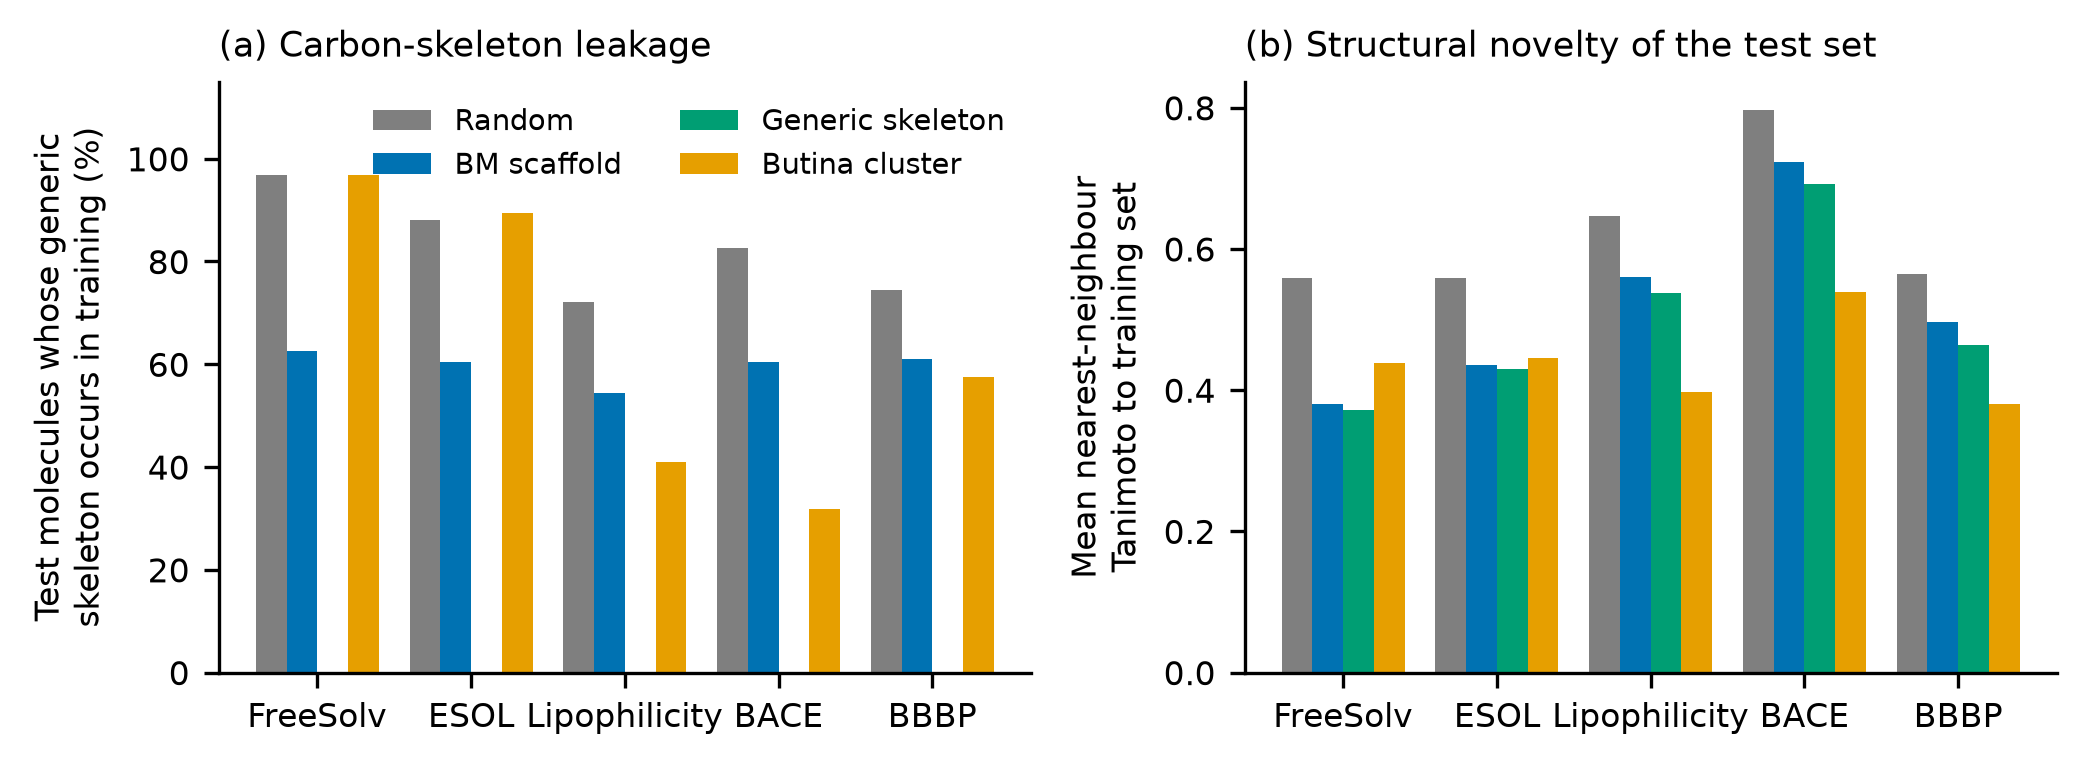

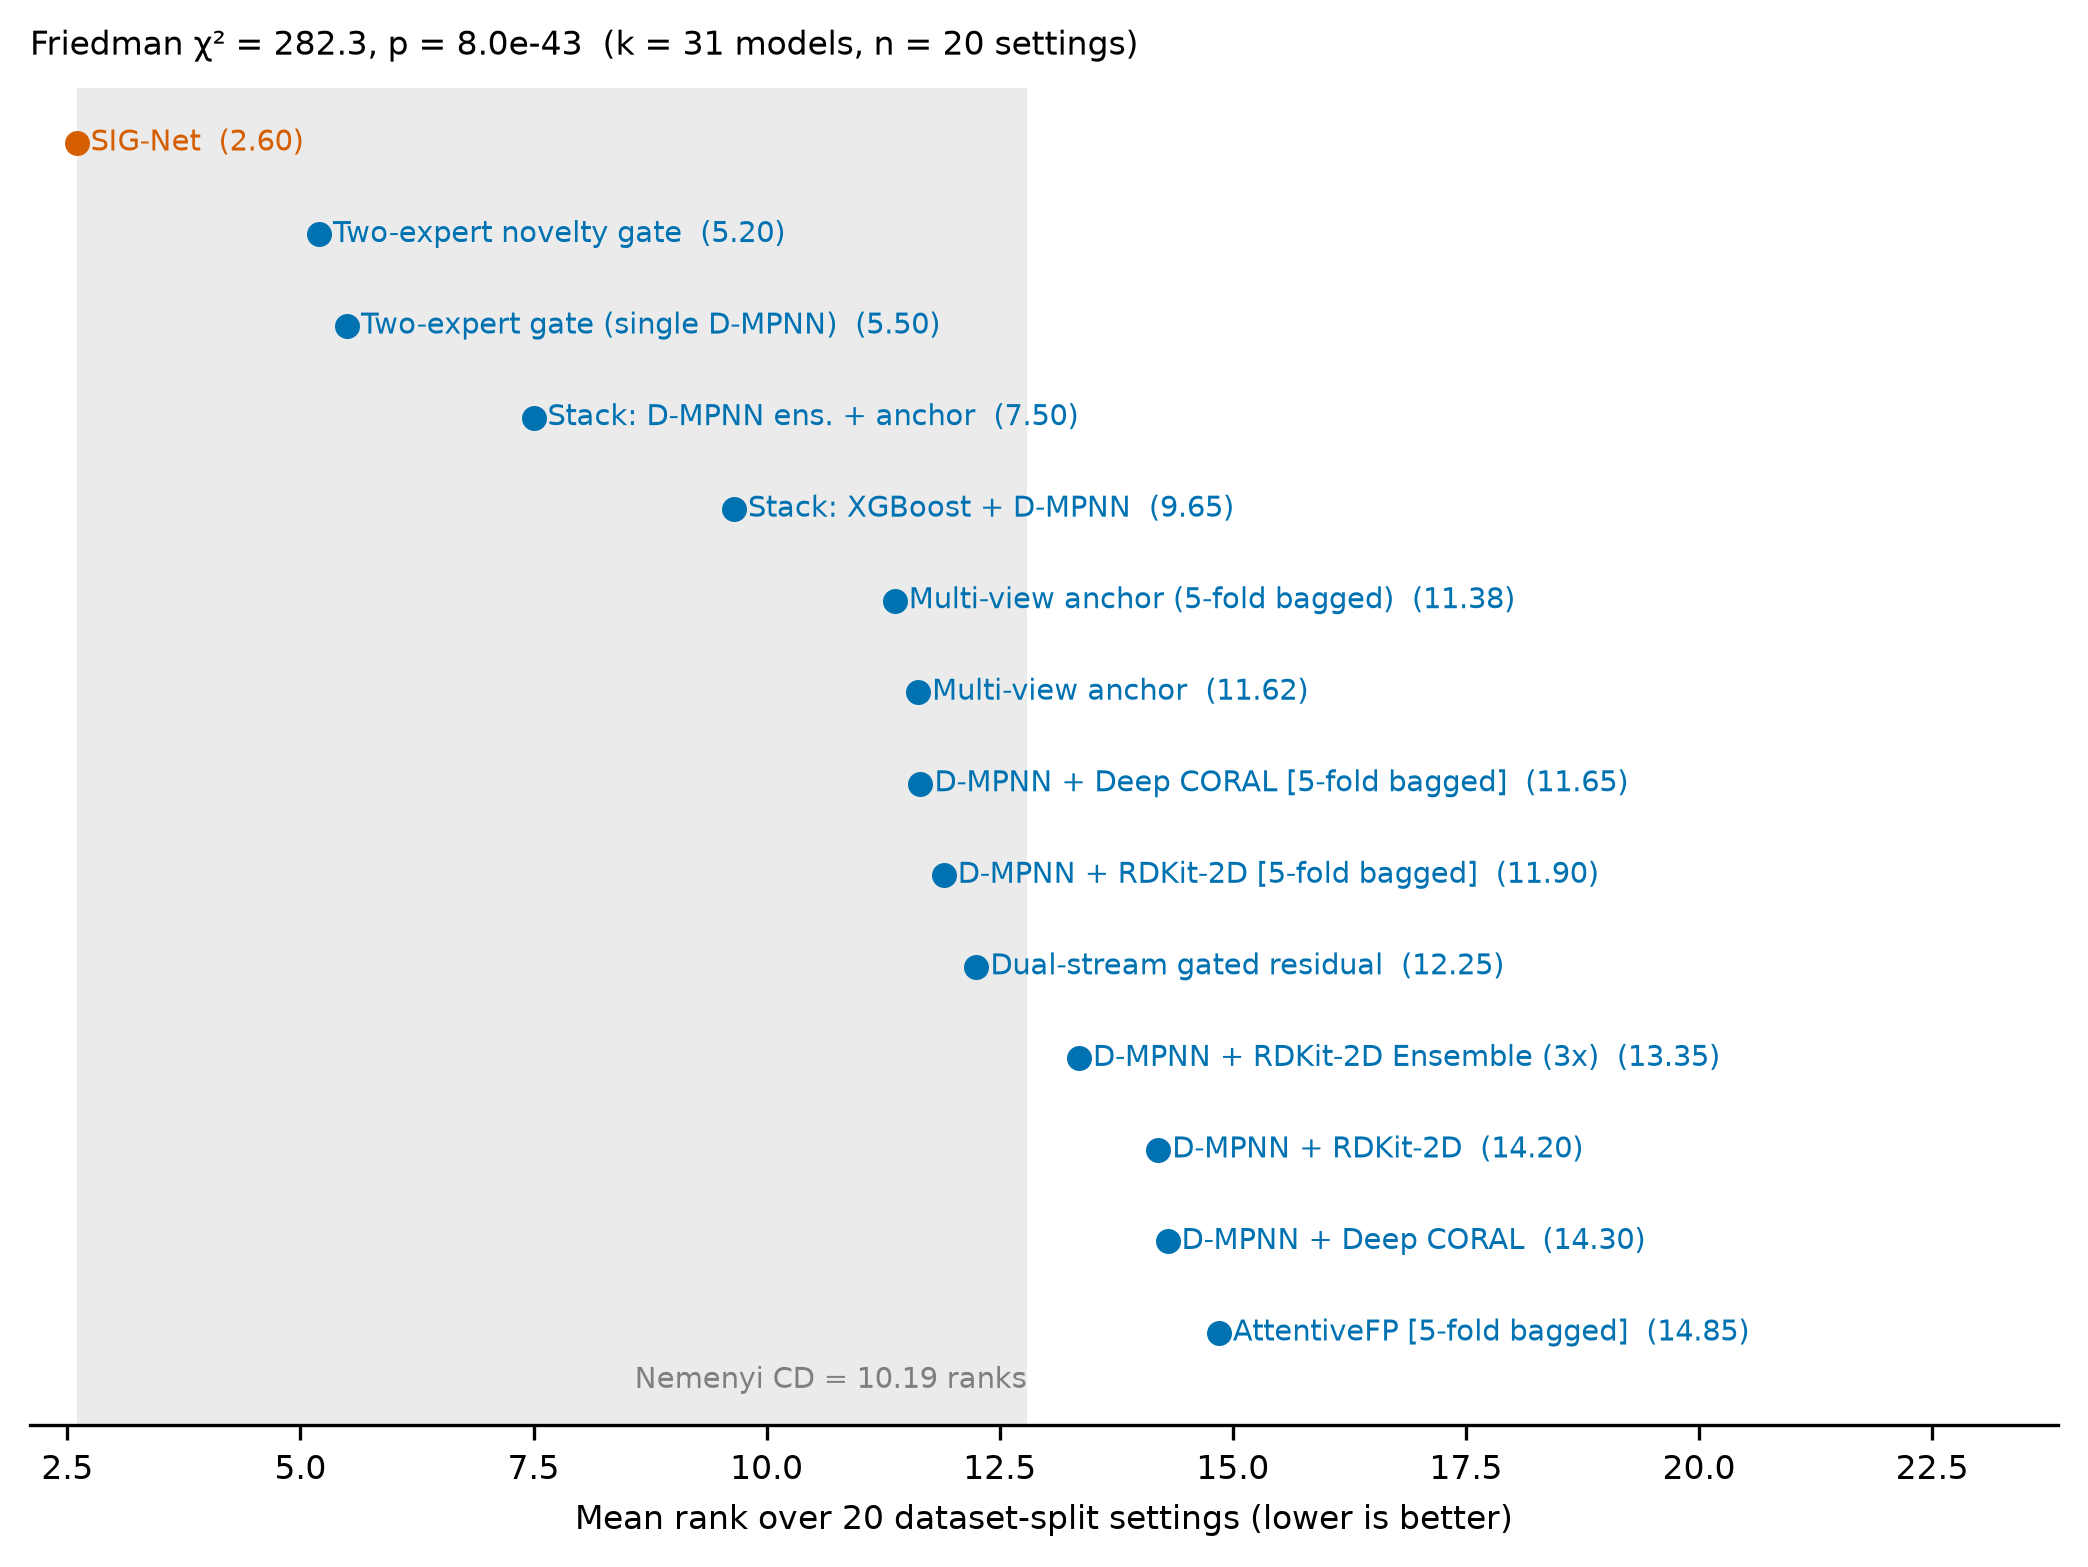

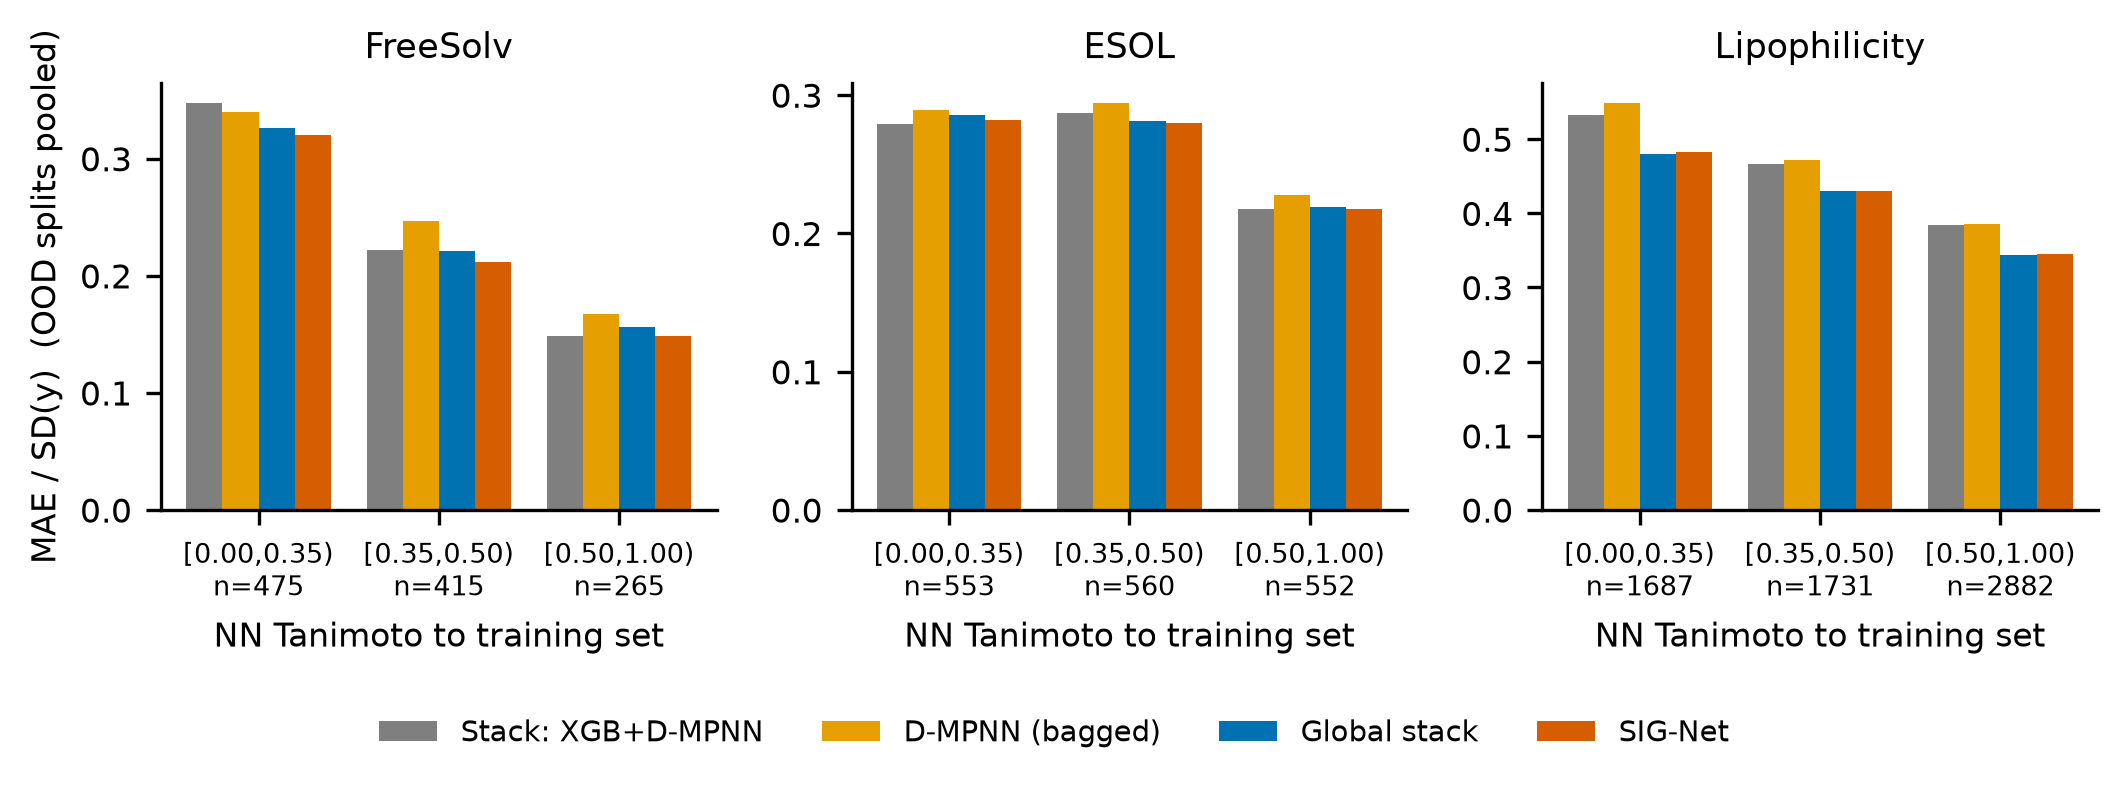

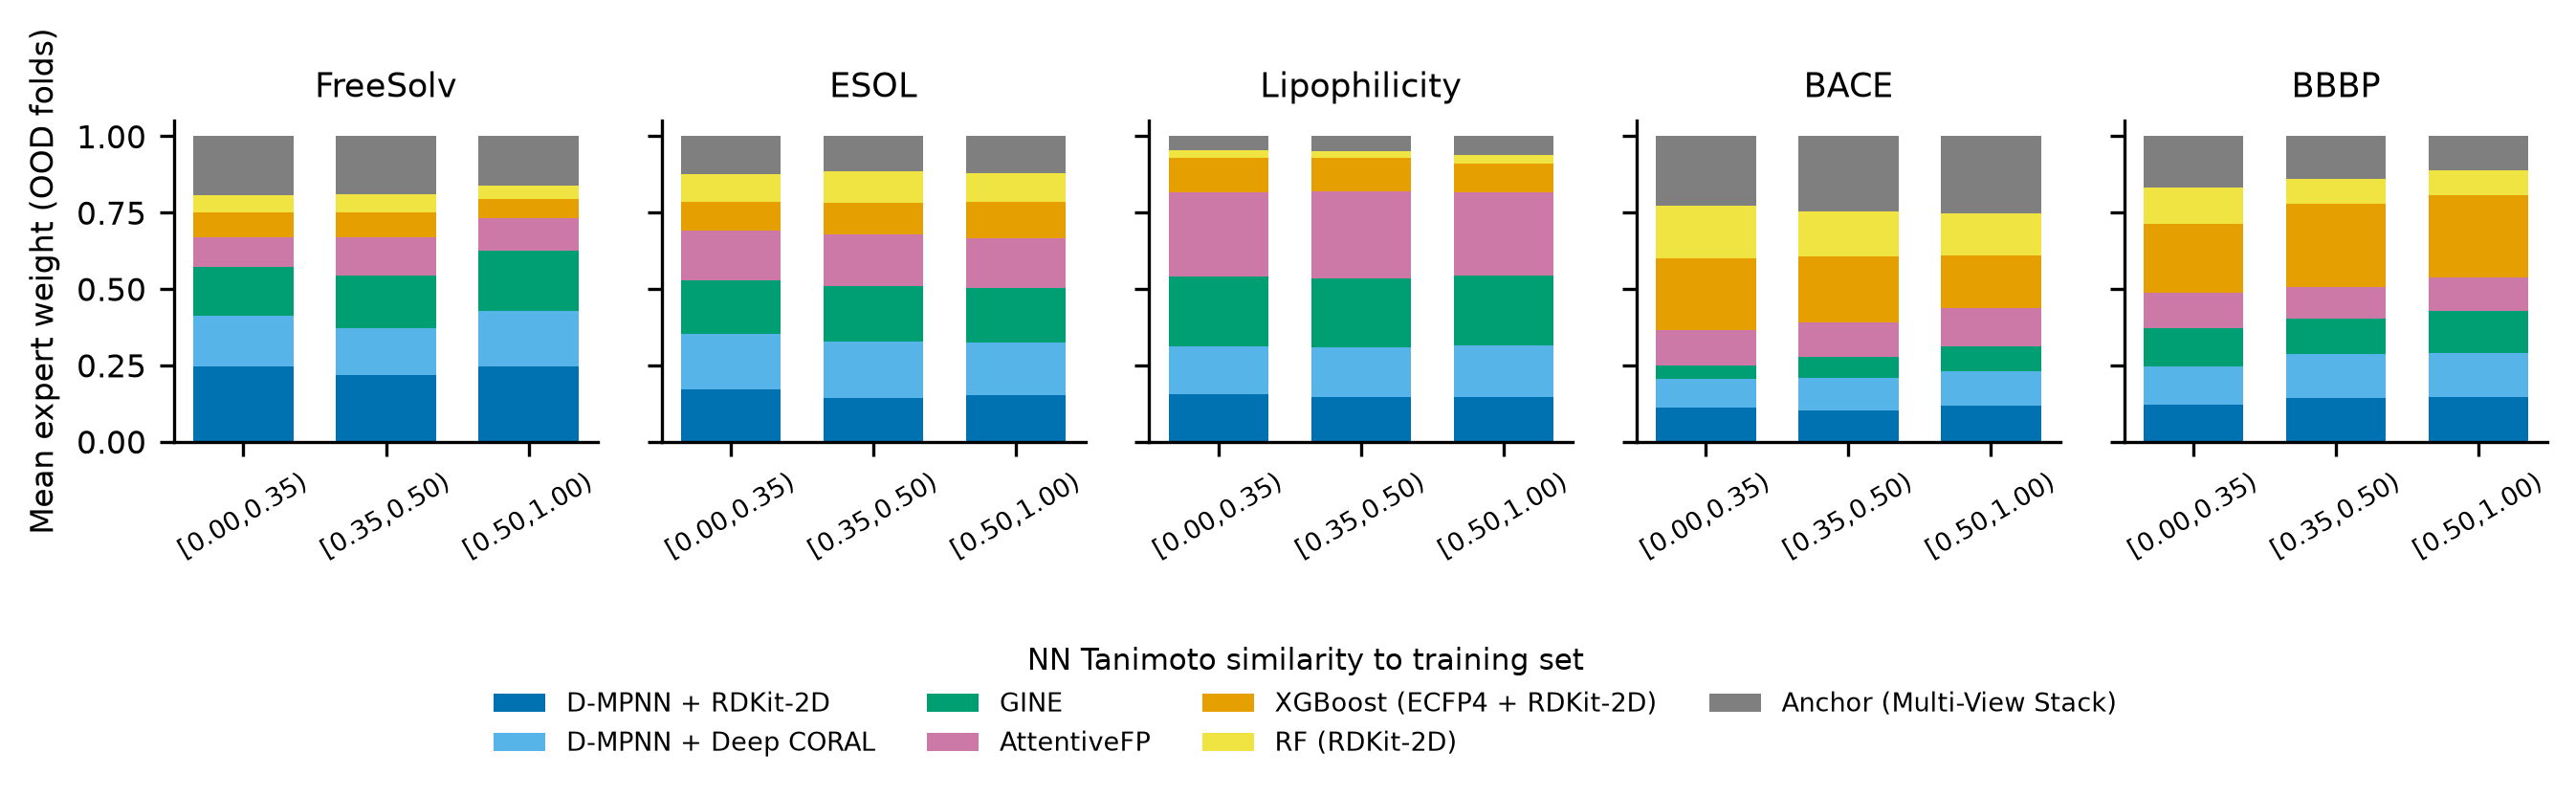

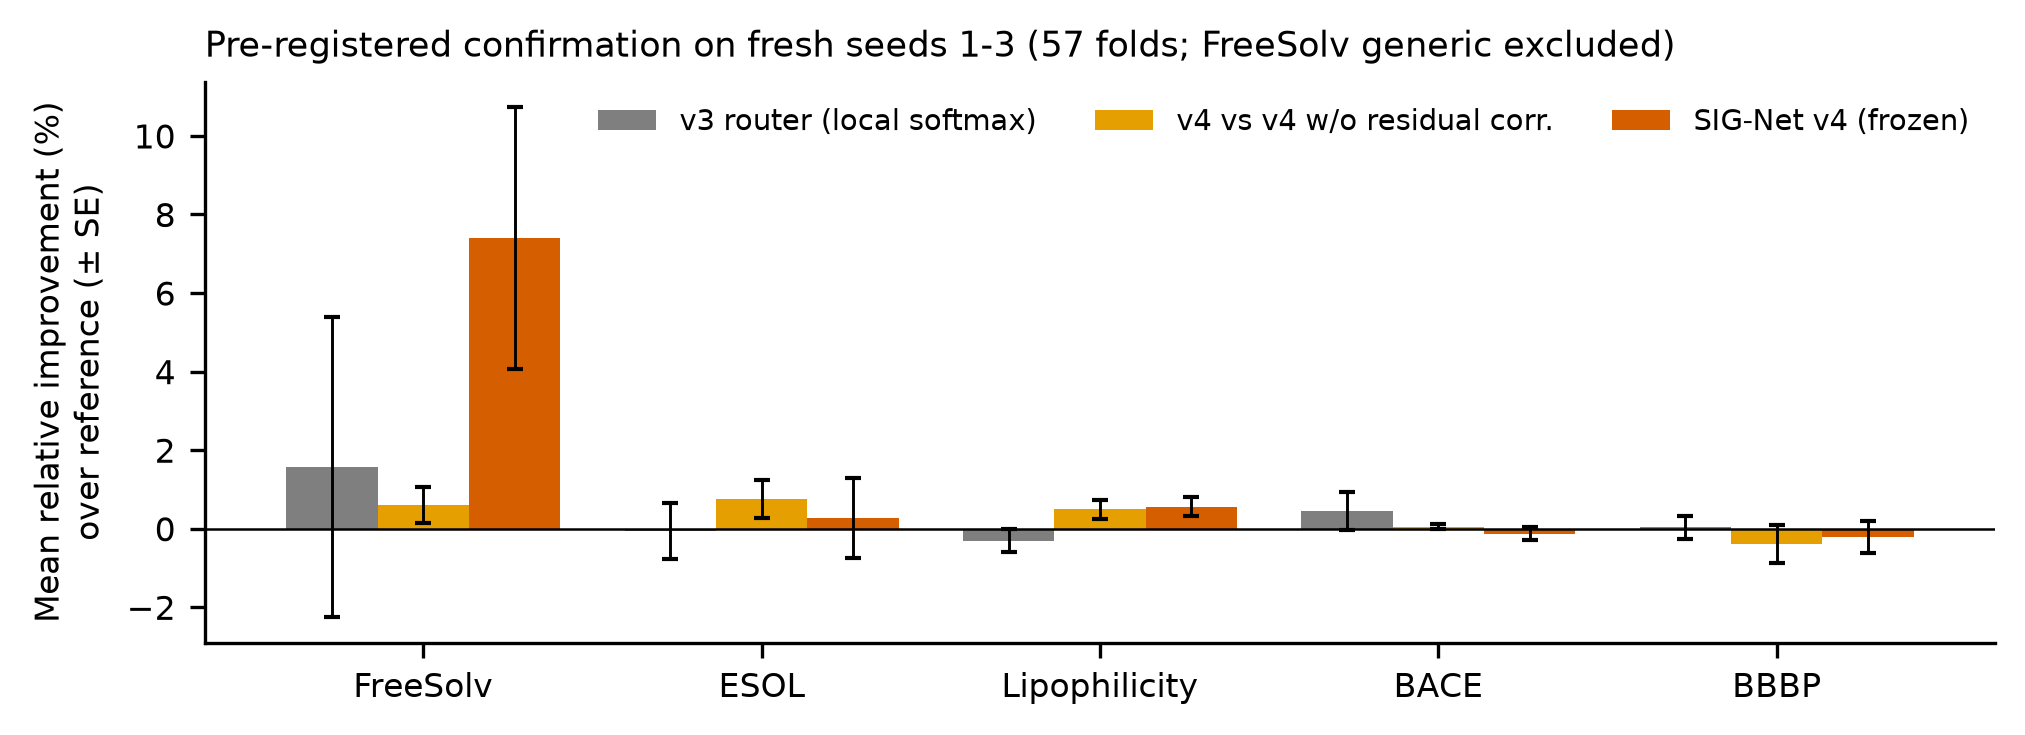

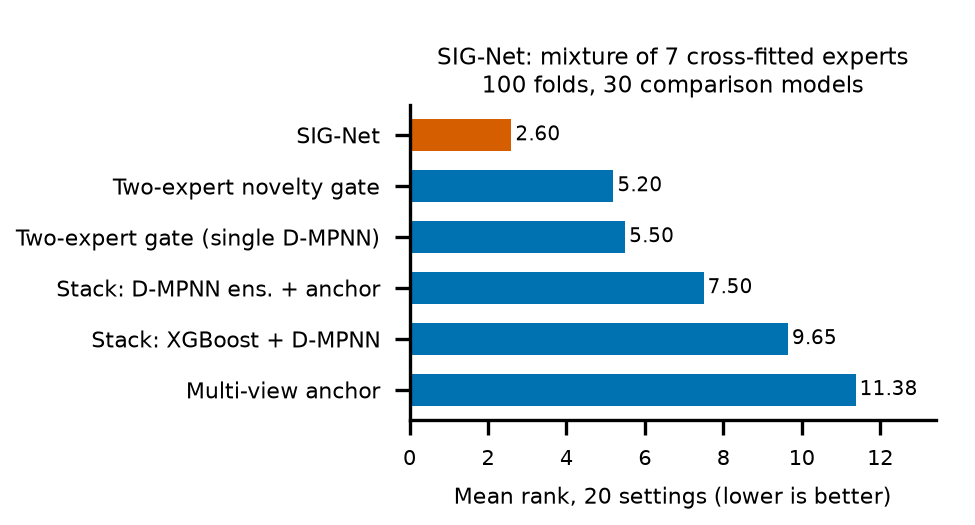

In [19]:
import importlib, report; importlib.reload(report)
N, T3, RK, H2H, PS, ABL = report.build()
import pandas as pd; pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(json.dumps({k: N[k] for k in ["n_folds", "n_models", "rank_overall", "rank_ood", "firsts", "second_model", "second_rank", "vs_global", "vs_xgbdmpnn", "vs_dmpnn", "vs_noshrink"]}, indent=1, default=float))
display(RK.head(12)); display(H2H.head(12)); display(ABL.round(3))
from IPython.display import Image
for f in sorted(os.listdir("results/final/figures")): display(Image(os.path.join("results/final/figures", f), width=760))

## 8b. Pre-registered confirmation on fresh splits (SIG-Net v4)

Fresh split seeds (development 11; confirmatory 1, 2, 3) are added with the identical splitting code; 9 cross-fitted experts are trained and their OOF/validation/test predictions saved; routers are applied to the saved matrices. The v4 design was chosen on seed 11 by a pre-registered rule and frozen (hashes in `results/v4_freeze_hashes.txt`) before the confirmatory folds were evaluated. Shipped expert files make this section run in minutes; missing folds are trained (GPU).

In [20]:
%%writefile add_seeds.py
"""Add fresh split seeds to the bundle with the identical Phase 1 splitting code (random / BM scaffold / generic
skeleton / Butina at Tanimoto distance 0.6, 80/10/10, large groups to train, small groups shuffled by seed).
Development seed 11; confirmatory seeds 1, 2, 3. Writes phase1_bundle_v3.pt."""
import sys, random
from collections import defaultdict
import numpy as np, torch
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import rdFingerprintGenerator
from rdkit.ML.Cluster import Butina
RDLogger.DisableLog("rdApp.*")

SRC = sys.argv[1] if len(sys.argv) > 1 else "data/phase1_bundle.pt"
DST = sys.argv[2] if len(sys.argv) > 2 else "data/phase1_bundle.pt"
NEW_SEEDS = [11, 1, 2, 3]
PROTOCOLS = ["random", "bm_scaffold", "generic_scaffold", "butina_cluster"]
MORGAN = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)


def assign_groups(groups, n_total, seed):
    big = [g for g in groups if len(g) > n_total * 0.05]; small = [g for g in groups if len(g) <= n_total * 0.05]
    random.Random(seed).shuffle(small); big.sort(key=len, reverse=True)
    tr, va, te = [], [], []; t_cut, v_cut = int(round(0.8 * n_total)), int(round(0.1 * n_total))
    for g in big + small:
        if len(tr) + len(g) <= t_cut: tr.extend(g)
        elif len(va) + len(g) <= v_cut: va.extend(g)
        else: te.extend(g)
    return tr, va, te


b = torch.load(SRC, map_location="cpu", weights_only=False)
for ds, feats in b["datasets"].items():
    n = len(feats); bm_g, gen_g = defaultdict(list), defaultdict(list)
    for i, d in enumerate(feats):
        bm_g[d.bm_scaffold].append(i); gen_g[d.gen_scaffold].append(i)
    fps = [MORGAN.GetFingerprint(Chem.MolFromSmiles(d.smiles)) for d in feats]
    dists = []
    for i in range(1, n): dists.extend([1 - s for s in DataStructs.BulkTanimotoSimilarity(fps[i], fps[:i])])
    butina = [list(c) for c in Butina.ClusterData(dists, n, 0.6, isDistData=True)]
    X = np.vstack([d.phys_raw.numpy() for d in feats])
    for proto in PROTOCOLS:
        for s in NEW_SEEDS:
            assert s not in b["splits"][ds][proto], f"seed {s} already exists for {ds} {proto}"
            if proto == "random":
                idx = list(range(n)); random.Random(s).shuffle(idx); nt, nv = int(round(0.8 * n)), int(round(0.1 * n)); tr, va, te = idx[:nt], idx[nt:nt + nv], idx[nt + nv:]
            elif proto == "bm_scaffold": tr, va, te = assign_groups(list(bm_g.values()), n, s)
            elif proto == "generic_scaffold": tr, va, te = assign_groups(list(gen_g.values()), n, s)
            else: tr, va, te = assign_groups(butina, n, s)
            b["splits"][ds][proto][s] = {"train": tr, "val": va, "test": te}
            Xt = X[tr]; mask = np.var(Xt, 0) > 1e-6
            if not mask.any(): mask[:] = True
            p01, p99 = np.percentile(Xt, 1, 0).astype(np.float32), np.percentile(Xt, 99, 0).astype(np.float32)
            Xc = np.clip(Xt, p01, p99); mean, std = Xc.mean(0).astype(np.float32), Xc.std(0).astype(np.float32); std[std < 1e-6] = 1
            b["fold_scalers"][ds][proto][s] = {"mean": mean, "std": std, "non_const_mask": mask, "p01": p01, "p99": p99}
    # overlap of new test sets with the original-seed test sets (how 'fresh' are they?)
    jac = []
    for proto in PROTOCOLS:
        old = [set(b["splits"][ds][proto][s]["test"]) for s in [42, 100, 2026, 7, 99]]
        for s in [1, 2, 3]:
            t = set(b["splits"][ds][proto][s]["test"]); jac.append(max(len(t & o) / len(t | o) for o in old))
    print(f"{ds:13s} new seeds added; max Jaccard of a confirmatory test set with any original test set: mean {np.mean(jac):.2f}, max {np.max(jac):.2f}", flush=True)
b["metadata"]["seeds_dev"] = [11]; b["metadata"]["seeds_confirmatory"] = [1, 2, 3]
torch.save(b, DST); print("wrote", DST)


Overwriting add_seeds.py


In [21]:
import torch
if 1 not in torch.load(os.environ["JCIM_BUNDLE"], map_location="cpu", weights_only=False)["splits"]["ESOL"]["random"]:
    get_ipython().run_line_magic("run", f"add_seeds.py {os.environ['JCIM_BUNDLE']} {os.environ['JCIM_BUNDLE']}")
else:
    print("fresh seeds present in bundle")

fresh seeds present in bundle


In [22]:
%%writefile run_experts.py
"""Expert worker for the v4 study: saves cross-fitted expert matrices per fold. Prints timings only (no test metrics),
so the confirmatory test results stay unseen until the v4 router is frozen. Lock files let several workers share the queue.
Usage: python run_experts.py <dataset> [<dataset> ...] [--seeds 11,1,2,3]"""
import os, sys, time, pickle, traceback
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from core_data import PROTOCOLS
from v3 import run_fold_experts

OUT = os.path.join(os.environ.get("JCIM_OUT", os.path.join(os.path.dirname(os.path.abspath(__file__)), "results")), "experts")
os.makedirs(OUT, exist_ok=True)
EPOCHS = int(os.environ.get("JCIM_EPOCHS", 80))
args = sys.argv[1:]; seeds = [11, 1, 2, 3]
if "--seeds" in args:
    i = args.index("--seeds"); seeds = [int(s) for s in args[i + 1].split(",")]; args = args[:i] + args[i + 2:]
jobs = [(ds, proto, s) for s in seeds for ds in args for proto in PROTOCOLS]
for ds, proto, s in jobs:
    path = os.path.join(OUT, f"{ds}__{proto}__{s}.pkl")
    if os.path.exists(path):
        continue
    try:
        os.close(os.open(path + ".lock", os.O_CREAT | os.O_EXCL))
    except FileExistsError:
        continue
    try:
        out = run_fold_experts(ds, proto, s, epochs=EPOCHS)
        pickle.dump(out, open(path, "wb"))
        print(f"[{time.strftime('%H:%M:%S')}] {ds:13s} {proto:16s} seed {s:3d} done in {out['meta']['time']:.0f}s", flush=True)
    except Exception:
        print(f"FAILED {ds} {proto} {s}\n{traceback.format_exc()}", flush=True)
    finally:
        if os.path.exists(path + ".lock"):
            os.remove(path + ".lock")
print("WORKER DONE", flush=True)


Overwriting run_experts.py


In [23]:
%%writefile routers.py
"""Routers applied to saved cross-fitted expert matrices (results/experts/*.pkl).

global : simplex weights minimising OOF loss on the whole training set (== min w' Sigma_glob w for squared loss)
v3     : SIG-Net v3 (local softmax competence on ECFP neighbours + novelty shrinkage), exact replica
v4     : SIG-Net v4 = local error-covariance routing + novelty-damped local residual correction:
           K(x,j)      = a*s_ecfp + (1-a)*(s_maccs + s_phys)/2                     (composite kernel)
           Sigma_loc(x)= sum_j w_j r_j r_j'   over the k nearest training molecules  (OOF residuals r_j, weights w_j ~ K^2)
           Sigma_hat(x)= lam(x) Sigma_loc(x) + (1-lam(x)) Sigma_glob,  lam(x) = sbar(x)^gamma   (shrinkage to global)
           w(x)        = argmin_{w in simplex} w' (Sigma_hat + rho tr(Sigma_hat)/M I) w
           delta(x)    = nu * sbar(x)^gamma_d * sum_j w_j (y_j - o(j)' w(x))          (local residual correction)
           y_hat(x)    = p(x)' w(x) + delta(x)
         with hyperparameters selected on the validation fold. Nothing uses the test fold.
"""
import os, glob, pickle
import numpy as np, torch
from scipy.optimize import minimize
from sklearn.metrics import roc_auc_score

ROOT = os.path.dirname(os.path.abspath(__file__))
EXPERTS_V3 = ["D-MPNN + RDKit-2D", "D-MPNN + Deep CORAL", "GINE", "AttentiveFP", "XGBoost (ECFP4 + RDKit-2D)", "RF (RDKit-2D)", "Anchor (Multi-View Stack)"]
EXPERTS_ALL = EXPERTS_V3 + ["ChemBERTa-2 + XGBoost", "XGBoost (ECFP4)"]
_B = None


def bundle():
    global _B
    if _B is None:
        _B = torch.load(os.environ.get("JCIM_BUNDLE", "data/phase1_bundle.pt"), map_location="cpu", weights_only=False)
    return _B


def score(y, p, task):
    if task == "regression":
        return float(np.sqrt(np.mean((y - p) ** 2)))
    return float(roc_auc_score(y.astype(int), np.clip(p, 1e-6, 1 - 1e-6))) if len(np.unique(y)) > 1 else 0.5


def better(a, b, task):
    return a < b if task == "regression" else a > b


def tanimoto(A, B):
    inter = A @ B.T; na = A.sum(1, keepdims=True); nb = B.sum(1, keepdims=True).T
    return inter / np.maximum(na + nb - inter, 1e-9)


def similarities(ds, proto, seed, idx):
    """ECFP, MACCS (Tanimoto) and physchem RBF similarities of val/test molecules to the training set."""
    data = bundle()["datasets"][ds]; sc = bundle()["fold_scalers"][ds][proto][seed]
    ecfp = np.vstack([d.ecfp4.numpy() for d in data]).astype(np.float32); maccs = np.vstack([d.maccs.numpy() for d in data]).astype(np.float32)
    raw = np.vstack([d.phys_raw.numpy() for d in data])
    phys = np.clip(np.nan_to_num(((np.clip(raw, sc["p01"], sc["p99"]) - sc["mean"]) / sc["std"])[:, sc["non_const_mask"]]), -10, 10).astype(np.float32)
    tr = np.array(idx["train"]); out = {}
    for part in ["val", "test"]:
        q = np.array(idx[part])
        d2 = (phys[q] ** 2).sum(1)[:, None] + (phys[tr] ** 2).sum(1)[None] - 2 * phys[q] @ phys[tr].T
        d = np.sqrt(np.maximum(d2, 0)); h = np.median(d) + 1e-9
        out[part] = {"ecfp": tanimoto(ecfp[q], ecfp[tr]), "maccs": tanimoto(maccs[q], maccs[tr]), "phys": np.exp(-0.5 * (d / h) ** 2)}
    return out


def simplex_fit(P, y, task):
    M = P.shape[1]
    loss = (lambda w: np.mean((y - P @ w) ** 2)) if task == "regression" else (lambda w: np.mean((y - np.clip(P @ w, 1e-4, 1 - 1e-4)) ** 2))
    r = minimize(lambda w: loss(w) + 1e-3 * np.sum((w - 1 / M) ** 2), np.ones(M) / M, bounds=[(0, 1)] * M,
                 constraints={"type": "eq", "fun": lambda w: w.sum() - 1}, method="SLSQP")
    return r.x if r.success else np.ones(M) / M


def proj_simplex(V):
    """Euclidean projection of each row of V onto the probability simplex."""
    n, M = V.shape; U = -np.sort(-V, axis=1); css = np.cumsum(U, axis=1) - 1
    ind = np.arange(1, M + 1); cond = U - css / ind > 0; rho = cond.cumsum(1).argmax(1)
    theta = css[np.arange(n), rho] / (rho + 1); return np.maximum(V - theta[:, None], 0)


def batched_simplex_qp(S, w0, iters=300):
    """min_w w'S w on the simplex for a batch of PSD matrices S [n,M,M] (projected gradient, step 1/L)."""
    L = np.linalg.eigvalsh(S)[:, -1] * 2 + 1e-12; w = w0.copy()
    for _ in range(iters):
        g = 2 * np.einsum("nij,nj->ni", S, w); w = proj_simplex(w - g / L[:, None])
    return w


class Fold:
    def __init__(self, path, experts):
        o = pickle.load(open(path, "rb")); self.o = o
        base = os.path.basename(path)[:-4]; self.ds, self.proto, s = base.split("__"); self.seed = int(s)
        self.task = o["meta"]["task"]; self.names = experts
        sd = o["meta"]["y_std"] if self.task == "regression" else 1.0; self.sd = sd
        g = lambda part: np.column_stack([o["experts"][n][part] for n in experts]).astype(np.float64)
        self.O, self.V, self.T = g("oof"), g("val"), g("test")
        self.y_tr, self.y_va, self.y_te = (o["y"][k].astype(np.float64) for k in ["train", "val", "test"])
        self.R = (self.y_tr[:, None] - self.O) / sd                  # standardised OOF residuals [N, M]
        self.S = similarities(self.ds, self.proto, self.seed, o["idx"])
        self.w_glob = simplex_fit(self.O, self.y_tr, self.task)
        self.Sig_glob = self.R.T @ self.R / len(self.R)


def neighbours(Sq, k):
    idx = np.argpartition(-Sq, k - 1, axis=1)[:, :k]; s = np.take_along_axis(Sq, idx, 1); return idx, s


def v4_predict(F, part, k, a, gamma, nu, gamma_d, rho=0.05, experts_mask=None):
    P = F.V if part == "val" else F.T; S = F.S[part]
    K = a * S["ecfp"] + (1 - a) * 0.5 * (S["maccs"] + S["phys"])
    idx, kv = neighbours(K, k); kv = np.maximum(kv, 1e-6); wn = kv ** 2 / (kv ** 2).sum(1, keepdims=True)
    sbar = np.take_along_axis(S["ecfp"], idx, 1).mean(1)                       # structural proximity (ECFP)
    M = F.O.shape[1]
    if gamma == "global":
        W = np.repeat(F.w_glob[None], len(P), 0)
    else:
        Rn = F.R[idx]                                                          # [n, k, M]
        Sloc = np.einsum("nk,nki,nkj->nij", wn, Rn, Rn)
        lam = (sbar ** gamma) if gamma > 0 else np.ones_like(sbar)
        Sh = lam[:, None, None] * Sloc + (1 - lam[:, None, None]) * F.Sig_glob[None]
        tr = np.trace(Sh, axis1=1, axis2=2) / M
        Sh = Sh + (rho * tr + 1e-8)[:, None, None] * np.eye(M)[None]
        W = batched_simplex_qp(Sh, np.repeat(F.w_glob[None], len(P), 0))
    pred = (P * W).sum(1)
    if nu > 0:
        loc_res = F.y_tr[idx] - np.einsum("nkm,nm->nk", F.O[idx], W)          # neighbours' OOF residual under w(x)
        pred = pred + nu * (sbar ** gamma_d) * (wn * loc_res).sum(1)
    if F.task != "regression":
        pred = np.clip(pred, 1e-6, 1 - 1e-6)
    return pred, W


GRID = {"k": [10, 25, 50], "a": [0.5, 0.75, 1.0], "gamma": [0.0, 0.5, 1.0, 2.0, 4.0, "global"], "nu": [0.0, 0.25, 0.5, 0.75], "gamma_d": [1.0, 2.0]}


def v4_select(F, grid=GRID, fixed=None):
    """Validation-only selection over the grid (or evaluation of a fixed configuration)."""
    cands = []
    for k in grid["k"]:
        for a in grid["a"]:
            for g in grid["gamma"]:
                for nu in grid["nu"]:
                    for gd in (grid["gamma_d"] if nu > 0 else [1.0]):
                        if g == "global" and (k != grid["k"][0] or a != grid["a"][0]) and nu == 0:
                            continue
                        cands.append((k, a, g, nu, gd))
    if fixed is not None:
        cands = [fixed]
    best, best_cfg = None, None
    for c in cands:
        s = score(F.y_va, v4_predict(F, "val", *c)[0], F.task)
        if best is None or better(s, best, F.task): best, best_cfg = s, c
    p, W = v4_predict(F, "test", *best_cfg)
    return {"test_preds": p, "weights": W, "config": best_cfg, "val_score": best}


def v3_predict(F, part, k, tau, gamma):
    """Exact replica of the SIG-Net v3 combination (softmax over neighbour-weighted squared OOF errors)."""
    P = F.V if part == "val" else F.T; S = F.S[part]["ecfp"]
    if gamma == "global":
        return P @ F.w_glob
    if F.task == "regression":
        E = ((F.O - F.y_tr[:, None]) / F.sd) ** 2
    else:
        E = (np.clip(F.O, 1e-4, 1 - 1e-4) - F.y_tr[:, None]) ** 2
    idx = np.argsort(-S, axis=1)[:, :k]; s = np.clip(np.take_along_axis(S, idx, 1), 1e-3, None)
    e = (s[..., None] * E[idx]).sum(1) / s.sum(1, keepdims=True); scale = np.median(e, 1, keepdims=True) + 1e-9
    z = -e / (tau * scale); z -= z.max(1, keepdims=True); wl = np.exp(z); wl /= wl.sum(1, keepdims=True)
    lam = s.mean(1, keepdims=True) ** gamma if gamma > 0 else np.ones((len(P), 1))
    W = lam * wl + (1 - lam) * F.w_glob[None]
    return (P * W).sum(1)


def v3_select(F):
    best, cfg = None, None
    for g in [0.0, 1.0, 2.0, 4.0, "global"]:
        for k in ([5, 10, 20, 50] if g != "global" else [5]):
            for tau in ([0.25, 0.5, 1.0, 2.0] if g != "global" else [0.25]):
                s = score(F.y_va, v3_predict(F, "val", k, tau, g), F.task)
                if best is None or better(s, best, F.task): best, cfg = s, (k, tau, g)
    return {"test_preds": v3_predict(F, "test", *cfg), "config": cfg, "val_score": best}


def v4_components(F, part, k, a, gamma, rho=0.05):
    """Weights and the pieces needed for any (nu, gamma_d); the QP is solved once per (k, a, gamma)."""
    P = F.V if part == "val" else F.T; S = F.S[part]
    K = a * S["ecfp"] + (1 - a) * 0.5 * (S["maccs"] + S["phys"])
    idx, kv = neighbours(K, k); kv = np.maximum(kv, 1e-6); wn = kv ** 2 / (kv ** 2).sum(1, keepdims=True)
    sbar = np.take_along_axis(S["ecfp"], idx, 1).mean(1); M = F.O.shape[1]
    if gamma == "global":
        W = np.repeat(F.w_glob[None], len(P), 0)
    else:
        Rn = F.R[idx]; Sloc = np.einsum("nk,nki,nkj->nij", wn, Rn, Rn)
        lam = (sbar ** gamma) if gamma > 0 else np.ones_like(sbar)
        Sh = lam[:, None, None] * Sloc + (1 - lam[:, None, None]) * F.Sig_glob[None]
        Sh = Sh + (rho * np.trace(Sh, axis1=1, axis2=2) / M + 1e-8)[:, None, None] * np.eye(M)[None]
        W = batched_simplex_qp(Sh, np.repeat(F.w_glob[None], len(P), 0))
    base = (P * W).sum(1)
    corr = (wn * (F.y_tr[idx] - np.einsum("nkm,nm->nk", F.O[idx], W))).sum(1)
    return base, corr, sbar, W


def v4_from_components(F, comp, nu, gamma_d):
    base, corr, sbar, W = comp; p = base + (nu * (sbar ** gamma_d) * corr if nu > 0 else 0.0)
    return np.clip(p, 1e-6, 1 - 1e-6) if F.task != "regression" else p


def v4_fast_select(F, grid=GRID, restrict=None):
    """Validation-only grid search. restrict: dict of fixed values (e.g. {'nu': [0.0]}) for ablations."""
    g = dict(grid); g.update(restrict or {})
    best, cfg = None, None
    for k in g["k"]:
        for a in g["a"]:
            for gam in g["gamma"]:
                if gam == "global" and (k, a) != (g["k"][0], g["a"][0]):
                    continue
                comp = v4_components(F, "val", k, a, gam)
                for nu in g["nu"]:
                    for gd in (g["gamma_d"] if nu > 0 else [1.0]):
                        s = score(F.y_va, v4_from_components(F, comp, nu, gd), F.task)
                        if best is None or better(s, best, F.task): best, cfg = s, (k, a, gam, nu, gd)
    k, a, gam, nu, gd = cfg; comp = v4_components(F, "test", k, a, gam)
    return {"test_preds": v4_from_components(F, comp, nu, gd), "weights": comp[3], "config": cfg, "val_score": best}


Overwriting routers.py


In [24]:
%%writefile dev_v4.py
"""Design evaluation of router variants on DEVELOPMENT folds only (seed 11). Never reads confirmatory seeds."""
import os, sys, glob, time, json
import numpy as np, pandas as pd
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from routers import *

files = sorted(set(p for d in ["experts_podD", "experts_podE", "experts"] for p in glob.glob(os.path.join(ROOT, "results", d, "*__11.pkl"))))
uniq = {}
for p in files: uniq[os.path.basename(p)] = p
rows = []
for name, p in sorted(uniq.items()):
    assert name.endswith("__11.pkl"), "development script must only read seed 11"
    t = time.time(); F9 = Fold(p, EXPERTS_ALL); F7 = Fold(p, EXPERTS_V3)
    res = {
        "Global stack (7)": F7.T @ F7.w_glob,
        "Global stack (9)": F9.T @ F9.w_glob,
        "v3 router (7)": v3_select(F7)["test_preds"],
        "v4 full (9)": v4_fast_select(F9)["test_preds"],
        "v4 full (7)": v4_fast_select(F7)["test_preds"],
        "v4 w/o residual corr (9)": v4_fast_select(F9, restrict={"nu": [0.0]})["test_preds"],
        "v4 w/o composite kernel (9)": v4_fast_select(F9, restrict={"a": [1.0]})["test_preds"],
        "v4 w/o novelty shrinkage (9)": v4_fast_select(F9, restrict={"gamma": [0.0, "global"], "gamma_d": [0.0]})["test_preds"],
    }
    for m, pred in res.items():
        rows.append({"Dataset": F9.ds, "Split": F9.proto, "Model": m, "score": score(F9.y_te, pred, F9.task), "task": F9.task})
    print(f"{F9.ds:13s} {F9.proto:16s} ({time.time()-t:.0f}s)", flush=True)
D = pd.DataFrame(rows); D.to_csv(os.path.join(ROOT, "results", "dev_v4_seed11.csv"), index=False)
ref = "Global stack (7)"
def rel(g):
    r = g.set_index("Model").score; lower = g.task.iloc[0] == "regression"; b = r[ref]
    return 100 * ((b - r) / b if lower else (r - b) / b)
R = D.groupby(["Dataset", "Split"]).apply(rel)
print(f"\nDEV (seed 11, {R.shape[0]} folds): relative improvement vs {ref} (%)  [positive = better]")
summ = pd.DataFrame({"mean": R.mean(), "median": R.median(), "wins": (R > 0).sum(), "losses": (R < 0).sum()}).sort_values("mean", ascending=False)
print(summ.round(3).to_string())
print("\nper dataset mean:"); print(R.groupby(level=0).mean().round(2).to_string())


Overwriting dev_v4.py


In [25]:
%%writefile confirm_v4.py
"""Confirmatory evaluation of the frozen SIG-Net v4 on seeds 1, 2, 3 (pre-registered in ANALYSIS_PLAN.md, Addendum 2).
Run only after the design freeze. Writes results/confirm_v4.csv and results/confirm_v4_summary.json."""
import os, sys, glob, json, time
import numpy as np, pandas as pd
from scipy import stats
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from routers import *

CONF_SEEDS = {1, 2, 3}
files = {}
for d in ["experts_podD", "experts_podE", "experts"]:
    for p in glob.glob(os.path.join(ROOT, "results", d, "*.pkl")):
        if int(os.path.basename(p)[:-4].split("__")[2]) in CONF_SEEDS:
            files[os.path.basename(p)] = p
print(len(files), "confirmatory folds found", flush=True)
rows = []
for name, p in sorted(files.items()):
    t = time.time(); F9 = Fold(p, EXPERTS_ALL); F7 = Fold(p, EXPERTS_V3)
    res = {"SIG-Net v4 (frozen)": v4_fast_select(F9)["test_preds"],
           "v4 w/o residual correction": v4_fast_select(F9, restrict={"nu": [0.0]})["test_preds"],
           "v4 w/o composite kernel": v4_fast_select(F9, restrict={"a": [1.0]})["test_preds"],
           "v4 w/o novelty shrinkage": v4_fast_select(F9, restrict={"gamma": [0.0, "global"], "gamma_d": [0.0]})["test_preds"],
           "SIG-Net v3 router (7)": v3_select(F7)["test_preds"],
           "Global stack (7)": F7.T @ F7.w_glob, "Global stack (9)": F9.T @ F9.w_glob}
    for j, n in enumerate(EXPERTS_ALL):
        res[f"{n} [5-fold bagged]"] = F9.T[:, j]
    for m, pr in res.items():
        rows.append({"Dataset": F9.ds, "Split": F9.proto, "Seed": F9.seed, "Model": m, "Task": F9.task, "Primary": score(F9.y_te, pr, F9.task)})
    print(f"{F9.ds:13s} {F9.proto:16s} seed {F9.seed} ({time.time()-t:.0f}s)", flush=True)
D = pd.DataFrame(rows); D.to_csv(os.path.join(ROOT, "results", "confirm_v4.csv"), index=False)


def h2h(D, a, b, exclude_freesolv_generic=True):
    rel = []
    for (ds, sp, s), g in D.groupby(["Dataset", "Split", "Seed"]):
        if exclude_freesolv_generic and ds == "FreeSolv" and sp == "generic_scaffold":
            continue
        m = g.set_index("Model").Primary; lower = g.Task.iloc[0] == "regression"
        rel.append(100 * ((m[b] - m[a]) / m[b] if lower else (m[a] - m[b]) / m[b]))
    rel = np.array(rel); w = stats.wilcoxon(rel, zero_method="zsplit")
    return {"n": len(rel), "wins": int((rel > 0).sum()), "mean": float(rel.mean()), "median": float(np.median(rel)), "p": float(w.pvalue)}


P = "SIG-Net v4 (frozen)"
summary = {"primary_vs_global7": h2h(D, P, "Global stack (7)")}
for b in ["SIG-Net v3 router (7)", "Global stack (9)", "v4 w/o residual correction", "v4 w/o composite kernel", "v4 w/o novelty shrinkage"] + [f"{n} [5-fold bagged]" for n in EXPERTS_ALL]:
    summary[f"vs {b}"] = h2h(D, P, b)
summary["v3_vs_global7"] = h2h(D, "SIG-Net v3 router (7)", "Global stack (7)")
summary["freesolv_generic_included_primary"] = h2h(D, P, "Global stack (7)", exclude_freesolv_generic=False)
json.dump(summary, open(os.path.join(ROOT, "results", "confirm_v4_summary.json"), "w"), indent=1)
for k, v in summary.items():
    print(f"{k:55s} n={v['n']:3d} wins={v['wins']:3d} mean={v['mean']:+.3f}% median={v['median']:+.3f}% p={v['p']:.2e}")


Overwriting confirm_v4.py


In [26]:
%%writefile report_v4.py
"""Confirmatory (fresh-seed) tables, numbers and figure for the manuscript. Reads results/confirm_v4.csv and
results/confirm_v4_summary.json (written by confirm_v4.py) and results/dev_v4_seed11_FROZEN.csv."""
import os, json
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from figures import OK

ROOT = os.path.dirname(os.path.abspath(__file__)); RES = os.path.join(ROOT, "results"); FINAL = os.path.join(RES, "final")
os.makedirs(os.path.join(FINAL, "figures"), exist_ok=True)
DS = ["FreeSolv", "ESOL", "Lipophilicity", "BACE", "BBBP"]


def rel_table(D, a, b):
    out = []
    for (ds, sp, s), g in D.groupby(["Dataset", "Split", "Seed"]):
        m = g.set_index("Model").Primary; lower = g.Task.iloc[0] == "regression"
        out.append({"Dataset": ds, "Split": sp, "Seed": s, "rel": 100 * ((m[b] - m[a]) / m[b] if lower else (m[a] - m[b]) / m[b])})
    return pd.DataFrame(out)


def build():
    D = pd.read_csv(os.path.join(RES, "confirm_v4.csv")); S = json.load(open(os.path.join(RES, "confirm_v4_summary.json")))
    Dx = D[~((D.Dataset == "FreeSolv") & (D.Split == "generic_scaffold"))]
    N = {"summary": S, "n_conf": int(S["primary_vs_global7"]["n"])}
    per = {}
    for key, a, b in [("v4_vs_global", "SIG-Net v4 (frozen)", "Global stack (7)"), ("v3_vs_global", "SIG-Net v3 router (7)", "Global stack (7)"),
                      ("v4_vs_nores", "SIG-Net v4 (frozen)", "v4 w/o residual correction")]:
        r = rel_table(Dx, a, b); per[key] = {d: {"mean": float(r[r.Dataset == d].rel.mean()), "wins": int((r[r.Dataset == d].rel > 0).sum()), "n": int((r.Dataset == d).sum())} for d in DS}
    N["per_dataset"] = per
    g = Dx.groupby(["Dataset", "Split", "Model", "Task"]).Primary.mean().reset_index(); ranks = []
    for (ds, sp), q in g.groupby(["Dataset", "Split"]):
        lower = q.Task.iloc[0] == "regression"; q = q.set_index("Model").Primary; ranks.append(q.rank(ascending=lower, method="average"))
    R = pd.concat(ranks, axis=1).mean(1).sort_values(); N["ranks"] = R.round(2).to_dict(); N["n_conf_settings"] = len(ranks)
    dev = pd.read_csv(os.path.join(RES, "dev_v4_seed11_FROZEN.csv")); ref = "Global stack (7)"; dv = []
    for (ds, sp), q in dev.groupby(["Dataset", "Split"]):
        m = q.set_index("Model").score; lower = q.task.iloc[0] == "regression"
        for mm in m.index: dv.append({"Model": mm, "rel": 100 * ((m[ref] - m[mm]) / m[ref] if lower else (m[mm] - m[ref]) / m[ref])})
    dv = pd.DataFrame(dv).groupby("Model").rel.agg(["mean", "median", lambda x: int((x > 0).sum())]); dv.columns = ["mean", "median", "wins"]
    N["dev"] = dv.round(3).to_dict(orient="index")
    json.dump(N, open(os.path.join(FINAL, "numbers_v4.json"), "w"), indent=1, default=float)
    # figure: per-dataset mean relative improvement over the global stack (confirmatory folds)
    fig, ax = plt.subplots(figsize=(6.8, 2.5)); x = np.arange(len(DS)); w = 0.27
    for j, (key, lab, col) in enumerate([("v3_vs_global", "v3 router (local softmax)", OK["grey"]), ("v4_vs_nores", "v4 vs v4 w/o residual corr.", OK["orange"]), ("v4_vs_global", "SIG-Net v4 (frozen)", OK["red"])]):
        r = rel_table(Dx, *{"v4_vs_global": ("SIG-Net v4 (frozen)", "Global stack (7)"), "v3_vs_global": ("SIG-Net v3 router (7)", "Global stack (7)"),
                            "v4_vs_nores": ("SIG-Net v4 (frozen)", "v4 w/o residual correction")}[key])
        m = [r[r.Dataset == d].rel.mean() for d in DS]; se = [r[r.Dataset == d].rel.std(ddof=1) / np.sqrt((r.Dataset == d).sum()) for d in DS]
        ax.bar(x + (j - 1) * w, m, w, yerr=se, color=col, label=lab, capsize=2, error_kw={"lw": 0.7})
    ax.axhline(0, color="k", lw=0.6); ax.set_xticks(x); ax.set_xticklabels(DS)
    ax.set_ylabel("Mean relative improvement (%)\nover reference (± SE)"); ax.legend(frameon=False, fontsize=7, ncol=3, loc="upper right")
    ax.set_title(f"Pre-registered confirmation on fresh seeds 1-3 ({N['n_conf']} folds; FreeSolv generic excluded)", loc="left", fontsize=8.5)
    fig.tight_layout(); fig.savefig(os.path.join(FINAL, "figures", "fig5_confirmatory.png"), dpi=300, bbox_inches="tight"); plt.close(fig)
    return N


if __name__ == "__main__":
    N = build(); print(json.dumps({k: N[k] for k in ["n_conf", "n_conf_settings", "per_dataset"]}, indent=1, default=float)[:2500])


Overwriting report_v4.py


expert files: 80


BACE          bm_scaffold      (6s)


BACE          butina_cluster   (4s)


BACE          generic_scaffold (4s)


BACE          random           (4s)


...

Lipophilicity generic_scaffold seed 3 (7s)


Lipophilicity random           seed 1 (7s)


Lipophilicity random           seed 2 (7s)


Lipophilicity random           seed 3 (7s)


primary_vs_global7                                      n= 57 wins= 35 mean=+1.268% median=+0.197% p=1.97e-02
vs SIG-Net v3 router (7)                                n= 57 wins= 34 mean=+0.911% median=+0.188% p=1.17e-01
vs Global stack (9)                                     n= 57 wins= 34 mean=+1.344% median=+0.212% p=1.87e-02
vs v4 w/o residual correction                           n= 57 wins= 29 mean=+0.287% median=+0.008% p=1.55e-02
vs v4 w/o composite kernel                              n= 57 wins= 17 mean=+0.383% median=+0.000% p=8.57e-01
vs v4 w/o novelty shrinkage                             n= 57 wins= 22 mean=+0.017% median=+0.000% p=6.33e-01
vs D-MPNN + RDKit-2D [5-fold bagged]                    n= 57 wins= 48 mean=+5.099% median=+2.431% p=7.28e-07
vs D-MPNN + Deep CORAL [5-fold bagged]                  n= 57 wins= 46 mean=+5.538% median=+3.780% p=4.08e-07
vs GINE [5-fold bagged]                                 n= 57 wins= 45 mean=+5.698% median=+4.758% p=1.88e-05
vs Attenti

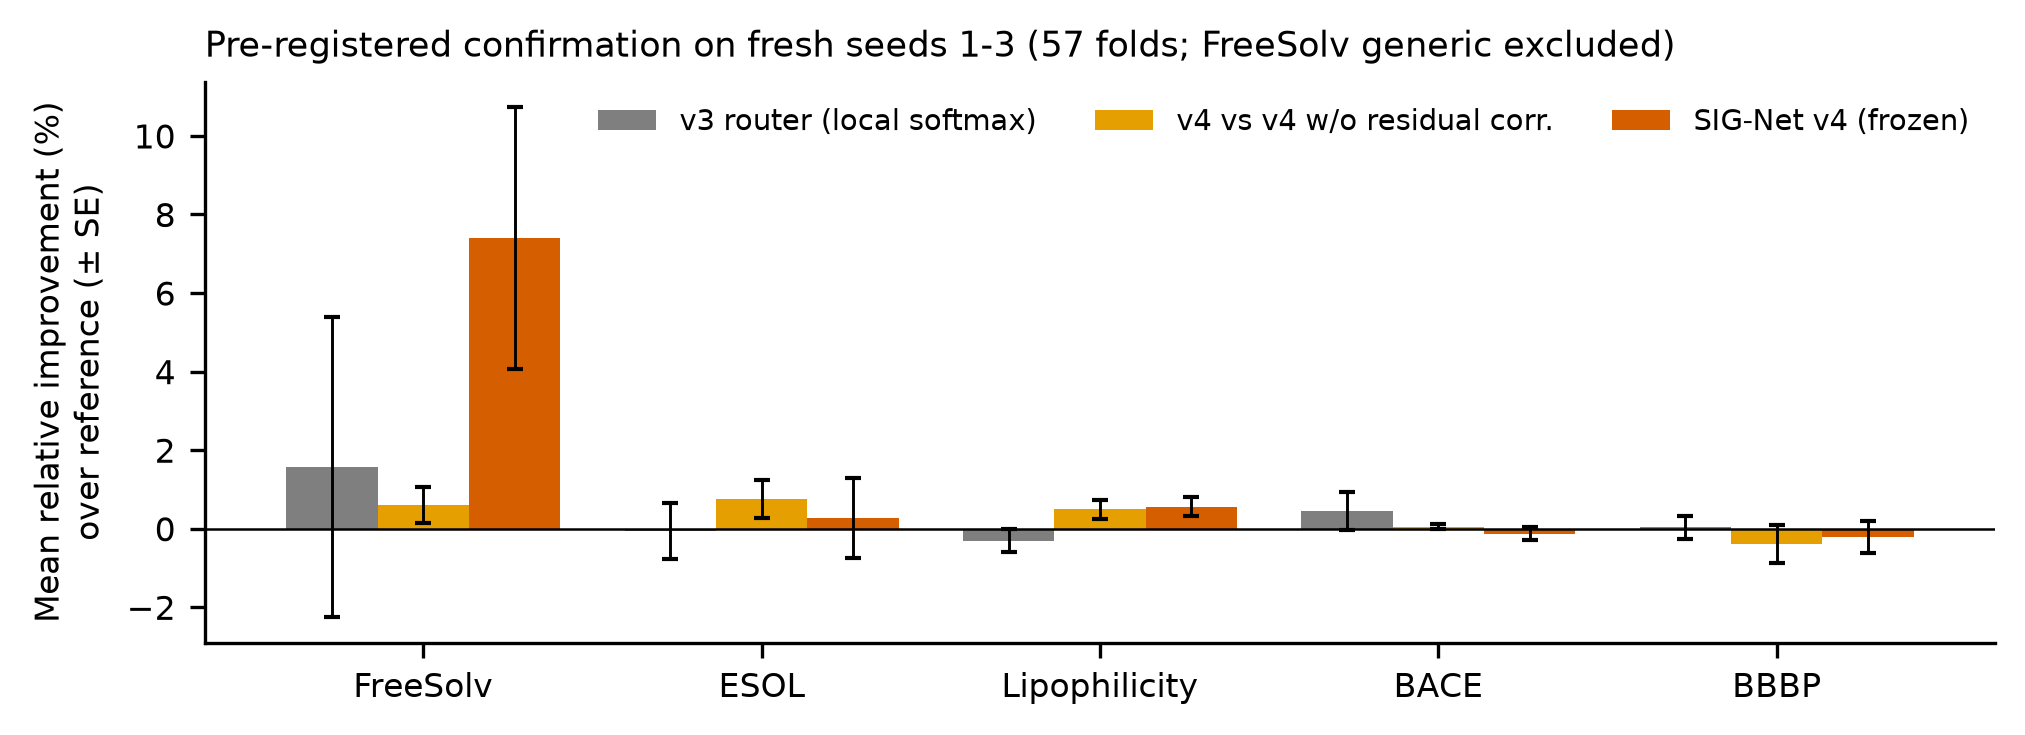

In [27]:
import v3 as V3
from core_data import DATASET_CFG, PROTOCOLS
os.makedirs("results/experts", exist_ok=True)
if RUN_TRAINING:
    for s in [11, 1, 2, 3]:
        for ds in DATASET_CFG:
            for proto in PROTOCOLS:
                path = f"results/experts/{ds}__{proto}__{s}.pkl"
                if not os.path.exists(path):
                    out = V3.run_fold_experts(ds, proto, s); pickle.dump(out, open(path, "wb")); print("trained", ds, proto, s, flush=True)
print("expert files:", len(os.listdir("results/experts")))
get_ipython().run_line_magic("run", "dev_v4.py")
print(open("results/v4_freeze_hashes.txt").read())
get_ipython().run_line_magic("run", "confirm_v4.py")
import importlib, report_v4; importlib.reload(report_v4); N4 = report_v4.build()
display(Image("results/final/figures/fig5_confirmatory.png", width=760))

## 9. Manuscript and Supporting Information

In [28]:
%%writefile manuscript/methods_v3.tex
\section{Methods}

\subsection{Datasets and curation}
We use five MoleculeNet benchmarks\cite{wu2018moleculenet}: hydration free energy (\texttt{FreeSolv}\cite{mobley2014freesolv}), aqueous solubility (\texttt{ESOL}\cite{delaney2004esol}), octanol/water distribution at pH 7.4 (\texttt{Lipophilicity}), $\beta$-secretase inhibition (\texttt{BACE}\cite{subramanian2016bace}) and blood--brain barrier penetration (\texttt{BBBP}\cite{martins2012bbbp}). Structures were standardised with RDKit\cite{rdkit} (largest-fragment selection, neutralisation, canonical isomeric SMILES) and indexed by InChIKey. Duplicates with consistent labels ($\Delta y \le 0.2\,\sigma_y$, or identical class) were merged; conflicting duplicates were removed (Table~\ref{tab:datasets}).

\subsection{Splitting protocols}
Each dataset was split 80/10/10 into training, validation and test sets under four protocols, each with five seeds (42, 100, 2026, 7, 99): \emph{random}; \emph{BM scaffold}\cite{bemis1996properties}, grouping molecules by their heavy-atom ring-and-linker framework; \emph{generic skeleton}, grouping by that framework after converting all atoms to carbon and all bonds to single bonds; and \emph{Butina cluster}\cite{butina1999unsupervised}, sphere-exclusion clustering of 2048-bit Morgan (ECFP4\cite{rogers2010extended}) fingerprints at Tanimoto distance 0.6. Grouped protocols assign groups larger than 5\% of the data to the training set and shuffle the remaining groups by seed. For each split we computed scaffold and skeleton overlap, the fraction of test molecules whose generic skeleton occurs in the training set, and the nearest-neighbour (NN) Tanimoto similarity of each test molecule to the training set.

\subsection{Featurisation}
Graph models use one-hot atom features (atomic number, degree, formal charge, chirality, hydrogen count, hybridisation, aromaticity, scaled mass; 133 dimensions) and bond features (type, conjugation, ring membership, stereochemistry; 14 dimensions) following Chemprop\cite{yang2019analyzing,heid2024chemprop}. Descriptor models use 2D RDKit descriptors clipped to the training-fold 1st--99th percentiles and standardised on the training fold, 167-bit MACCS keys\cite{durant2002reoptimization} and ECFP4 bits. All scaling, clipping and PCA statistics are fitted on the training fold only.

\subsection{Comparison models}
We evaluate random forests and XGBoost on ECFP4, MACCS, RDKit-2D and ECFP4+RDKit-2D; a gated residual MLP on ECFP4+RDKit-2D; GCN\cite{kipf2017semi}, GINE\cite{xu2019powerful}, GATv2\cite{brody2022attentive} and AttentiveFP\cite{xiong2020pushing}; D-MPNN\cite{yang2019analyzing} with and without RDKit-2D features; D-MPNN with a Deep CORAL\cite{sun2016deep} feature-alignment penalty as a domain-invariance baseline; a three-seed D-MPNN+RDKit ensemble\cite{lakshminarayanan2017simple}; two pretrained-foundation-model baselines that use frozen, mean-pooled embeddings of the chemical language model ChemBERTa-2 (77M parameters, multi-task-regression pretraining\cite{ahmad2022chemberta2}) with a ridge (logistic for classification) head whose regularisation is chosen on the validation fold, or an XGBoost head with early stopping on the validation fold; five-fold cross-fitted (bagged) versions of each SIG-Net expert; a multi-view descriptor stack (below); two stacking baselines that combine two models with a single validation-selected weight; and two earlier designs from our group, a dual-stream gated residual network and a two-expert novelty gate. Neural models use standardised regression targets, AdamW with a one-cycle learning-rate schedule for 80 epochs, and the checkpoint with the best validation score. Tree models use fixed hyperparameters; XGBoost in the baselines uses early stopping on the validation fold.

\subsection{Multi-view descriptor stack}
Five learners are fitted on the training fold---random forests on MACCS and RDKit-2D, ridge (logistic for classification) regression on all descriptor views, and XGBoost on RDKit-2D and on ECFP4+RDKit-2D (ECFP4 for classification)---and combined with non-negative weights summing to one, fitted on the validation fold. Out-of-fold training-set predictions of this stack are obtained by three-fold scaffold-grouped cross-fitting.

\subsection{SIG-Net}
\paragraph{Experts and cross-fitting.} SIG-Net combines $M = 7$ experts: D-MPNN+RDKit, D-MPNN+RDKit with Deep CORAL, GINE, AttentiveFP, XGBoost on ECFP4+RDKit-2D, a random forest on RDKit-2D, and the multi-view descriptor stack. The training set is divided into $K = 5$ scaffold-grouped folds. Each expert $m$ is trained $K$ times, each time on $K-1$ folds, which gives an out-of-fold prediction $o_m(j)$ for every training molecule $j$. Validation and test predictions $p_m(x)$ are the means of the $K$ models.

\paragraph{Global weights.} Non-negative weights $\mathbf{w}^{\mathrm{glob}}$ summing to one are fitted by minimising the squared error of $\sum_m w_m o_m(j)$ on all training molecules (Brier score for classification).

\paragraph{Local competence.} For a query molecule $x$ let $\mathcal{N}_k(x)$ be its $k$ most similar training molecules (ECFP4 Tanimoto similarity $s_j$). The local error of expert $m$ is
\begin{equation}
e_m(x) = \frac{\sum_{j \in \mathcal{N}_k(x)} s_j\,\bigl(y_j - o_m(j)\bigr)^2}{\sum_{j \in \mathcal{N}_k(x)} s_j},
\end{equation}
with targets standardised for regression, and the local weights are $w^{\mathrm{loc}}_m(x) \propto \exp\!\bigl(-e_m(x) / (\tau\,\tilde{e}(x))\bigr)$, where $\tilde{e}(x)$ is the median of $e_m(x)$ over experts.

\paragraph{Novelty shrinkage.} The final weights interpolate between local and global weights according to the mean neighbour similarity $\bar{s}_k(x)$:
\begin{equation}
\mathbf{w}(x) = \lambda(x)\,\mathbf{w}^{\mathrm{loc}}(x) + \bigl(1 - \lambda(x)\bigr)\,\mathbf{w}^{\mathrm{glob}}, \qquad \lambda(x) = \bar{s}_k(x)^{\gamma},
\end{equation}
and the prediction is $\hat{y}(x) = \sum_m w_m(x)\,p_m(x)$.

\paragraph{Model selection.} The neighbourhood size $k \in \{5, 10, 20, 50\}$, temperature $\tau \in \{0.25, 0.5, 1, 2\}$ and shrinkage exponent $\gamma \in \{0, 1, 2, 4\}$, together with the purely global combination, are selected per fold by the validation score. The test fold is not used for any fitting or selection step. The overall design (expert set, $K$ and the grids) was fixed using validation scores on three development folds before the final run.

\subsection{Refined router (SIG-Net v4) and confirmatory design}
To address the limitations of the softmax router we developed a second router, evaluated only on fresh splits. Let $r_j \in \mathbb{R}^M$ be the standardised out-of-fold residuals of the $M$ experts on training molecule $j$, and $\boldsymbol{\Sigma}_{\mathrm{glob}} = N^{-1}\sum_j r_j r_j^\top$. For a query $x$, neighbours are taken under a composite kernel $K(x,j) = a\,s_{\mathrm{ECFP}} + (1-a)\,(s_{\mathrm{MACCS}} + s_{\mathrm{phys}})/2$, where $s_{\mathrm{phys}}$ is an RBF kernel on standardised RDKit descriptors (median-distance bandwidth). With neighbour weights $\omega_j \propto K(x,j)^2$ over the $k$ nearest training molecules,
\begin{equation}
\hat{\boldsymbol{\Sigma}}(x) = \lambda(x)\sum_{j \in \mathcal{N}_k(x)} \omega_j r_j r_j^\top + \bigl(1-\lambda(x)\bigr)\boldsymbol{\Sigma}_{\mathrm{glob}}, \qquad \lambda(x) = \bar{s}_k(x)^{\gamma},
\end{equation}
\begin{equation}
\begin{aligned}
\mathbf{w}(x) &= \arg\min_{\mathbf{w} \in \Delta^{M-1}} \mathbf{w}^\top \bigl(\hat{\boldsymbol{\Sigma}}(x) + \rho\,\mathrm{tr}(\hat{\boldsymbol{\Sigma}}(x))\,\mathbf{I}/M\bigr)\,\mathbf{w}, \\
\hat{y}(x) &= \mathbf{w}(x)^\top \mathbf{p}(x) + \nu\,\bar{s}_k(x)^{\gamma_d} \sum_{j \in \mathcal{N}_k(x)} \omega_j \bigl(y_j - \mathbf{w}(x)^\top \mathbf{o}(j)\bigr),
\end{aligned}
\end{equation}
where $\bar{s}_k(x)$ is the mean ECFP similarity of the neighbours and $\mathbf{o}(j)$ the out-of-fold expert predictions. For squared loss the global stack solves the same problem with $\boldsymbol{\Sigma}_{\mathrm{glob}}$, so it is the special case $\lambda = 0$, $\nu = 0$. The weights are computed by projected gradient descent on the simplex; $k \in \{10, 25, 50\}$, $a \in \{0.5, 0.75, 1\}$, $\gamma \in \{0, 0.5, 1, 2, 4\}$ (or the global weights), $\nu \in \{0, 0.25, 0.5, 0.75\}$ and $\gamma_d \in \{1, 2\}$ are selected per fold on the validation set, with $\rho = 0.05$.

The confirmation used new split seeds (development seed 11; confirmatory seeds 1--3) produced by the same splitting code, and nine cross-fitted experts (the seven SIG-Net experts, ChemBERTa-2 + XGBoost and XGBoost on ECFP4) whose out-of-fold, validation and test predictions were stored. The v4 variant (7 or 9 experts, with or without each component) was chosen on the development seed by a rule fixed beforehand; the design was then frozen (file hashes recorded) before any confirmatory result was computed. The primary endpoint---SIG-Net v4 vs.\ the global stack of the seven original experts over all confirmatory folds except the degenerate \texttt{FreeSolv} generic-skeleton split---and the secondary comparisons were registered in advance (Supporting Information).

\subsection{Evaluation and statistics}
Regression tasks are scored by test RMSE and the classification tasks (\texttt{BACE}, \texttt{BBBP}) by ROC-AUC. Each of the 20 dataset--protocol settings is run with five seeds (100 folds per model). We report mean $\pm$ SD over seeds; mean ranks across the 20 settings with a Friedman test and Nemenyi critical difference\cite{demsar2006statistical}; and paired comparisons over all 100 folds using the two-sided Wilcoxon signed-rank test on the per-fold relative improvement. The primary comparison and all secondary analyses were specified in an analysis plan written before the final test results were viewed; \texttt{BBBP} and the ChemBERTa-2 baselines were added later, under a written addendum made before their results were viewed (Supporting Information). Per-setting paired $t$-tests over five seeds are reported as descriptive statistics.


Overwriting manuscript/methods_v3.tex


In [29]:
%%writefile manuscript/refs.bib
@article{wu2018moleculenet, author={Wu, Zhenqin and Ramsundar, Bharath and Feinberg, Evan N. and Gomes, Joseph and Geniesse, Caleb and Pappu, Aneesh S. and Leswing, Karl and Pande, Vijay}, title={MoleculeNet: A Benchmark for Molecular Machine Learning}, journal={Chem. Sci.}, year={2018}, volume={9}, pages={513--530}, doi={10.1039/C7SC02664A}}
@article{yang2019analyzing, author={Yang, Kevin and Swanson, Kyle and Jin, Wengong and Coley, Connor and Eiden, Philipp and Gao, Hua and Guzman-Perez, Angel and Hopper, Timothy and Kelley, Brian and Mathea, Miriam and Palmer, Andrew and Settels, Volker and Jaakkola, Tommi and Jensen, Klavs and Barzilay, Regina}, title={Analyzing Learned Molecular Representations for Property Prediction}, journal={J. Chem. Inf. Model.}, year={2019}, volume={59}, pages={3370--3388}, doi={10.1021/acs.jcim.9b00237}}
@article{heid2024chemprop, author={Heid, Esther and Greenman, Kevin P. and Chung, Yunsie and Li, Shih-Cheng and Graff, David E. and Vermeire, Florence H. and Wu, Haoyang and Green, William H. and McGill, Charles J.}, title={Chemprop: A Machine Learning Package for Chemical Property Prediction}, journal={J. Chem. Inf. Model.}, year={2024}, volume={64}, pages={9--17}, doi={10.1021/acs.jcim.3c01250}}
@article{xiong2020pushing, author={Xiong, Zhaoping and Wang, Dingyan and Liu, Xiaohong and Zhong, Feisheng and Wan, Xiaozhe and Li, Xutong and Li, Zhaojun and Luo, Xiaomin and Chen, Kaixian and Jiang, Hualiang and Zheng, Mingyue}, title={Pushing the Boundaries of Molecular Representation for Drug Discovery with the Graph Attention Mechanism}, journal={J. Med. Chem.}, year={2020}, volume={63}, pages={8749--8760}, doi={10.1021/acs.jmedchem.9b00959}}
@article{fooladi2025evaluating, author={Fooladi, Hosein and Vu, Thi Ngoc Lan and Mathea, Miriam and Kirchmair, Johannes}, title={Evaluating Machine Learning Models for Molecular Property Prediction: Performance and Robustness on Out-of-Distribution Data}, journal={J. Chem. Inf. Model.}, year={2025}, volume={65}, pages={9871--9886}, doi={10.1021/acs.jcim.5c00475}}
@inproceedings{boom2025, author={Antoniuk, Evan R. and Zaman, Shehtab and Ben-Nun, Tal and Li, Peggy and Diffenderfer, James and Sahin, Busra and Smolenski, Obadiah Hersh and Grethel, Everett and Hsu, Tim and Hiszpanski, Anna and Chiu, Kenneth and Kailkhura, Bhavya and Van Essen, Brian}, title={{BOOM}: Benchmarking Out-of-Distribution Molecular Property Predictions of Machine Learning Models}, booktitle={Advances in Neural Information Processing Systems (Datasets and Benchmarks Track)}, year={2025}, note={arXiv:2505.01912}}
@misc{reimer2025chemspace, author={Reimer, Bryn Marie and Do, Vy and Green, Anna G.}, title={Chemical Space Separation: Scaffold and {UMAP} Splits Are Closer to Random than We Think}, howpublished={ChemRxiv preprint}, year={2026}, doi={10.26434/chemrxiv.15007205}}
@misc{zheng2026frontier, author={Zheng, Jiacheng and Guo, Chang and Wang, Zixuan and Liu, Xinyu and Chen, Hao}, title={Beyond Scaffold Splits: Structural-Frontier Evaluation Reveals Hidden Failures in {ADMET} Models}, howpublished={arXiv preprint arXiv:2607.10729}, year={2026}}
@article{bemis1996properties, author={Bemis, Guy W. and Murcko, Mark A.}, title={The Properties of Known Drugs. 1. Molecular Frameworks}, journal={J. Med. Chem.}, year={1996}, volume={39}, pages={2887--2893}, doi={10.1021/jm9602928}}
@article{butina1999unsupervised, author={Butina, Darko}, title={Unsupervised Data Base Clustering Based on Daylight's Fingerprint and Tanimoto Similarity: A Fast and Automated Way To Cluster Small and Large Data Sets}, journal={J. Chem. Inf. Comput. Sci.}, year={1999}, volume={39}, pages={747--750}, doi={10.1021/ci9803381}}
@article{rogers2010extended, author={Rogers, David and Hahn, Mathew}, title={Extended-Connectivity Fingerprints}, journal={J. Chem. Inf. Model.}, year={2010}, volume={50}, pages={742--754}, doi={10.1021/ci100050t}}
@article{durant2002reoptimization, author={Durant, Joseph L. and Leland, Burton A. and Henry, Douglas R. and Nourse, James G.}, title={Reoptimization of {MDL} Keys for Use in Drug Discovery}, journal={J. Chem. Inf. Comput. Sci.}, year={2002}, volume={42}, pages={1273--1280}, doi={10.1021/ci010132r}}
@article{sheridan2013timesplit, author={Sheridan, Robert P.}, title={Time-Split Cross-Validation as a Method for Estimating the Goodness of Prospective Prediction}, journal={J. Chem. Inf. Model.}, year={2013}, volume={53}, pages={783--790}, doi={10.1021/ci400084k}}
@article{vantilborg2022exposing, author={van Tilborg, Derek and Alenicheva, Alisa and Grisoni, Francesca}, title={Exposing the Limitations of Molecular Machine Learning with Activity Cliffs}, journal={J. Chem. Inf. Model.}, year={2022}, volume={62}, pages={5938--5951}, doi={10.1021/acs.jcim.2c01073}}
@inproceedings{kipf2017semi, author={Kipf, Thomas N. and Welling, Max}, title={Semi-Supervised Classification with Graph Convolutional Networks}, booktitle={International Conference on Learning Representations}, year={2017}}
@inproceedings{xu2019powerful, author={Xu, Keyulu and Hu, Weihua and Leskovec, Jure and Jegelka, Stefanie}, title={How Powerful Are Graph Neural Networks?}, booktitle={International Conference on Learning Representations}, year={2019}}
@inproceedings{brody2022attentive, author={Brody, Shaked and Alon, Uri and Yahav, Eran}, title={How Attentive Are Graph Attention Networks?}, booktitle={International Conference on Learning Representations}, year={2022}}
@inproceedings{gilmer2017neural, author={Gilmer, Justin and Schoenholz, Samuel S. and Riley, Patrick F. and Vinyals, Oriol and Dahl, George E.}, title={Neural Message Passing for Quantum Chemistry}, booktitle={Proceedings of the 34th International Conference on Machine Learning}, year={2017}, pages={1263--1272}}
@inproceedings{sun2016deep, author={Sun, Baochen and Saenko, Kate}, title={Deep {CORAL}: Correlation Alignment for Deep Domain Adaptation}, booktitle={Computer Vision -- ECCV 2016 Workshops}, year={2016}, pages={443--450}}
@article{wolpert1992stacked, author={Wolpert, David H.}, title={Stacked Generalization}, journal={Neural Networks}, year={1992}, volume={5}, pages={241--259}, doi={10.1016/S0893-6080(05)80023-1}}
@article{jacobs1991adaptive, author={Jacobs, Robert A. and Jordan, Michael I. and Nowlan, Steven J. and Hinton, Geoffrey E.}, title={Adaptive Mixtures of Local Experts}, journal={Neural Comput.}, year={1991}, volume={3}, pages={79--87}, doi={10.1162/neco.1991.3.1.79}}
@article{ramakrishnan2015big, author={Ramakrishnan, Raghunathan and Dral, Pavlo O. and Rupp, Matthias and von Lilienfeld, O. Anatole}, title={Big Data Meets Quantum Chemistry Approximations: The $\Delta$-Machine Learning Approach}, journal={J. Chem. Theory Comput.}, year={2015}, volume={11}, pages={2087--2096}, doi={10.1021/acs.jctc.5b00099}}
@article{demsar2006statistical, author={Dem\v{s}ar, Janez}, title={Statistical Comparisons of Classifiers over Multiple Data Sets}, journal={J. Mach. Learn. Res.}, year={2006}, volume={7}, pages={1--30}}
@article{mobley2014freesolv, author={Mobley, David L. and Guthrie, J. Peter}, title={{FreeSolv}: A Database of Experimental and Calculated Hydration Free Energies, with Input Files}, journal={J. Comput.-Aided Mol. Des.}, year={2014}, volume={28}, pages={711--720}, doi={10.1007/s10822-014-9747-x}}
@article{delaney2004esol, author={Delaney, John S.}, title={{ESOL}: Estimating Aqueous Solubility Directly from Molecular Structure}, journal={J. Chem. Inf. Comput. Sci.}, year={2004}, volume={44}, pages={1000--1005}, doi={10.1021/ci034243x}}
@article{subramanian2016bace, author={Subramanian, Govindan and Ramsundar, Bharath and Pande, Vijay and Denny, Rajiah Aldrin}, title={Computational Modeling of $\beta$-Secretase 1 ({BACE-1}) Inhibitors Using Ligand Based Approaches}, journal={J. Chem. Inf. Model.}, year={2016}, volume={56}, pages={1936--1949}, doi={10.1021/acs.jcim.6b00290}}
@misc{rdkit, author={Landrum, Greg and others}, title={{RDKit}: Open-Source Cheminformatics}, howpublished={\url{https://www.rdkit.org}}, note={Version 2026.03}}
@article{lakshminarayanan2017simple, author={Lakshminarayanan, Balaji and Pritzel, Alexander and Blundell, Charles}, title={Simple and Scalable Predictive Uncertainty Estimation using Deep Ensembles}, journal={Advances in Neural Information Processing Systems}, year={2017}, volume={30}}
@article{martins2012bbbp, author={Martins, In{\^e}s Filipa and Teixeira, Ana L. and Pinheiro, Luis and Falcao, Andre O.}, title={A {B}ayesian Approach to in Silico Blood-Brain Barrier Penetration Modeling}, journal={J. Chem. Inf. Model.}, year={2012}, volume={52}, pages={1686--1697}, doi={10.1021/ci300124c}}
@misc{ahmad2022chemberta2, author={Ahmad, Walid and Simon, Elana and Chithrananda, Seyone and Grand, Gabriel and Ramsundar, Bharath}, title={{ChemBERTa-2}: Towards Chemical Foundation Models}, howpublished={arXiv preprint arXiv:2209.01712}, year={2022}}


Overwriting manuscript/refs.bib


In [30]:
%%writefile make_manuscript.py
"""Generate the JCIM manuscript (achemso) and Supporting Information from results/final. All numbers are read
from numbers.json and the final CSV tables; nothing is hand-typed."""
import os, json, shutil, subprocess
import pandas as pd

ROOT = os.path.dirname(os.path.abspath(__file__))
FINAL = os.path.join(ROOT, "results", "final"); MS = os.path.join(ROOT, "manuscript"); os.makedirs(MS, exist_ok=True)
N = json.load(open(os.path.join(FINAL, "numbers.json")))
V4 = json.load(open(os.path.join(FINAL, "numbers_v4.json"))); S4 = V4["summary"]; P4 = V4["per_dataset"]
def c4(key):
    r = S4[key]; return f"{r['wins']}/{r['n']} folds, mean {r['mean']:+.2f}\\%, median {r['median']:+.2f}\\%, " + pv(r["p"])
for f in os.listdir(os.path.join(FINAL, "figures")):
    shutil.copy(os.path.join(FINAL, "figures", f), MS)

pct = lambda x: f"{x:.1f}\\%"
def sci(p):
    m, e = f"{p:.1e}".split("e"); return f"{m} \\times 10^{{{int(e)}}}"
def pv(p):
    if p < 1e-4:
        return f"$p = {sci(p)}$"
    return f"$p = {p:.4f}$" if p < 0.01 else f"$p = {p:.3f}$"
H = lambda k: N[k]
lo, hi = N["bm_seen_skeleton_mol_range"]; olo, ohi = N["bm_skeleton_overlap_range"]
nb = N["novelty_bins"]; nbk = sorted(nb)
ab = N["ablation_rel_vs_dmpnn"]

# ------------------------------------------------------------------ tables
t1 = pd.read_csv(os.path.join(ROOT, "results", "table1_dataset_statistics.csv"))
t1_rows = "\n".join(
    f"\\texttt{{{r['Dataset']}}} & {r['Task (Unit)'].replace('Binary (0/1)', 'binary').replace('log(mol/L)', 'log mol/L').replace('logD7.4', '$\\log D_{7.4}$')} & "
    f"{r['Raw -> Curated N'].replace('->', '$\\to$')} & {r['Unique BM Scaffolds']} & {r['Unique Generic Scaffolds']} & {r['Singleton Scaffolds (%)'].replace('%', '\\%')} \\\\"
    for _, r in t1.iterrows())

t2 = pd.read_csv(os.path.join(ROOT, "results", "table2_split_diagnostics_5seed.csv"))
SPL = {"random": "Random", "bm_scaffold": "BM scaffold", "generic_scaffold": "Generic skeleton", "butina_cluster": "Butina cluster"}
c = lambda s: str(s).replace("±", "$\\pm$").replace("±", "$\\pm$")
t2_rows, prev = [], None
for _, r in t2.iterrows():
    ds = f"\\texttt{{{r['Dataset']}}}" if r["Dataset"] != prev else ""; prev = r["Dataset"]
    if ds and t2_rows: t2_rows.append("\\midrule")
    flag = "$^{a}$" if r["Distinct test sets"] == 1 else ""
    t2_rows.append(f"{ds} & {SPL[r['Split']]}{flag} & {c(r['BM scaffold overlap (%)'])} & {c(r['Generic skeleton overlap (%)'])} & "
                   f"{c(r['Test mols w/ seen generic skeleton (%)'])} & {c(r['NN Tanimoto'])} & {c(r['Hard OOD <0.45 (%)'])} \\\\")
t2_rows = "\n".join(t2_rows)

t3 = pd.read_csv(os.path.join(FINAL, "table3_main_benchmark.csv"))
T3C = ["XGBoost (ECFP4 + RDKit-2D)", "AttentiveFP", "D-MPNN (Chemprop)", "D-MPNN + RDKit-2D", "D-MPNN + RDKit-2D [5-fold bagged]",
       "Stack: XGBoost + D-MPNN", "Global stack (same experts)", "SIG-Net"]
T3H = ["XGBoost\\\\ECFP4+RDKit", "AttentiveFP", "D-MPNN", "D-MPNN\\\\+RDKit", "D-MPNN+RDKit\\\\5-fold bagged", "Stack\\\\XGB+D-MPNN",
       "Global stack\\\\(same experts)", "\\textbf{SIG-Net}"]
t3_rows, prev = [], None
for _, r in t3.iterrows():
    ds = f"\\texttt{{{r['Dataset']}}}" if r["Dataset"] != prev else ""; prev = r["Dataset"]
    if ds and t3_rows: t3_rows.append("\\midrule")
    t3_rows.append(f"{ds} & {r['Split']} & " + " & ".join(str(r[k]) for k in T3C) + " \\\\")
t3_rows = "\n".join(t3_rows)
t3_head = " & ".join(f"\\makecell{{{h}}}" for h in T3H)

h2h = pd.read_csv(os.path.join(FINAL, "table5_head_to_head.csv"))
SEL = ["Global stack (same experts)", "SIG-Net w/o novelty shrinkage", "Two-expert novelty gate", "Stack: XGBoost + D-MPNN",
       "Stack: D-MPNN ens. + anchor", "D-MPNN + RDKit-2D [5-fold bagged]", "D-MPNN + RDKit-2D", "D-MPNN + Deep CORAL", "AttentiveFP",
       "Multi-view anchor", "D-MPNN (Chemprop)", "XGBoost (ECFP4 + RDKit-2D)"]
hh = h2h.set_index("Name").loc[SEL]
t4_rows = "\n".join(f"{n} & {int(r.wins)}/{int(r.n_folds)} & {int(r.settings_won)}/{int(r.n_settings)} & {r.mean_rel:+.2f} & {r.median_rel:+.2f} & {pv(r.p_folds)} \\\\"
                    for n, r in hh.iterrows())
t4_full = "\n".join(f"{n} & {int(r.wins)}/{int(r.n_folds)} & {int(r.settings_won)}/{int(r.n_settings)} & {r.mean_rel:+.2f} & {r.median_rel:+.2f} & {pv(r.p_folds)} \\\\"
                    for n, r in h2h.set_index("Name").iterrows())

rk = pd.read_csv(os.path.join(FINAL, "table4_rankings.csv"))
rk_rows = "\n".join(f"{i+1} & {r.Name} & {r.Overall_Rank:.2f} & {r.OOD_Rank:.2f} & {int(r.First)} & {int(r.Top3)} \\\\" for i, r in rk.head(29).iterrows())

ps = pd.read_csv(os.path.join(FINAL, "tableS_per_setting.csv"))
ps_rows = "\n".join(f"\\texttt{{{r.Dataset}}} & {SPL[r.Split]} & {c(r.Proposed)} & {c(r['Best other'])} & {r['Best other model']} & {int(r.Rank)} & {int(r['Seed wins'])}/5 & {('--' if pd.isna(r['paired t p']) else f'{r['paired t p']:.3f}')} \\\\"
                    for _, r in ps.iterrows())

ABL = [("Single D-MPNN+RDKit (reference)", 0.0), ("D-MPNN+RDKit, 3-seed ensemble", ab["D-MPNN + RDKit-2D Ensemble (3x)"]),
       ("D-MPNN+RDKit, 5-fold cross-fitted bag", ab["D-MPNN + RDKit-2D [5-fold bagged]"]),
       ("Two-expert novelty gate (D-MPNN ens.\\ + anchor)", ab["Two-expert novelty gate"]),
       ("Global stack of 7 cross-fitted experts", ab["Global stack (same experts)"]),
       ("+ local competence weighting (no shrinkage)", ab["SIG-Net w/o novelty shrinkage"]),
       ("+ novelty shrinkage = \\textbf{SIG-Net}", ab["SIG-Net"])]
abl_rows = "\n".join(f"{n} & {v:+.2f} \\\\" for n, v in ABL)

fbd = N["firsts_by_dataset"]
_CL = [("Global stack (7 experts)", "primary_vs_global7"), ("Global stack (9 experts)", "vs Global stack (9)"), ("Original router (local softmax, 7)", "vs SIG-Net v3 router (7)"),
       ("v4 w/o residual correction", "vs v4 w/o residual correction"), ("v4 w/o composite kernel", "vs v4 w/o composite kernel"), ("v4 w/o novelty shrinkage", "vs v4 w/o novelty shrinkage"),
       ("Multi-view anchor (bagged)", "vs Anchor (Multi-View Stack) [5-fold bagged]"), ("D-MPNN+RDKit (bagged)", "vs D-MPNN + RDKit-2D [5-fold bagged]"),
       ("AttentiveFP (bagged)", "vs AttentiveFP [5-fold bagged]"), ("XGBoost ECFP4+RDKit (bagged)", "vs XGBoost (ECFP4 + RDKit-2D) [5-fold bagged]"), ("ChemBERTa-2 + XGBoost (bagged)", "vs ChemBERTa-2 + XGBoost [5-fold bagged]")]
conf_all = "\n".join(f"{k.replace('vs ', '', 1).replace('primary_vs_global7', 'Global stack (7) [primary]').replace('v3_vs_global7', 'Original router vs Global stack (7)').replace('freesolv_generic_included_primary', 'Global stack (7), FreeSolv generic included')} & {S4[k]['wins']}/{S4[k]['n']} & {S4[k]['mean']:+.2f} & {S4[k]['median']:+.2f} & {pv(S4[k]['p'])} \\\\" for k in S4)
conf_rows = "\n".join(f"{n} & {S4[k]['wins']}/{S4[k]['n']} & {S4[k]['mean']:+.2f} & {S4[k]['median']:+.2f} & {pv(S4[k]['p'])} \\\\" for n, k in _CL)
WORD = {2: "two", 3: "three", 4: "four", 5: "five", 6: "six"}
DSL = [d for d in ["FreeSolv", "ESOL", "Lipophilicity", "BACE", "BBBP"] if d in fbd]; NDS = len(DSL); NDW = WORD[NDS]
NF, NS = N["n_folds"], N["n_settings"]; NOOD = NS * 3 // 4
CLS = [d for d in DSL if d in ("BACE", "BBBP")]
firsts_list = ", ".join(f"{fbd[d]} of four \\texttt{{{d}}}" for d in DSL[:-1]) + f" and {fbd[DSL[-1]]} of four \\texttt{{{DSL[-1]}}}"
_t2b = pd.read_csv(os.path.join(ROOT, "results", "table2_split_diagnostics_5seed.csv"))
_nn = lambda d, sp: float(str(_t2b[(_t2b.Dataset == d) & (_t2b.Split == sp)]["NN Tanimoto"].iloc[0]).split("±")[0])
_novel = [d for d in DSL if _nn(d, "butina_cluster") < _nn(d, "generic_scaffold")]
novel_txt = ", ".join(f"\\texttt{{{d}}}" for d in _novel[:-1]) + (" and " if len(_novel) > 1 else "") + f"\\texttt{{{_novel[-1]}}}"
novel_nn = ", ".join(f"{_nn(d, 'butina_cluster'):.2f}" for d in _novel)
_W = pd.read_csv(os.path.join(FINAL, "table_expert_weights.csv"))
def _nice(e):
    return {"Anchor (Multi-View Stack)": "the descriptor stack", "XGBoost (ECFP4 + RDKit-2D)": "XGBoost", "RF (RDKit-2D)": "random forest",
            "D-MPNN + RDKit-2D": "D-MPNN", "D-MPNN + Deep CORAL": "D-MPNN+CORAL"}.get(e, e)
def top_experts(d, k=2):
    q = _W[_W.Dataset == d].groupby("Expert").apply(lambda g: (g.w * g.n).sum() / g.n.sum()).sort_values(ascending=False)
    return [_nice(e) for e in q.index[:k]], float(q.iloc[:k].sum())
_lip, _lw = top_experts("Lipophilicity"); _cls = {d: top_experts(d, 3) for d in CLS}
weights_txt = (f"On \\texttt{{Lipophilicity}} SIG-Net relies mainly on graph experts ({_lip[0]} and {_lip[1]} together receive {100 * _lw:.0f}\\% of the weight), whereas on the classification sets the largest weights go to "
               + "; ".join(f"{', '.join(v[0])} (\\texttt{{{d}}})" for d, v in _cls.items()) + ".")
pr = N["prereg"]
_g = pd.read_csv(os.path.join(ROOT, "results", "all_fold_metrics_v2v3.csv")) if os.path.exists(os.path.join(ROOT, "results", "all_fold_metrics_v2v3.csv")) else None
dmp_fs_bm = _g[(_g.Dataset == "FreeSolv") & (_g.Split == "bm_scaffold") & (_g.Model == "D-MPNN (Chemprop)")].Primary.mean()
_OWN = ["SIG-Net v3 w/o novelty shrinkage", "Global stack (same cross-fitted experts)"]
_gm = _g[~_g.Model.isin(_OWN)].groupby(["Dataset", "Split", "Model"]).Primary.agg(["mean", "count"]).reset_index()
_cb_wins = []
for (_d, _sp), _q in _gm.groupby(["Dataset", "Split"]):
    if _q["count"].min() < 5 or _q.Model.nunique() < 20:
        continue
    _best = _q.loc[_q["mean"].idxmin() if _d not in ("BACE", "BBBP") else _q["mean"].idxmax(), "Model"]
    if _best.startswith("ChemBERTa"):
        _cb_wins.append(f"\\texttt{{{_d}}} {SPL[_sp].lower()}")
cb_txt = ("" if not _cb_wins else " On the classification tasks, however, the ChemBERTa-2 + XGBoost baseline is competitive and has the best mean in "
          + str(len(_cb_wins)) + " setting" + ("s" if len(_cb_wins) > 1 else "") + " (" + ", ".join(_cb_wins)
          + "), which suggests that pretrained representations are a promising additional expert for classification endpoints.")
# full benchmark (all models x settings) for SI
_full = _g.groupby(["Model", "Dataset", "Split"]).Primary.mean().unstack(["Dataset", "Split"])
_cols = [(d, p) for d in [x for x in ["FreeSolv", "ESOL", "Lipophilicity", "BACE", "BBBP"] if x in set(_g.Dataset)] for p in ["random", "bm_scaffold", "generic_scaffold", "butina_cluster"]]
_full = _full[_cols]; NCOL = len(_cols)
_ab = {"random": "R", "bm_scaffold": "BM", "generic_scaffold": "G", "butina_cluster": "Bu"}
def _part(cols):
    head = " & ".join(f"{d[:4]}-{_ab[p]}" for d, p in cols)
    rows = "\n".join(f"{m.replace('&', 'and')} & " + " & ".join(f"{v:.3f}" for v in r.values) + " \\\\" for m, r in _full[cols].iterrows())
    return head, rows, len(cols)
full_reg = _part([c for c in _cols if c[0] not in ("BACE", "BBBP")]); full_cls = _part([c for c in _cols if c[0] in ("BACE", "BBBP")])
# ------------------------------------------------------------------ main text
tex = r"""\documentclass[journal=jcisd8,manuscript=article]{achemso}
\usepackage{colortbl}
\usepackage{amsmath,amssymb,booktabs,graphicx,makecell,threeparttable,xcolor,url}
\setkeys{acs}{articletitle=true}
\author{Bhaskar Gurram}
\affiliation{Independent Researcher}
\email{gurrambhaskar.ai@gmail.com}
\title[SIG-Net: local-competence mixtures for OOD property prediction]{SIG-Net: Similarity-Informed Local-Competence Mixtures of Cross-Fitted Experts for Molecular Property Prediction under Leakage-Audited Out-of-Distribution Splits}
\abbreviations{BM, Bemis--Murcko; D-MPNN, directed message-passing neural network; ECFP, extended-connectivity fingerprint; GNN, graph neural network; NN, nearest neighbour; OOD, out-of-distribution; OOF, out-of-fold}
\keywords{molecular property prediction, out-of-distribution generalization, scaffold split, ensemble learning, mixture of experts, graph neural networks}

\begin{document}
\begin{tocentry}
\includegraphics[width=3.25in,height=1.75in,keepaspectratio]{toc_graphic.png}
\end{tocentry}

\begin{abstract}
Molecular property models are usually validated on Bemis--Murcko (BM) scaffold splits, and no single model family wins across datasets and split protocols. We make two contributions. First, an audit of """ + NDW + r""" MoleculeNet benchmarks over five seeds shows that BM scaffold splits leave """ + f"{lo:.0f}--{hi:.0f}" + r"""\% of test molecules with a generic carbon skeleton that also occurs in the training set; generic-skeleton splits remove this overlap. Second, we introduce SIG-Net, a similarity-informed mixture of seven cross-fitted experts (four graph neural networks, two tree ensembles and a descriptor stack). Each expert is cross-fitted on the training set, and for every query molecule the experts are weighted by their out-of-fold error on its Tanimoto nearest neighbours, shrunk towards global stacking weights as structural novelty increases; all hyperparameters are selected on validation data only. Across """ + str(NDS) + r""" datasets $\times$ 4 split protocols $\times$ 5 seeds (""" + str(NF) + r""" folds) and """ + str(N["n_models"] - 3) + r""" comparison models, SIG-Net has the best mean rank (""" + f"{N['rank_overall']:.2f}" + r""" vs.\ """ + f"{N['second_rank']:.2f}" + r""" for the next model), is best in """ + f"{N['firsts']}" + f"/{NS}" + r""" settings, and outperforms the strongest external stacking baseline in """ + f"{H('vs_xgbdmpnn')['wins']}" + f"/{NF}" + r""" folds (mean relative improvement """ + f"{H('vs_xgbdmpnn')['mean']:.1f}" + r"""\%, """ + pv(H('vs_xgbdmpnn')['p']) + r""") and a Chemprop-style D-MPNN with RDKit features by """ + f"{H('vs_dmpnn')['mean']:.1f}" + r"""\% (""" + f"{H('vs_dmpnn')['wins']}" + f"/{NF}" + r""" folds) and frozen ChemBERTa-2 embeddings by """ + f"{H('vs_cb_xgb')['mean']:.1f}" + r"""\% (""" + f"{H('vs_cb_xgb')['wins']}/{NF}" + r""" folds). Ablations attribute most of the gain to cross-fitted stacking of diverse experts. In a pre-registered confirmation on fresh splits (""" + str(V4["n_conf"]) + r""" folds), the advantage of the expert mixture over every single model replicated (""" + f"{S4['vs D-MPNN + RDKit-2D [5-fold bagged]']['mean']:.1f}" + r"""--""" + f"{S4['vs XGBoost (ECFP4) [5-fold bagged]']['mean']:.0f}" + r"""\%), the original local weighting did not (""" + pv(S4["v3_vs_global7"]["p"]) + r"""), and a refined router with a novelty-damped local out-of-fold residual correction improved on the global stack (""" + f"{S4['primary_vs_global7']['mean']:+.1f}" + r"""\%, """ + pv(S4["primary_vs_global7"]["p"]) + r"""), mainly on regression endpoints. The novelty-shrinkage exponent had no measurable effect in either analysis.
\end{abstract}

\section{Introduction}
Machine-learning models of molecular properties are increasingly used to prioritise compounds whose ring systems were not seen during training. Benchmarks therefore replace random splits with grouped splits, most commonly by Bemis--Murcko (BM) scaffold\cite{bemis1996properties,wu2018moleculenet}. Several recent studies question whether such splits are as hard as assumed: Fooladi et al.\ found that scaffold splits often degrade performance only modestly relative to random splits\cite{fooladi2025evaluating}, Reimer et al.\ reported that scaffold and UMAP splits are frequently closer to random than expected\cite{reimer2025chemspace}, and Zheng et al.\ showed that holding out structurally remote scaffold groups exposes failures that scaffold splits hide\cite{zheng2026frontier}. Benchmarks such as BOOM similarly report large out-of-distribution (OOD) errors for current models\cite{boom2025}.

A second, related observation is that the best model depends on the dataset and on the split. Directed message-passing networks (D-MPNN/Chemprop)\cite{yang2019analyzing,heid2024chemprop} are strong on larger sets, while descriptor-based tree ensembles remain competitive on small ones\cite{yang2019analyzing}, and domain-invariance penalties such as Deep CORAL\cite{sun2016deep} help in some settings and not others. Stacking\cite{wolpert1992stacked} combines models with fixed weights; mixtures of experts\cite{jacobs1991adaptive} allow weights to vary per input but need enough data to learn the gating function, which small chemistry datasets rarely provide.

We address both points. (i) We audit """ + NDW + r""" MoleculeNet benchmarks under four split protocols and five seeds, and quantify how often BM scaffold splits leave a test molecule's generic carbon skeleton in the training set. (ii) We propose SIG-Net, a mixture of seven cross-fitted experts in which the per-molecule weights are not learned by a gating network but estimated non-parametrically from each expert's out-of-fold error on the query's nearest training neighbours. Cross-fitting supplies an unbiased error estimate for every training molecule, so the gate is informed by the whole training set rather than by a small validation fold. We evaluate SIG-Net against """ + str(N["n_models"] - 3) + r""" models, including a pretrained chemical language model, on """ + str(NF) + r""" folds with a pre-specified analysis plan, and report ablations that separate the contributions of cross-fitting, expert diversity, local weighting and novelty shrinkage, including the components that do not help. Finally, we test the local components in a pre-registered confirmation on fresh splits, together with a refined router that addresses the limitations of the first.

""" + open(os.path.join(MS, "methods_v3.tex"), encoding="utf-8").read() + r"""

\begin{table}
\caption{Curated datasets.}
\label{tab:datasets}
\small
\begin{tabular}{llcccc}
\toprule
Dataset & Task (unit) & Raw $\to$ curated & BM scaffolds & Generic skeletons & Singleton BM \\
\midrule
""" + t1_rows + r"""
\bottomrule
\end{tabular}
\end{table}

\section{Results}

\subsection{BM scaffold splits leave most test molecules with a seen carbon skeleton}
\begin{table*}
\caption{Split diagnostics, mean $\pm$ SD over five seeds. Overlaps are percentages of unique test scaffolds; ``Seen skeleton'' is the percentage of test molecules whose generic skeleton occurs in training; ``Hard OOD'': test molecules with NN Tanimoto $< 0.45$. $^{a}$All five seeds give the same test set.}
\label{tab:splits}
\scriptsize
\begin{tabular}{llccccc}
\toprule
Dataset & Split & BM overlap (\%) & Skeleton overlap (\%) & Seen skeleton (\% mols) & NN Tanimoto & Hard OOD (\%) \\
\midrule
""" + t2_rows + r"""
\bottomrule
\end{tabular}
\end{table*}

Table~\ref{tab:splits} and Figure~\ref{fig:leakage} summarise the split audit. BM scaffold splits have no shared BM scaffolds by construction, but """ + f"{olo:.0f}--{ohi:.0f}" + r"""\% of test scaffolds reduce to a generic skeleton that also occurs in training, and """ + f"{lo:.0f}--{hi:.0f}" + r"""\% of test \emph{molecules} have such a skeleton. Generic-skeleton splits remove this overlap entirely and lower the mean nearest-neighbour (NN) similarity on \texttt{FreeSolv}, \texttt{ESOL} and \texttt{Lipophilicity}. Butina clustering at a Tanimoto distance of 0.6 behaves differently by dataset: on the small, chemically simple \texttt{FreeSolv} and \texttt{ESOL} sets it leaves 89--97\% of test molecules with a seen generic skeleton, whereas on """ + novel_txt + r""" it produces the most novel test sets (NN similarity """ + novel_nn + r"""). On \texttt{FreeSolv}, the generic-skeleton protocol yields the same test set for all five seeds because a few large skeleton groups dominate the dataset; results for that setting reflect model variance only and are flagged throughout.

\begin{figure}
\includegraphics[width=\textwidth]{fig1_leakage.png}
\caption{Split audit over five seeds. (a) Percentage of test molecules whose generic carbon skeleton occurs in the training set. (b) Mean nearest-neighbour ECFP4 Tanimoto similarity of test molecules to the training set.}
\label{fig:leakage}
\end{figure}

\subsection{SIG-Net has the best average rank across datasets and splits}
Table~\ref{tab:main} lists test performance for representative models; all """ + str(N["n_models"]) + r""" models are reported in Table~S1. Graph models trained with one-hot features reach accuracies in line with published Chemprop results (e.g.\ \texttt{Lipophilicity} random split RMSE 0.54 for D-MPNN+RDKit). Ranking the """ + str(N["cd_k"]) + r""" models that are not internal ablations of SIG-Net within each of the """ + str(NS) + r""" settings (Figure~\ref{fig:ranks}, Table~S2), SIG-Net has a mean rank of """ + f"{N['rank_overall']:.2f}" + r""" (""" + f"{N['rank_ood']:.2f}" + r""" on the """ + str(NOOD) + r""" OOD settings) against """ + f"{N['second_rank']:.2f}" + r""" for the next model (""" + N["second_model"] + r"""). It is first in """ + f"{N['firsts']}" + r""" of """ + str(NS) + r""" settings: """ + firsts_list + r""". The Friedman test rejects equal ranks (""" + f"$\\chi^2 = {N['friedman_chi2']:.0f}$, " + pv(N["friedman_p"]) + r"""); with """ + str(N["cd_k"]) + r""" models and """ + str(NS) + r""" settings the Nemenyi critical difference is """ + f"{N['cd']:.1f}" + r""" ranks, so this conservative post-hoc test separates SIG-Net only from models with mean rank above """ + f"{N['rank_overall'] + N['cd']:.1f}" + r""". We therefore also report paired fold-level comparisons.

\begin{table*}
\caption{Test performance (mean $\pm$ SD over five seeds). RMSE for regression (lower is better), ROC-AUC for \texttt{BACE} and \texttt{BBBP} (higher is better). Bold: best among the columns shown. All models are reported in Table~S1.}
\label{tab:main}
\scriptsize
\resizebox{\textwidth}{!}{%
\begin{tabular}{ll""" + "c" * len(T3C) + r"""}
\toprule
Dataset & Split & """ + t3_head + r""" \\
\midrule
""" + t3_rows + r"""
\bottomrule
\end{tabular}}
\end{table*}

\begin{figure}
\includegraphics[width=\columnwidth]{fig2_ranks.png}
\caption{Mean rank over """ + str(NS) + r""" dataset--split settings (top 14 of """ + str(N["cd_k"]) + r""" models; internal SIG-Net ablations excluded). The grey band spans one Nemenyi critical difference from the best model.}
\label{fig:ranks}
\end{figure}

\subsection{Paired comparisons over """ + str(NF) + r""" folds}
Table~\ref{tab:h2h} compares SIG-Net with selected models on every fold. SIG-Net outperforms every external model in at least """ + str(N["min_wins_external"]) + f" of {NF}" + r""" folds, with all two-sided Wilcoxon $p$-values at or below $""" + sci(N["max_p_external"]) + r"""$. Against the strongest external stacking baseline (XGBoost + D-MPNN with a validation-selected weight) the mean relative improvement is """ + f"{H('vs_xgbdmpnn')['mean']:.1f}" + r"""\% (better in """ + f"{H('vs_xgbdmpnn')['settings']}" + f"/{NS}" + r""" settings); against D-MPNN+RDKit it is """ + f"{H('vs_dmpnn')['mean']:.1f}" + r"""\% and against our earlier two-expert novelty gate """ + f"{H('vs_v2')['mean']:.1f}" + r"""\%. The frozen ChemBERTa-2 baselines are much weaker on the regression tasks: overall, SIG-Net improves on the linear probe by """ + f"{H('vs_cb_lin')['mean']:.1f}" + r"""\% and on the XGBoost head by """ + f"{H('vs_cb_xgb')['mean']:.1f}" + r"""\% (""" + f"{H('vs_cb_xgb')['wins']}/{NF}" + r""" folds).""" + cb_txt + r""" The pre-specified primary comparison was against the strongest non-SIG-Net model by mean rank, which turned out to be the global stack of the same cross-fitted experts. On the """ + str(pr['n_folds']) + r""" pre-specified folds (four original datasets) SIG-Net improves on it in """ + f"{pr['wins']}/{pr['n_folds']}" + r""" folds and """ + f"{pr['settings']}/{pr['n_settings']}" + r""" settings (mean """ + f"{pr['mean']:+.2f}" + r"""\%, median """ + f"{pr['median']:+.2f}" + r"""\%, """ + pv(pr['p']) + r"""); including \texttt{BBBP} the figures are """ + f"{H('vs_global')['wins']}/{NF}" + r""" folds and """ + f"{H('vs_global')['settings']}/{NS}" + r""" settings (mean """ + f"{H('vs_global')['mean']:+.2f}" + r"""\%, """ + pv(H('vs_global')['p']) + r"""). This effect is small and, as shown below, it did not replicate on fresh splits.

\begin{table}
\caption{Paired comparison of SIG-Net with selected models over """ + str(NF) + r""" folds. Relative improvement is computed per fold (RMSE reduction or AUC increase, \%); $p$: two-sided Wilcoxon signed-rank test. Full list in Table~S3.}
\label{tab:h2h}
\scriptsize
\begin{tabular}{lccrrc}
\toprule
Comparator & Folds won & Settings won & Mean (\%) & Median (\%) & $p$ \\
\midrule
""" + t4_rows + r"""
\bottomrule
\end{tabular}
\end{table}

\subsection{Where the improvement comes from}
Table~\ref{tab:ablation} decomposes the improvement over a single D-MPNN+RDKit model. Ensembling D-MPNNs alone, either over seeds or by cross-fitting, changes little (""" + f"{ab['D-MPNN + RDKit-2D Ensemble (3x)']:+.1f}" + r"""\% and """ + f"{ab['D-MPNN + RDKit-2D [5-fold bagged]']:+.1f}" + r"""\%). Combining heterogeneous experts accounts for most of the gain: a global stack of the seven cross-fitted experts improves by """ + f"{ab['Global stack (same experts)']:+.1f}" + r"""\%, compared with """ + f"{ab['Two-expert novelty gate']:+.1f}" + r"""\% for the two-expert gate. Local competence weighting adds a further """ + f"{ab['SIG-Net w/o novelty shrinkage'] - ab['Global stack (same experts)']:+.1f}" + r""" points. Shrinking local weights towards global weights as a function of novelty does not help further: SIG-Net and its variant without shrinkage are indistinguishable (""" + f"{H('vs_noshrink')['wins']}" + f"/{NF}" + r""" folds, """ + pv(H('vs_noshrink')['p']) + r"""), and validation-based selection chose no shrinkage ($\gamma = 0$) in """ + str(N["gamma_selected"].get("0.0", 0)) + f" of {NF}" + r""" folds and the purely global combination in """ + str(N["gamma_selected"].get("global", 0)) + r""". The simpler variant without shrinkage is therefore an equally valid choice.

\begin{table}
\caption{Ablation: mean per-fold relative improvement over a single D-MPNN+RDKit model (""" + str(NF) + r""" folds; RMSE reduction or AUC increase, \%).}
\label{tab:ablation}
\small
\begin{tabular}{lr}
\toprule
Model & Improvement (\%) \\
\midrule
""" + abl_rows + r"""
\bottomrule
\end{tabular}
\end{table}

\subsection{Behaviour as a function of structural novelty}
Figure~\ref{fig:novelty} stratifies absolute errors on the OOD folds of the three regression datasets by the NN similarity of each test molecule. Errors grow with novelty for every model. SIG-Net reduces the error of the XGBoost + D-MPNN stack by a similar margin in every bin (""" + ", ".join(f"{nb[b]['vs_xgbdmpnn']:.1f}\\%" for b in nbk) + r""" for NN similarity """ + ", ".join(b.replace(",", "--").replace("[", "").replace(")", "") for b in nbk) + r"""). The additional benefit of local weighting over the global stack is confined to the novel bins (""" + ", ".join(f"{nb[b]['vs_global']:+.2f}\\%" for b in nbk) + r"""), consistent with neighbourhood-specific expert reliability mattering most away from the training distribution, although the effect is small. Figure~\ref{fig:weights} shows the learned weights: they differ far more between datasets than between novelty bins. """ + weights_txt + r""" This dataset dependence is the main reason a fixed choice of model is suboptimal across benchmarks.

\begin{figure}
\includegraphics[width=\textwidth]{fig3_novelty.png}
\caption{Mean absolute error (normalised by the target SD) on OOD folds, stratified by the nearest-neighbour Tanimoto similarity of each test molecule to its training set.}
\label{fig:novelty}
\end{figure}

\begin{figure}
\includegraphics[width=\textwidth]{fig4_expert_weights.png}
\caption{Mean SIG-Net expert weights on OOD folds by dataset and novelty bin.}
\label{fig:weights}
\end{figure}

\subsection{Pre-registered confirmation on fresh splits}
To test whether the local components generalise beyond the splits on which they were developed, we generated four new seeds for every dataset and protocol with the same splitting code, cross-fitted nine experts (the seven above plus ChemBERTa-2 + XGBoost and XGBoost on ECFP4) and saved their out-of-fold, validation and test predictions, so that routers could be compared on identical expert outputs. Seed 11 was used for development; seeds 1--3 were not inspected until a refined router (SIG-Net v4, Methods) had been frozen and the primary endpoint registered (Supporting Information, Addendum 2). The \texttt{FreeSolv} generic-skeleton split yields the same test set for every seed and was excluded from the endpoint, leaving """ + str(V4["n_conf"]) + r""" folds (the plan erroneously stated 56).

The primary endpoint was met: SIG-Net v4 improved on the global stack of the seven original experts in """ + c4("primary_vs_global7") + r""" (Table~\ref{tab:confirm}). The improvement is concentrated in the regression tasks---\texttt{FreeSolv} """ + f"{P4['v4_vs_global']['FreeSolv']['mean']:+.1f}" + r"""\%, \texttt{Lipophilicity} """ + f"{P4['v4_vs_global']['Lipophilicity']['mean']:+.1f}" + r"""\% and \texttt{ESOL} """ + f"{P4['v4_vs_global']['ESOL']['mean']:+.1f}" + r"""\%---and absent on the classification tasks (\texttt{BACE} """ + f"{P4['v4_vs_global']['BACE']['mean']:+.1f}" + r"""\%, \texttt{BBBP} """ + f"{P4['v4_vs_global']['BBBP']['mean']:+.1f}" + r"""\%; Figure~\ref{fig:confirm}). Of v4's components, only the local residual correction had a confirmed effect (v4 vs.\ v4 without it: """ + c4("vs v4 w/o residual correction") + r"""); the composite kernel (""" + pv(S4["vs v4 w/o composite kernel"]["p"]) + r""") and the novelty shrinkage (""" + pv(S4["vs v4 w/o novelty shrinkage"]["p"]) + r""") did not. The local softmax weighting of the original router did not replicate: on the fresh folds it was indistinguishable from the global stack (""" + c4("v3_vs_global7") + r"""), in contrast to its small advantage on the original seeds. The central result, by contrast, replicated strongly: SIG-Net v4 outperformed every individual cross-fitted expert, including D-MPNN+RDKit (""" + c4("vs D-MPNN + RDKit-2D [5-fold bagged]") + r""") and ChemBERTa-2 + XGBoost (""" + c4("vs ChemBERTa-2 + XGBoost [5-fold bagged]") + r""").

\begin{table}
\caption{Pre-registered confirmation on fresh seeds 1--3 (""" + str(V4["n_conf"]) + r""" folds, \texttt{FreeSolv} generic skeleton excluded): SIG-Net v4 vs.\ each comparator. Relative improvement per fold (\%); two-sided Wilcoxon signed-rank test.}
\label{tab:confirm}
\scriptsize
\begin{tabular}{lcrrc}
\toprule
Comparator & Folds won & Mean (\%) & Median (\%) & $p$ \\
\midrule
""" + conf_rows + r"""
\bottomrule
\end{tabular}
\end{table}

\begin{figure}
\includegraphics[width=\textwidth]{fig5_confirmatory.png}
\caption{Confirmation on fresh splits, by dataset (mean $\pm$ SE of per-fold relative improvement). Grey: original local-softmax router vs.\ global stack; red: SIG-Net v4 vs.\ global stack; orange: SIG-Net v4 vs.\ SIG-Net v4 without the residual correction.}
\label{fig:confirm}
\end{figure}

\section{Discussion}
Three practical conclusions follow. First, BM scaffold splits should not be read as tests of extrapolation to unseen ring systems: for most test molecules a closely related carbon skeleton is in the training set. Generic-skeleton splits are a simple alternative, but they can become degenerate on small datasets dominated by a few skeletons (here \texttt{FreeSolv}), which should be checked and reported. Second, because the best model varies across datasets and splits, combining diverse, cross-fitted experts is a more reliable default than selecting a single architecture; this is the part of SIG-Net that held up in every analysis, including the pre-registered confirmation on fresh splits. Third, the gains from making the combination local are small and endpoint-dependent. The original local softmax weighting looked significant on the discovery splits but did not replicate; a local out-of-fold residual correction did replicate, mainly on regression endpoints. The novelty-shrinkage exponent $\gamma$ had no measurable effect in any analysis, so we recommend omitting it: the simplest form of SIG-Net that retains its confirmed benefits is a global stack of cross-fitted diverse experts followed by a local out-of-fold residual correction whose strength $\nu$ and neighbourhood size $k$ are chosen on validation data.

\paragraph{Future work.}
The local error covariance used by SIG-Net v4 also yields a per-molecule error estimate, $\mathbf{w}(x)^\top\hat{\boldsymbol{\Sigma}}(x)\mathbf{w}(x)$, which could support locally adaptive conformal prediction intervals. Fine-tuned (rather than frozen) foundation models as experts, classification-specific local calibration, and evaluation on independent datasets such as ADMET panels and time splits\cite{sheridan2013timesplit} are the most direct next steps.

\paragraph{Limitations.}
The benchmark covers """ + NDW + r""" MoleculeNet datasets of 642--4200 molecules, two of them classification tasks; larger, more diverse sets (e.g.\ ADMET panels or time splits\cite{sheridan2013timesplit}) remain to be tested. Hyperparameters of all models were fixed rather than tuned per dataset. The confirmation used three fresh seeds of the same five datasets, not independent datasets, and its mean gain is driven largely by \texttt{FreeSolv} (median gain """ + f"{S4['primary_vs_global7']['median']:+.2f}" + r"""\%). SIG-Net trains each expert five times per fold, roughly """ + "20" + r""" times the cost of a single D-MPNN. A pretrained chemical language model (ChemBERTa-2) was evaluated only as a frozen-embedding baseline; fine-tuned foundation models, and their use as SIG-Net experts, remain to be tested. \texttt{BBBP} and the ChemBERTa-2 baselines were added after the pre-specified analysis and before their results were viewed (analysis-plan addendum, Supporting Information). The gain over the best global stack is small in absolute terms (median """ + f"{H('vs_global')['median']:+.2f}" + r"""\%), and the Nemenyi test does not separate SIG-Net from the next-ranked models. Finally, in earlier versions of this pipeline, graph models received integer-coded atom features; with one-hot features (used throughout this work) the \texttt{FreeSolv} BM-scaffold RMSE of D-MPNN fell from 3.59 (integer features, five seeds) to """ + f"{dmp_fs_bm:.2f}" + r""", which illustrates how strongly featurisation choices affect comparisons between model families.

\section{Conclusions}
We quantified carbon-skeleton overlap under BM scaffold splits on """ + NDW + r""" MoleculeNet benchmarks and introduced SIG-Net, a similarity-informed mixture of cross-fitted experts. Over """ + str(NF) + r""" folds and """ + str(N["n_models"] - 3) + r""" comparison models, SIG-Net achieved the best mean rank and outperformed every external model on paired comparisons. A pre-registered confirmation on fresh splits showed that this advantage comes from cross-fitted stacking of diverse experts, that a local out-of-fold residual correction adds a small further gain on regression endpoints, and that the original local weighting and the novelty-shrinkage term do not generalise.

\section{Data and Software Availability}
All datasets are public (MoleculeNet). The complete pipeline---curation, splitting, featurisation, all models, the """ + str(NF) + r"""-fold benchmark, statistics, figures and this manuscript---is provided as a single Jupyter notebook together with per-fold predictions and the pre-specified analysis plan. All code, the notebook, per-fold predictions, the analysis plan with its addenda and the frozen-design records are available at \url{https://github.com/bhaskargurram-ai/SIG-Net}; the curated data bundle with all split indices is attached to release v1.0 of that repository.

\begin{suppinfo}
Supporting Information: pre-specified analysis plan; full benchmark of all models (Table~S1); full rankings (Table~S2); all paired comparisons (Table~S3); all comparisons on the confirmatory splits (Table~S4); per-setting results (Table~S5).
\end{suppinfo}





\bibliography{refs}
\end{document}
"""


def md2tex(md):
    """Typeset the Markdown analysis plan as LaTeX (text unchanged; formatting only)."""
    import re
    def esc(t):
        t = t.replace("\\", "\x00")
        for a, b in [("&", r"\&"), ("%", r"\%"), ("$", r"\$"), ("#", r"\#"), ("_", r"\_"), ("{", r"\{"), ("}", r"\}"),
                     ("~", r"\textasciitilde{}"), ("^", r"\textasciicircum{}"), ("\x00", r"\textbackslash{}"),
                     ("—", "---"), ("–", "--"), ("−", "$-$"), ("≥", r"$\geq$"), ("≤", r"$\leq$"), ("×", r"$\times$")]:
            t = t.replace(a, b)
        t = re.sub(r"`([^`]+)`", r"\\texttt{\1}", t)
        t = re.sub(r"\*\*([^*]+)\*\*", r"\\textbf{\1}", t)
        return t.replace('"', "''")
    out, env, buf = [], None, []
    def flush():
        nonlocal buf
        if buf:
            out.append((r"\item " if env else "") + esc(" ".join(buf)) + ("" if env else "\n"))
            buf = []
    def set_env(e):
        nonlocal env
        flush()
        if env != e:
            if env: out.append(r"\end{%s}" % env)
            if e: out.append(r"\begin{%s}[leftmargin=*,itemsep=1pt,topsep=2pt]" % e)
            env = e
    for line in md.splitlines():
        st = line.strip()
        if not st:
            set_env(None); continue
        h = re.match(r"^(#+)\s+(.*)", line)
        if h:
            set_env(None)
            cmd = {1: r"\subsection*", 2: r"\subsubsection*"}.get(len(h.group(1)), r"\paragraph*")
            out.append(cmd + "{" + esc(h.group(2)) + "}"); continue
        m = re.match(r"^(- |\d+\. )(.*)", line)
        if m:
            set_env("itemize" if m.group(1) == "- " else "enumerate"); flush(); buf = [m.group(2)]; continue
        if line.startswith("  ") and env:
            buf.append(st); continue
        if st.startswith("**") and not env:
            flush(); buf = [st]; continue
        if env:
            set_env(None)
        buf.append(st)
    set_env(None)
    return "\n".join(out)

si = r"""\documentclass[11pt]{article}
\usepackage[margin=18mm]{geometry}
\usepackage{amsmath,booktabs,longtable,graphicx,pdflscape,enumitem}
\usepackage[T1]{fontenc}
\usepackage{lmodern}
\renewcommand{\thetable}{S\arabic{table}}
\begin{document}
\begin{center}{\Large\bfseries Supporting Information}\\[4pt]
SIG-Net: Similarity-Informed Local-Competence Mixtures of Cross-Fitted Experts for Molecular Property Prediction under Leakage-Audited Out-of-Distribution Splits\end{center}

\section*{S1. Pre-specified analysis plan}
The analysis plan below was written after the final SIG-Net run was launched and before any of its test-set results were inspected. The SIG-Net design was fixed using validation scores on three development folds. The plan and its two addenda are reproduced with their original wording and timestamps; only the formatting has been converted from Markdown.
{\small
""" + md2tex(open(os.path.join(ROOT, "ANALYSIS_PLAN.md"), encoding="utf-8").read()) + r"""
}

\begin{landscape}
\section*{S2. Full benchmark}{\scriptsize\setlength{\tabcolsep}{3pt}
\begin{longtable}{l""" + "c" * full_reg[2] + r"""}
\caption{Mean test metric over five seeds for every model. (a) Regression tasks, test RMSE (lower is better). R: random, BM: Bemis--Murcko scaffold, G: generic skeleton, Bu: Butina cluster.}\\
\toprule
Model & """ + full_reg[0] + r""" \\
\midrule
\endfirsthead
\toprule
Model & """ + full_reg[0] + r""" \\
\midrule
\endhead
""" + full_reg[1] + r"""
\bottomrule
\end{longtable}
\addtocounter{table}{-1}
\begin{longtable}{l""" + "c" * full_cls[2] + r"""}
\caption{(continued) (b) Classification tasks, test ROC-AUC (higher is better).}\\
\toprule
Model & """ + full_cls[0] + r""" \\
\midrule
\endfirsthead
\toprule
Model & """ + full_cls[0] + r""" \\
\midrule
\endhead
""" + full_cls[1] + r"""
\bottomrule
\end{longtable}}
\end{landscape}

\section*{S3. Full rankings}
\begin{longtable}{rlcccc}
\caption{Mean rank over """ + str(NS) + r""" settings for all models except internal SIG-Net ablations.}\\
\toprule
\# & Model & Mean rank & OOD mean rank & First & Top-3 \\
\midrule
""" + rk_rows.replace("&", "&", ) + r"""
\bottomrule
\end{longtable}

\section*{S4. All paired comparisons (""" + str(NF) + r""" folds)}
{\small\setlength{\tabcolsep}{4pt}
\begin{longtable}{lccrrc}
\caption{SIG-Net vs.\ every other model. Relative improvement per fold (\%), two-sided Wilcoxon signed-rank test.}\\
\toprule
Comparator & Folds won & Settings won & Mean & Median & $p$ \\
\midrule
""" + t4_full + r"""
\bottomrule
\end{longtable}}

\section*{S5. Confirmation on fresh splits: all comparisons}
{\small
\begin{longtable}{lcrrc}
\caption{SIG-Net v4 vs.\ every router and cross-fitted expert on the confirmatory folds (seeds 1--3).}\\
\toprule
Comparator & Folds won & Mean (\%) & Median (\%) & $p$ \\
\midrule
""" + conf_all + r"""
\bottomrule
\end{longtable}}

\begin{landscape}
\section*{S6. Per-setting results}
{\small
\begin{longtable}{llcclccc}
\caption{SIG-Net vs.\ the best other external model in each setting (mean $\pm$ SD over 5 seeds); paired $t$-test over seeds (descriptive; low power with $n=5$).}\\
\toprule
Dataset & Split & SIG-Net & Best other & Model & Rank & Seed wins & $p$ \\
\midrule
""" + ps_rows + r"""
\bottomrule
\end{longtable}}
\end{landscape}
\end{document}
"""
open(os.path.join(MS, "SIG_Net_JCIM_manuscript.tex"), "w", encoding="utf-8").write(tex)
open(os.path.join(MS, "SIG_Net_JCIM_SI.tex"), "w", encoding="utf-8").write(si)
print("written")


Overwriting make_manuscript.py


In [31]:
import make_manuscript  # writes manuscript/*.tex from results/final
def latex(name, bib=True):
    run = lambda *a: subprocess.run(list(a), cwd="manuscript", capture_output=True, text=True)
    run("pdflatex", "-interaction=nonstopmode", name + ".tex")
    if bib: run("bibtex", name)
    run("pdflatex", "-interaction=nonstopmode", name + ".tex"); r = run("pdflatex", "-interaction=nonstopmode", name + ".tex")
    print(name, [l for l in r.stdout.splitlines() if "Output written" in l or l.startswith("!")])
latex("SIG_Net_JCIM_manuscript"); latex("SIG_Net_JCIM_SI", bib=False)

written


SIG_Net_JCIM_manuscript ['Output written on SIG_Net_JCIM_manuscript.pdf (23 pages, 890092 bytes).']


SIG_Net_JCIM_SI ['Output written on SIG_Net_JCIM_SI.pdf (6 pages, 136419 bytes).']
